# GridDividend — Connecticut
## Eversource (CL&P) and United Illuminating: Shared Savings Reform Analysis

**Dr Robert A. F. Currie, 2026 — Connecticut Extension**

*Parameters sourced from PURA dockets (17-10-46, 22-08-08, 24-10-04 and its reconsideration, the 2026 RAM decisions 26-01-03 / 26-01-04), the OCC bill guides, FERC Form 1 (via PUDL), EIA-861, the Eversource and UI forecasts of loads and resources (CT Siting Council, 2025) and ISO New England (FCA results, ICR values, RNS rates, 2026 CELT). Many parameters are derived or estimated and flagged `_VERIFY` in `utilities/Eversource_CT.json` and `utilities/UI_CT.json` — see the ⚠️ table after Section 1.*

Companion model to: *GridDividend: A Model for Electric Utility Reform* (Substack, 2026)
Based on: *Electric Utility Reform in an Age of Electrification* (The States Forum, 2025)
Repository: github.com/robertafcurrie/GridDividend

---

GridDividend is a **strategic policy simulation framework**. It shows the *direction and order of magnitude* of the shared savings opportunity using real regulatory starting parameters and transparent assumptions. It is **not** a utility planning model, a rate case filing, or a forecast.

### What is different about Connecticut

- **ISO New England, not PJM or NYISO.** Capacity is bought in ISO-NE's Forward Capacity Market (moving to a prompt annual auction from 2028/29) and sits inside the Standard Service Generation Service Charge. Transmission is pooled across New England through Regional Network Service (12 coincident peaks) and recovered through the Transmission Adjustment Clause.
- **A performance-based plan is on the table.** Eversource's pending rate case (PURA Docket 26-05-10, filed 14 July 2026) proposes a four-year Performance-Based Multi-Year Rate Plan, and PURA's PBR framework (Docket 21-05-15) is in its second phase. Either is a natural vehicle for a shared-savings mechanism.
- **Public benefits are a temporary credit.** From May 2026 the public-benefits charges are a credit (state bonding and profitable nuclear contracts). The layered model returns them to their pre-credit level from May 2027, so that a temporary credit is not projected forward.
- **Winter peaking ahead.** Both utilities peak in summer today; heat pumps move the network toward winter constraints in the 2030s. The model is summer-peak based (a known limitation).
- **Two savings-pool bases.** Every earlier-model scenario is run under the default `'capex'` pool (an **upper bound**) and the `'revenue_requirement'` pool (no double count). See CLAUDE.md, "Savings pool basis".

### Scope boundaries

- **Bills** are for a 700 kWh/month residential customer (the OCC and PURA benchmark for both utilities). In the earlier model the delivery rate is local delivery only (distribution and its riders); public benefits are excluded, as for the other utilities.
- **Spatially aggregate.** NWS is a system-wide share of eligible CAPEX, not a feeder-level analysis.
- **One deterministic path.** Not a probability distribution.
- **Dollar basis.** Unless labelled otherwise, cumulative figures are **undiscounted nominal** dollars; NPV figures are labelled with their discount rate and base year (2026).
- **AI assistance.** AI was used extensively in researching and creating this model.

### How to use this notebook

1. **Edit Section 1** to change any parameter
2. **Run All Cells** (Kernel → Restart & Run All)
3. Charts save to `charts/` and `charts_article/`; the reports to `../reports/`

Results cover 2026–2050. BAU = Business As Usual. SS = Shared Savings Reform (the EASE Case).


## Section 0: Setup
Imports, styling, and output directory.

In [1]:
# ============================================================
# SECTION 0: SETUP
# Loads the model engine from ../engine/ and utility data from
# ../utilities/Eversource_CT.json and UI_CT.json — see CLAUDE.md.
# Requires: pandas, numpy, matplotlib (all standard Anaconda/pip packages)
# ============================================================

import sys, os, subprocess
sys.path.insert(0, '..')
import json
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

from engine import project, run_named_scenario, apply_passthrough_savings, apply_preset
from engine import load_capacity_market, capacity_growth_for, capacity_cost_in_year, passthrough_utility_share

plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': '#f8f9fa',
    'axes.grid': True, 'grid.alpha': 0.35,
    'axes.spines.top': False, 'axes.spines.right': False,
    'font.family': 'DejaVu Sans', 'font.size': 11,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'figure.dpi': 130,
})
C = {
    'bau': '#d62728', 'shared': '#2ca02c',
    'freeze_bau': '#ff7f0e', 'freeze_shared': '#17becf',
    'util_bau': '#ff7f0e', 'util_shared': '#1f77b4',
    'neutral': '#888888', 'tax': '#9467bd',
    'capex_spent': '#1f77b4', 'capex_avoided': '#2ca02c',
    'opex_nws': '#ff7f0e', 'ineligible': '#c5b0d5',
}
YEARS = list(range(2026, 2051))
os.makedirs('charts', exist_ok=True)

# ── Utility data (loaded from ../utilities/Eversource_CT.json, UI_CT.json) ────
#
# Sources: see the JSON files (_instructions and per-field notes)
#   Eversource CT (CL&P): PURA Docket 17-10-46 (2018 settlement); Eversource
#             2025 Annual Report / 10-K; FERC Form 1 2025 (PUDL); EIA-861 2025;
#             Eversource 2025 Forecast of Loads and Resources.
#   United Illuminating: PURA Docket 24-10-04 (28 Oct 2025; reconsideration
#             3 Mar 2026); FERC Form 1 2025 (PUDL); EIA-861 2025; UI 2025
#             Report on Loads and Resources.
#             ⚠ Many fields are derived/estimated and flagged _VERIFY.

EversourceCT_params = json.load(open('../utilities/Eversource_CT.json'))
UI_CT_params = json.load(open('../utilities/UI_CT.json'))
UTILITIES = {'EversourceCT': EversourceCT_params, 'UI_CT': UI_CT_params}

# ISO-NE capacity prices: ../shared/capacity_markets/ISONE.json (zone CT)
isone_market = load_capacity_market('ISONE', root='..')

SHARED_DEFAULTS = {
    "ev_adoption_curve": {
        # STATEWIDE Connecticut plug-in vehicles (BEV + PHEV). 2025 actual
        # 73,156 registered (CT CEQ 2025 Annual Report). 2026-2050 are
        # ASSUMPTIONS (_VERIFY): well below the DEEP EV Roadmap goal of
        # 500,000 by 2030 (Connecticut withdrew Advanced Clean Cars II in
        # 2023). Each utility's share is ev_territory_share in its JSON
        # (CL&P 0.76, UI 0.20).
        2026:    90_000,
        2030:   250_000,
        2035:   600_000,
        2040: 1_100_000,
        2050: 2_000_000,
    },
    "ev_peak_kw": 7.2,       # Average peak draw per EV (Level 2 charging, kW)
}

print("GridDividend v1.1 — modular engine (engine/) + JSON utility data.")
print(f"Modelling years: {YEARS[0]}–{YEARS[-1]}")
print(f"Charts → charts/")
print()
print("Utilities loaded:")
for k, u in UTILITIES.items():
    print(f"  {u['short_name']} ({u['filing_case']})")


GridDividend v1.1 — modular engine (engine/) + JSON utility data.
Modelling years: 2026–2050
Charts → charts/

Utilities loaded:
  Eversource CT (CL&P) (PURA Docket 17-10-46 (2018 settlement, approved 18 Apr 2018; rates in force May 2018 - 2026, base rates frozen to at least 1 Jan 2024 by the 2021 settlement); Docket 26-05-10 pending (filed 14 Jul 2026; decision expected mid-2027))
  United Illuminating (PURA Docket 24-10-04 (final decision 28 Oct 2025 for the rate year 1 Nov 2025 - 31 Oct 2026; reconsideration decision 3 Mar 2026: revenue requirement $452,845,438))


## Section 1: Parameters

**Edit any value here. Then re-run all cells.**

All parameters are documented with their sources and rationale.
See the companion article for full discussion of each assumption.

In [2]:
# ============================================================
# SECTION 1: USER-ADJUSTABLE PARAMETERS
# ============================================================

# ── Utilities to model ────────────────────────────────────────────────────────
utilities_to_run = ['EversourceCT', 'UI_CT']   # Eversource CT (CL&P) and United Illuminating

# ── Shared savings mechanism ──────────────────────────────────────────────────
UTILITY_SAVINGS_SHARE = 0.30
# Fraction of savings pool retained by utility. Default 30%.
# Based on NY PSC precedent for NWS incentive mechanisms.
# Remainder (70%) is returned to customers as bill savings.

# ── NWS-eligible CAPEX ────────────────────────────────────────────────────────
NWS_ELIGIBLE_CAPEX_SHARE_START = EversourceCT_params['nws_eligible_capex_share_start']   # 0.18
# Starting fraction of annual CAPEX addressable by NWS. Read from Eversource_CT.json
# (_nws_VERIFY; UI_CT.json has the same value): 18%, the Pepco MD proxy, lower
# than NY/VA (30%) because Connecticut peak growth is modest (0.7-1.2%/yr)
# and most spending is reliability, resilience and asset condition.
# Brattle Ontario: 20-40% growth capex reduction at provincial scale.

NWS_ELIGIBLE_CAPEX_SHARE_MAX = EversourceCT_params['nws_eligible_capex_share_max']       # 0.30
# Ceiling as electrification adds load-growth CAPEX (Eversource_CT.json).

NWS_ELIGIBLE_CAPEX_LOAD_SENSITIVITY = 2.0
# Rate at which eligible share grows with cumulative electrification load.

NWS_AVOIDANCE_OF_ELIGIBLE_START = 0.20
# Fraction of eligible CAPEX NWS defers in year 1.
# Low in early years: programmes nascent, DER aggregation immature.

NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.80
# Fraction of eligible CAPEX NWS defers at programme maturity.
# Supported by two bodies of evidence:
# (1) Brattle Ontario (2026): NWS cost-effective in 95% of feeder scenarios
# (2) GB flexibility markets (UKPN DSO, 2025): 31 GW tendered, 9 GW contracted,
#     mature DSO programmes meeting 100% of identified network constraints at
#     specific constrained locations, delivering £300M consumer savings in 2024.
# Source: UKPN DSO Performance Panel Report 2024/25; Blake Clough Consulting
# (2025), DSO Flexibility Markets: Transforming GB's Grid Economics.
# The 80% reflects a mature programme; 20% residual covers upgrades too large,
# too remote, or insufficiently served by available DER to be deferred by NWS.

NWS_AVOIDANCE_RAMP_YEARS = 9
# Years to ramp from START to MATURE avoidance rate.

# ── Utilisation credit — Brattle Untapped Grid mechanism ─────────────────────
FLEX_LOAD_UTILISATION_SHARE_SS = 0.15
# Fraction of annual load growth served from existing system headroom (SS only).
#
# Mechanism: flexible load (managed EVs, curtailable data centres, demand
# response) uses spare capacity without triggering proportional CAPEX growth.
# Fixed costs are spread over more kWh → delivery rate per kWh falls.
# This is independent of and additive to NWS CAPEX avoidance.
#
# Source: Brattle/Utilize Coalition (2026), "The Untapped Grid":
# 10% utilisation improvement → 4.8% all-in rate reduction; utility earnings
# still grow +23%; new load connects 4-9 years faster.
# Default 15% is conservative vs Brattle base case (~33%) — appropriate
# because GridDividend models distribution scope only.
#
# Set to 0.0 to disable and isolate the other two mechanisms.

FLEX_LOAD_UTILISATION_SHARE_BAU = 0.00
# No intentional utilisation optimisation in BAU.

# ── NWS programme costs ───────────────────────────────────────────────────────
OPEX_RATIO = 0.15
# NWS OPEX as fraction of avoided CAPEX (default 15%).
# Utility pays DER aggregators, demand response providers, managed charger fees.
#
# DERIVATION: Brattle Ontario (2026) used $50/kW-year for DER capacity costs.
# At $2M/MW avoided upgrade cost and ~25% dispatch efficiency, avoided CAPEX of
# $1M corresponds to roughly 0.5 MW of NWS capacity at ~$25k/yr OPEX → ~2.5%.
# However, real NWS programmes also include programme administration, DERMS
# operation, customer acquisition, and performance monitoring — these
# substantially increase total OPEX. BQDM actual OPEX ran ~12-18% of avoided
# capital on an annualised basis (source: NY PSC BQDM programme reports).
#
# RANGE: 10-25% is defensible; 15% is the central estimate.
# This parameter has significant uncertainty and should be treated as a
# sensitivity variable. See Section 8 for sensitivity analysis.
# Future versions should model OPEX explicitly by contract type:
#   - Availability payments (paid regardless of dispatch)
#   - Utilisation payments (per MWh dispatched)
#   - Capacity payments (per kW committed)
# These have very different cost profiles and risk allocations.

NWS_DISPATCH_EFFICIENCY = 0.25
# Fraction of total flex stack reliably dispatchable as NWS at any given time.

# ── Distribution upgrade cost — set per utility ──────────────────────────────
# $M per MW of NWS-eligible distribution upgrade deferred.
# This parameter does significant work in the physical NWS capability check:
#   nws_dollar_value_m = nws_capable_mw × DIST_UPGRADE_COST_PER_MW
# It must reflect the utility's actual distribution capital cost structure.
#
# RANGE AND SOURCES:
# Con Edison (dense urban, almost entirely underground):
#   $7.1M/MW — Idlewild Project: $1.2B for 170 MW of load transfer capacity
#     (Source: NYPSC Case 23-E-0360, approved Jan 2024; Con Edison 10-K 2024)
#     Note: this is a major substation project. Routine feeder reinforcements
#     in Con Edison's underground network typically run $3-5M/MW.
#     Conservative central estimate: $4.0M/MW for the eligible CAPEX mix
#     (weighted average of substation projects and feeder reinforcements).
#
# RG&E (suburban/rural, predominantly overhead):
#   Overhead distribution reinforcement: $0.5-1.5M/MW
#   Substation upgrades: $1.5-3.0M/MW
#   Conservative central estimate: $1.5M/MW for the eligible CAPEX mix
#   (RG&E capital programme is primarily overhead suburban work at lower cost)
#
# IMPORTANT MODELLING NOTE:
# This parameter varies enormously — even within a single utility's programme.
# A routine overhead line upgrade might cost $0.3M/MW; an urban underground
# substation might cost $8-10M/MW. Using a single blended figure is a
# necessary simplification for this model. State-level analysis should:
#   (1) Obtain the utility's CAPEX programme by project type and voltage class
#   (2) Apply category-specific costs to the NWS-eligible subset
#   (3) Model the distribution of upgrade sizes rather than a blended average
# See Part Nine of the companion article for discussion.
#
# In the current model, the physical NWS capability check (nws_dollar_value_m)
# is typically NOT the binding constraint — the policy ceiling on eligible
# CAPEX avoidance binds first. The cost parameter therefore has limited
# impact on results in the base case but becomes important in scenarios
# with high DER availability or high avoidance rates.

DIST_UPGRADE_COST_PER_MW = {
    'EversourceCT': EversourceCT_params['dist_upgrade_cost_per_mw'],   # $2.0M/MW placeholder
    # Suburban and rural, mostly overhead; between RG&E (1.5) and Pepco MD (2.2).
    'UI_CT': UI_CT_params['dist_upgrade_cost_per_mw'],                 # $2.2M/MW placeholder
    # Dense urban cores (New Haven, Bridgeport): Pepco MD value as a proxy.
    # See each JSON's _dist_upgrade_VERIFY.
}
# To use a single value for all utilities: set as a number, e.g. DIST_UPGRADE_COST_PER_MW = 2.0

# ── Pass-through savings ──────────────────────────────────────────────────────
# ── Capacity market pass-through savings ─────────────────────────────────────
#
# Pass-through savings are computed as a post-processing step in Section 4:
#   saving_year_N = (peak_bau_N − peak_ss_N) MW × capacity_cost_year_N
#
# This uses the actual peak demand difference between BAU and SS scenarios
# rather than approximating from a fixed percentage of supply costs.
#
# CAPACITY_COST_START: ISO-NE capacity clearing price per MW-year, zone CT,
#   read from ../shared/capacity_markets/ISONE.json.
#   FCA 17 (2026/27): $2.59/kW-month (Rest-of-Pool; Connecticut not separately
#   priced) x 12 / 1000 = $0.03108M/MW-yr. FCA 18 (2027/28): $3.58.
#   In Connecticut, capacity cost is recovered in the Standard Service
#   Generation Service Charge.
#
# CAPACITY_COST_GROWTH: per-utility dict, resolved from ISONE.json below once
#   INFLATION_RATE is set. Zone CT: 'INFLATION_RATE' (capacity price flat in
#   real terms) — central case. Winter-peak growth (ISO-NE 2026 CELT) is the
#   upside risk; 3%/yr real is the layered model's high case.

CAPACITY_COST_START = {
    'EversourceCT': isone_market['zones']['CT']['capacity_cost_start_m_per_mw_yr'],   # 0.03108
    'UI_CT':        isone_market['zones']['CT']['capacity_cost_start_m_per_mw_yr'],   # 0.03108
}

# PASSTHROUGH_UTILITY_SHARE: utility share of capacity pass-through savings.
#   None (default, v1.0) = same as UTILITY_SAVINGS_SHARE. A number fixes it
#   (0.0 = customers keep 100%; Section 12i). Source: model design choice —
#   engine/model.py passthrough_utility_share().
PASSTHROUGH_UTILITY_SHARE = None

# ── Load growth ───────────────────────────────────────────────────────────────
BASELINE_LOAD_GROWTH = -0.008  # -0.8%/yr underlying load net of efficiency and
                                # behind-the-meter solar. Eversource 2025 Forecast of
                                # Loads and Resources: net energy +0.59%/yr 2025-2034,
                                # of which EVs and heat pumps add ~1.5%/yr of 2025
                                # energy; the rest is ~-0.9%/yr. UI's layered inputs
                                # are set separately in UI_CT.json (-0.3%/yr).

ELECTRIFICATION_RAMP = {
    # Connecticut electrification ramp (Eversource territory). 2026-2034
    # anchored to the Eversource 2025 FLR EV and heat-pump energy (~1.5%/yr of
    # 2025 energy). 2035+ is an ASSUMPTION (_VERIFY) consistent with PA 25-125
    # (net zero 2050) and PA 22-5 (zero-carbon electricity by 2040).
    (2026, 2030): 0.012,
    (2031, 2034): 0.016,
    (2035, 2040): 0.016,
    (2041, 2045): 0.014,
    (2046, 2050): 0.010,
}

# ── DER adoption ──────────────────────────────────────────────────────────────
STORAGE_MAX_PCT_OF_PEAK = 0.20   # Storage ceiling: 20% of peak (kept from the other
                                 # notebooks). Connecticut goal 1,000 MW by 2030 (PA 21-53,
                                 # _VERIFY) ≈ 15-20% of state summer peak
STORAGE_GROWTH_BAU      = 0.15   # 15%/yr storage growth (BAU, market-driven)
STORAGE_GROWTH_SHARED   = 0.22   # 22%/yr under SS (utility actively promotes)
DER_ADOPTION_LEAD_YEARS = 4      # SS achieves same DER level 4 years ahead of BAU
EV_MANAGED_CHARGING_SHARED = 0.45   # 45% managed EV charging under SS (vs ~10% BAU)
STORAGE_PEAK_OFFSET_KW_PER_MWH = 0.85   # kW of peak offset per MWh storage capacity

# ── Financial parameters ──────────────────────────────────────────────────────
COST_OF_DEBT   = 0.05    # 5% cost of debt
INFLATION_RATE = 0.025   # 2.5%/yr general inflation

# Capacity price growth per utility, from ISONE.json (zone CT → INFLATION_RATE).
CAPACITY_COST_GROWTH = {
    'EversourceCT': capacity_growth_for(isone_market, 'CT', INFLATION_RATE),   # 0.025
    'UI_CT':        capacity_growth_for(isone_market, 'CT', INFLATION_RATE),   # 0.025
}

# ── Floor constraint ──────────────────────────────────────────────────────────
CAPEX_SPENT_FLOOR_GROWTH = 0.005
# Minimum annual growth in CAPEX spent (0.5%/yr).
# NWS defers FUTURE projects, not current year commitments already underway.
# Without this floor, the model could show CAPEX spending falling in nominal
# terms, which is not realistic for a utility with multi-year capital programmes.

# ── Rate freeze overlay ───────────────────────────────────────────────────────
RATE_FREEZE_YEARS          = 2   # Duration of rate freeze (0 to disable)
RATE_FREEZE_RECOVERY_YEARS = 4   # Catch-up period to recover deferred costs

# ── State policy milestones — Connecticut ────────────────────────────────────
# Plotted on charts (vertical lines). Not New York CLCPA or Maryland years.
MY = {
    2027: 'PBMRP\nproposed',     # Docket 26-05-10: PBMRP rates from 1 Jul 2027 (pending)
    2030: 'GHG 45%\nbelow 2001', # PA 18-82; storage goal 1,000 MW (PA 21-53, _VERIFY)
    2040: 'Zero-carbon\nelectricity',  # PA 22-5
    2050: 'Net zero',             # PA 25-125 (interim 2040 target: _VERIFY)
}
# Full Connecticut policy calendar (documentation; not plotted). Lower-case
# name keeps it out of MODEL_CONFIG.
ct_policy_milestones = {
    'Public Act 18-82': 'GHG 45% below 2001 by 2030',
    'Public Act 22-5': 'Zero-carbon electricity by 2040',
    'Public Act 25-125': 'Net-zero GHG by 2050 with a 2040 interim target (percentage _VERIFY)',
    'Public Act 21-53': 'Energy storage 1,000 MW by 2030 (_VERIFY)',
    'DEEP EV Roadmap': '125-150k EVs by 2025 (actual 73,156); 500k by 2030',
    'Energy Storage Solutions (PURA)': '580 MW target (150 MW residential, 430 MW commercial)',
    'PURA PBR framework (Docket 21-05-15)': ('Framework decision Apr 2023; Phase 2 reopeners RE01-RE03 '
                                             '(drafts summer 2025; finals pending, _VERIFY)'),
    'Public Act 25-173': 'State bonding for public-benefits costs ($155M 2025-26, $145M 2026-27)',
}

# ── Residential bill anchor ───────────────────────────────────────────────────
RESIDENTIAL_KWH_MONTH = 700
# OCC / PURA benchmark for both Connecticut utilities: 700 kWh/month
# (PURA's UI rate-case decision quotes 750 kWh).
# Per-utility override lives in each utility JSON's residential_kwh_month field.

UTILITY_BILL_PARAMS = {
    'EversourceCT': {
        'delivery_rate_kwh':  EversourceCT_params['delivery_rate_kwh'],   # $0.08382/kWh local delivery
        'supply_rate_kwh':    EversourceCT_params['supply_rate_kwh'],     # $0.16627 GSC + TAC
        'basic_charge_month': EversourceCT_params['basic_charge_month'],  # $9.62
        'delivery_share_rr':  EversourceCT_params['delivery_share_rr'],   # 0.343
    },
    'UI_CT': {
        'delivery_rate_kwh':  UI_CT_params['delivery_rate_kwh'],          # $0.110291/kWh
        'supply_rate_kwh':    UI_CT_params['supply_rate_kwh'],            # $0.168222 GSC + TAC
        'basic_charge_month': UI_CT_params['basic_charge_month'],         # $13.02
        'delivery_share_rr':  UI_CT_params['delivery_share_rr'],          # 0.4097
    },
    # Sources: OCC "Understand your electric bill" (May / Jul 2026 rates); see
    # each JSON's _tariff_VERIFY and _supply_rate_note. Delivery excludes public
    # benefits (C&LM, SBC, FMCC, renewable energy); transmission (TAC) is placed
    # in supply here, as for Pepco MD, because it is a FERC pass-through.
}

# ── IMPORTANT NOTE ON PROPERTY TAX ───────────────────────────────────────────
# Property tax is set in load_utility() as a fraction of rate base.
# DEFAULT VALUES (electric assets only, approximate):
#   Con Edison: 1.6% of electric rate base (~$520M/yr on $32.9B rate base)
#   RG&E:       1.8% of electric rate base (~$29M/yr on $1.6B rate base)
#   CL&P:       1.80% and UI 2.05% of net plant (FERC Form 1 2025 property
#               tax / net utility plant, via PUDL — see each JSON)
#
# These are ILLUSTRATIVE estimates derived from utility annual reports and
# rate case evidence, applied only to the ELECTRIC rate base.
#
# KNOWN LIMITATIONS (see Part Six of companion article):
# (1) Assessed value ≠ rate base: NY franchise assessment uses income
#     capitalisation and stock-and-debt methods, not original cost.
# (2) NWS avoidance prevents future assets from being built; it does NOT
#     immediately reduce assessed value of existing assets. The property
#     tax saving materialises slowly over years as the avoided asset base
#     compounds, not immediately as the model implies.
# (3) NY franchise tax has both property AND income components. As utility
#     earnings rise under shared savings, the income component increases,
#     partially offsetting the property component reduction.
# (4) Municipal fiscal interests: Con Edison is one of NYC's largest
#     property taxpayers. Rate reform affecting assessed values will face
#     local government scrutiny not captured here.
#
# BOTTOM LINE: The property tax saving shown in results is directionally
# correct but likely overstated in magnitude and timing. It should be
# read as indicative of the category of benefit, not as a precise forecast.
# State-specific analysis should model property tax from actual utility
# tax filings, not from rate base × estimated rate.


# ── DER flex load capture (used in project() for peak reduction) ──────────────
FLEX_LOAD_CAPTURE_BAU    = 0.08   # 8% of load growth captured by flex resources (BAU)
FLEX_LOAD_CAPTURE_SHARED = 0.40   # 40% captured under shared savings (utility manages DER)

# ── Deferral vs permanent avoidance ──────────────────────────────────────────
# Share of avoided CAPEX that is temporary deferral rather than permanent
# avoidance. Deferred CAPEX re-enters the rate base after DEFERRAL_PERIOD_YEARS
# because the underlying constraint eventually returns as load grows.
#
# DEFERRAL_FRACTION = 0.0  → all NWS avoidance is permanent (current model)
# DEFERRAL_FRACTION = 0.3  → 30% of avoided CAPEX eventually gets built
# DEFERRAL_FRACTION = 0.6  → majority is deferral (dense urban networks)
#
# Default 0.0 reproduces existing results exactly.
# Con Edison (dense urban, high load growth): 0.40–0.60 more realistic long-term
# RG&E (suburban/rural, moderate growth):     0.15–0.30
#
# No published benchmarks exist — identified as priority future work.

DEFERRAL_FRACTION     = 0.0    # 0.0 = permanent avoidance (current assumption)
DEFERRAL_PERIOD_YEARS = 10     # Years before deferred CAPEX re-enters rate base

# ── Upfront customer passthrough ────────────────────────────────────────────
# Years in which 100% of shared savings income passes to customers.
# Utility retains 0% (rather than UTILITY_SAVINGS_SHARE) during this window.
# Standard split resumes in year UPFRONT_PASSTHROUGH_YEARS + 1.
#
# Represents a legislative design choice to front-load customer benefits
# while NWS capability is being established. Set to 0 for standard behaviour.
# Effect: approximately triples year 1-3 customer savings vs BASE case.
# Con Edison: ~$3.50/month saving by year 2 (2027), ~$5.50/month by year 3 (2028) when set to 3.

UPFRONT_PASSTHROUGH_YEARS = 0  # 0 = standard split from year one (default)

# ── Savings pool basis ───────────────────────────────────────────────────────
SAVINGS_POOL_BASIS = 'capex'
# How the shared-savings pool is measured each year.
# 'capex' (default, v1.0 behaviour): pool = avoided CAPEX − NWS OPEX in the year
#   of avoidance. The customer 70% is credited against that year's revenue
#   requirement while the avoided CAPEX also stays out of rate base, so the
#   same avoided dollar benefits customers twice (possible double count).
# 'revenue_requirement': pool = annual reduction in delivery revenue requirement
#   vs BAU (return + property tax on the avoided rate base) − NWS OPEX. Customers
#   receive it through the lower rate base; the utility's share is recovered in
#   rates. Pool can be negative in early years (OPEX > RR reduction).
# Source: model design choice — see CLAUDE.md "Savings pool basis" and
# engine/model.py project() docstring. Section 8b compares both.

# ── ROE override ──────────────────────────────────────────────────────────────
ROE_OVERRIDE = None
# None (default) = use each utility's rate-case ROE from utilities/*.json.
# A number (e.g. 0.080) replaces it for every utility in this run; WACC is
# recomputed as roe × equity_ratio + COST_OF_DEBT × (1 − equity_ratio), matching
# load_utility(). Values below the rate case are an illustrative market-return
# range, not an auction-clearing rate.
# Source: rate-case ROEs as documented in utilities/*.json (_sources fields).

ROE_OVERRIDE_REBASE_BILL = True
# When ROE_OVERRIDE is set, rescale the 2026 starting delivery bill by the ratio
# of first-year BAU delivery revenue requirement at the override ROE to that at
# the rate-case ROE (the starting tariff was set at the rate-case ROE). Without
# this, bills are indexed to each run's own first-year revenue requirement and
# an ROE change barely moves bill levels. No effect when ROE_OVERRIDE is None.
# Source: model design choice — see engine/model.py apply_roe_override().

# ── Correction flags (all default to v1.0 behaviour) ─────────────────────────
# Source for all flags below: model design choices — see CLAUDE.md
# "Correction flags and the CORRECTED preset" and engine/model.py project().

INCLUDE_DEPRECIATION_EXPENSE = False
# True: add depreciation (3.5% × opening rate base — the model's rate-base decay
# rate) to delivery RR, and recalibrate other O&M so 2026 BAU delivery RR equals
# the rate-case figure (total_revenue_m × delivery_share_rr). Avoided
# depreciation then counts in the 'revenue_requirement' savings pool.

NEGATIVE_POOL_TREATMENT = 'symmetric'
# 'symmetric' (v1.0): utility bears its share of negative pools.
# 'floor_zero': utility share never below zero; customers bear the shortfall.
# 'carry_forward': negative pools carried forward (no interest) and netted
#   against later positive pools before the utility share is applied.

NWS_COST_TREATMENT = 'expense'
# 'expense' (v1.0): NWS OPEX recovered in delivery RR in the year incurred.
# 'capitalise': NWS OPEX goes into a regulatory asset in rate base, earning
#   WACC and amortised straight-line over NWS_AMORTISATION_YEARS — so the
#   utility earns on NWS spend as it would on capital. Savings share on top.

NWS_AMORTISATION_YEARS = 10
# Amortisation period for capitalised NWS OPEX (years). Only used when
# NWS_COST_TREATMENT = 'capitalise'.

BILL_INDEX_BASE = 'own'
# 'own' (v1.0): each scenario's delivery bill is indexed to its own 2026
#   delivery RR, so first-year differences between scenarios never reach bills.
# 'bau': every scenario is indexed to the BAU 2026 delivery RR.

MODEL_PRESET = None
# None (default) or a key of engine PRESETS, e.g. 'CORRECTED', which switches
# on the recommended flags above together. Applied to MODEL_CONFIG below.

print("Section 1 complete — parameters loaded.")
print(f"Utilities: {utilities_to_run}")
print(f"Utility savings share: {UTILITY_SAVINGS_SHARE:.0%}")
print(f"NWS avoidance at maturity: {NWS_AVOIDANCE_OF_ELIGIBLE_MATURE:.0%} of eligible CAPEX")
print(f"Utilisation credit: {FLEX_LOAD_UTILISATION_SHARE_SS:.0%} of load growth uses headroom (SS)")
print(f"Rate freeze: {RATE_FREEZE_YEARS} years (set to 0 to disable)")

# Build explicit config dict — no globals injection needed
MODEL_CONFIG = {k: v for k, v in globals().items() if k.isupper()}
# Flatten SHARED_DEFAULTS into config so helpers can read EV params
MODEL_CONFIG['EV_ADOPTION_CURVE'] = SHARED_DEFAULTS['ev_adoption_curve']
MODEL_CONFIG['EV_PEAK_KW']        = SHARED_DEFAULTS['ev_peak_kw']
if MODEL_PRESET:
    MODEL_CONFIG = apply_preset(MODEL_CONFIG, MODEL_PRESET)
    print(f"Preset {MODEL_PRESET} applied to MODEL_CONFIG.")

# ── Section 11: Summary report ────────────────────────────────────────────
GENERATE_SUMMARY_REPORT = True        # toggle: build Section 11 HTML/PDF report
REPORT_SCENARIOS = ['BASE']           # SCENARIO_DEFS keys to report on, one file per key
                                       # each report is single-scenario-vs-BAU only —
                                       # add more keys for more files, never a
                                       # cross-scenario comparison within one file


Section 1 complete — parameters loaded.
Utilities: ['EversourceCT', 'UI_CT']
Utility savings share: 30%
NWS avoidance at maturity: 80% of eligible CAPEX
Utilisation credit: 15% of load growth uses headroom (SS)
Rate freeze: 2 years (set to 0 to disable)


## ⚠️ Parameter Verification Required

These Connecticut parameters are **estimated or not yet confirmed** (`_VERIFY` in `utilities/Eversource_CT.json` and `utilities/UI_CT.json`). Results are **illustrative** until they are confirmed:

| Parameter | CL&P | UI | What would confirm it |
|---|---|---|---|
| `rate_base_start_m` | $6,174M | $1,430M | Distribution rate base in Docket 26-05-10 / 24-10-04 (here: FERC Form 1 functional basis, derived) |
| `annual_capex_m` | $549M | $70M | Distribution capital budget by year (CL&P: 2025 actual as reported; UI: Form 1 additions proxy) |
| `equity_ratio` | 53% (sourced) | 50% | UI capital structure in Docket 24-10-04 |
| `roe` | 9.25% (sourced) | 9.40% (derived) | UI reconsideration decision text |
| `dc_load_mw_start` | 58 MW | 0 | Large-load forecasts (CL&P: FLR large customer additions; UI: not quantified) |
| `der_storage_mw_start` | 15 MW | 4 MW | Energy Storage Solutions enrolment by utility |
| `ev_territory_share` | 0.76 | 0.20 | Registered EVs by service territory |
| `nws_eligible_capex_share_start` / `_max` | 18% / 30% | 18% / 30% | Capital plan by driver (Pepco MD proxy) |
| `dist_upgrade_cost_per_mw` | $2.0M/MW | $2.2M/MW | Capacity-project costs per MW |

Sourced directly: CL&P ROE and equity ratio (Eversource 2018 10-K on Docket 17-10-46), UI revenue requirement (Docket 24-10-04 and its reconsideration), today's bill lines (OCC, May / July 2026), customers and sales (EIA-861 2025), peak forecasts (FLR / UI Loads and Resources), ISO-NE capacity prices and the RNS rate.


## Section 1b: Near-Term vs Long-Term Scenario Definitions

Four named scenarios exploring the trade-off between near-term and long-term bill savings. All base case parameters in Section 1 are unchanged — these definitions configure parallel runs on top of the base case.

| Scenario | What changes | Near-term mechanism |
|----------|-------------|--------------------|
| **BASE** | Nothing — Section 1 reference case | — |
| **ACCELERATED** | Start avoidance 35%, ramp 6 yr, eligible share 35%→55% | Faster programme ramp |
| **FREEZE\_PLUS** | 4-year rate freeze | Legislative freeze |
| **COMBINED** | Accelerated parameters + 3-year rate freeze | Both |

Results stored in `scenario_results`. Charts and summary table in **Section 9b**.

In [3]:
# ============================================================
# SECTION 1b: NEAR-TERM VS LONG-TERM SCENARIO DEFINITIONS
# ============================================================
# Four named scenario configurations. BASE = no overrides (reference).
# Others override specific Section 1 globals via run_named_scenario().
# Execution cell follows Section 4 once project() and utility_data exist.

SCENARIO_DEFS = {
    'BASE': {
        'params': {},
        'freeze': False,
        'label': 'BASE (base case)',
        'colour': '#2ca02c',   # matches C['shared']
    },
    'ACCELERATED': {
        # Higher starting avoidance (0.35), shorter ramp (6 yr), eligible
        # share +5 points on the Connecticut base (0.18→0.23 start, 0.30→0.35 max).
        # Represents a utility with existing NWS infrastructure and
        # aggregator relationships before reform takes effect.
        'params': {
            'NWS_AVOIDANCE_OF_ELIGIBLE_START': 0.35,
            'NWS_AVOIDANCE_RAMP_YEARS':        6,
            'NWS_ELIGIBLE_CAPEX_SHARE_START':  0.23,
            'NWS_ELIGIBLE_CAPEX_SHARE_MAX':    0.35,
        },
        'freeze': False,
        'label': 'ACCELERATED (faster NWS ramp)',
        'colour': '#1f77b4',   # matches C['util_shared']
    },
    'FREEZE_PLUS': {
        # Base case programme parameters with a 4-year rate freeze.
        # Near-term relief through legislative design, not programme acceleration.
        'params': {'RATE_FREEZE_YEARS': 4},
        'freeze': True,
        'label': 'FREEZE_PLUS (reform plus a 4-yr rate freeze)',
        'colour': '#17becf',   # matches C['freeze_shared']
    },
    'COMBINED': {
        # Accelerated programme parameters plus a 3-year rate freeze.
        # Most aggressive near-term delivery consistent with operational realism.
        'params': {
            'NWS_AVOIDANCE_OF_ELIGIBLE_START': 0.35,
            'NWS_AVOIDANCE_RAMP_YEARS':        6,
            'NWS_ELIGIBLE_CAPEX_SHARE_START':  0.23,
            'NWS_ELIGIBLE_CAPEX_SHARE_MAX':    0.35,
            'RATE_FREEZE_YEARS':               3,
        },
        'freeze': True,
        'label': 'COMBINED (accelerated + 3-yr freeze)',
        'colour': '#9467bd',
    },
    'FRONTLOADED': {
        'description': (
            'Base programme parameters with 3-year full customer passthrough. '
            'Utility passes 100% of shared savings to customers in years 1-3, '
            'standard 30/70 split resumes year 4. Legislative design choice to '
            'front-load customer benefits while NWS capability is established.'
        ),
        'colour': '#ff7f0e',   # orange
        'label':  'FRONTLOADED (3-yr full passthrough)',
        'params': {},                      # BASE programme parameters
        'freeze': False,
        'freeze_years': 0,
        'upfront_passthrough_years': 3,
        'deferral_fraction': 0.0,
    },
}

print('Section 1b definitions loaded:', list(SCENARIO_DEFS.keys()))


Section 1b definitions loaded: ['BASE', 'ACCELERATED', 'FREEZE_PLUS', 'COMBINED', 'FRONTLOADED']


## Parameter Guidance

The cell below documents every adjustable parameter, what it controls, its default value, its plausible range, and where to change it. **You do not need to run this cell** — it is documentation. Edit values in Section 1 above, then re-run all cells.

In [4]:
# ============================================================
# PARAMETER GUIDANCE: HOW TO CHANGE AN ASSUMPTION
# ============================================================
#
# If you disagree with any default value, change it in Section 1 above,
# then re-run all cells (Kernel → Restart & Run All).
#
# This cell provides a structured guide to which parameter to change
# for each type of assumption, and what the plausible range is.
#
# ┌─────────────────────────────────────────────────────────────────────┐
# │ QUESTION                     │ PARAMETER               │ DEFAULT  │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of the CAPEX         │ NWS_ELIGIBLE_CAPEX_     │  0.30   │
# │ programme can NWS address?    │ SHARE_START             │         │
# │ (starting share, year 1)      │ Range: 0.20 – 0.50      │         │
# │                               │ Brattle Ontario: 20-40% │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of eligible CAPEX    │ NWS_AVOIDANCE_OF_       │  0.80   │
# │ can NWS defer at maturity?    │ ELIGIBLE_MATURE         │         │
# │                               │ Range: 0.50 – 0.90      │         │
# │                               │ Programme average, not  │         │
# │                               │ per-project guarantee   │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How long to reach maturity?   │ NWS_AVOIDANCE_RAMP_YEARS│    9    │
# │                               │ Range: 5 – 15           │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much do utilities keep    │ UTILITY_SAVINGS_SHARE   │  0.30   │
# │ from shared savings?          │ Range: 0.10 – 0.40      │         │
# │                               │ NY PSC precedent: ~30%  │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much do NWS contracts     │ OPEX_RATIO              │  0.15   │
# │ cost vs CAPEX avoided?        │ Range: 0.10 – 0.25      │         │
# │                               │ BQDM actual: 12-18%     │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How much of new load uses     │ FLEX_LOAD_UTILISATION_  │  0.15   │
# │ spare capacity (Brattle       │ SHARE_SS                │         │
# │ Untapped Grid mechanism)?     │ Range: 0.00 – 0.30      │         │
# │ Set to 0.0 to disable         │ Brattle base: ~0.33     │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How fast does baseline load   │ BASELINE_LOAD_GROWTH    │  0.005  │
# │ grow per year?                │ Range: 0.003 – 0.010    │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ Is electrification faster or  │ ELECTRIFICATION_RAMP    │ (dict)  │
# │ slower than assumed?          │ Edit the (year,year):   │         │
# │                               │ rate values in the dict │         │
# │ Example — slower scenario:    │                         │         │
# │ (2031,2035): 0.012 not 0.018  │                         │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the starting ISO-NE   │ CAPACITY_COST_START     │ (dict)  │
# │ capacity cost per MW-year?    │ CT: 0.03108 $M/MW-yr    │         │
# │                               │ (ISO-NE FCA 17 anchor)  │         │
# │ Source: ISONE.json, zone CT   │ Range: 0.02 - 0.11      │         │
# │ auctions, 2024/25 & 2025/26   │                         │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How fast do capacity prices   │ CAPACITY_COST_GROWTH    │  0.03   │
# │ grow in real terms per year?  │ Range: 0.01 – 0.05      │         │
# │ Driven by tightening margins  │ Conservative: 0.02      │         │
# │ as electrification grows      │ Optimistic:   0.05      │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the cost per MW of    │ DIST_UPGRADE_COST_PER_  │ (dict)  │
# │ distribution upgrade for      │ MW = {'ConEd': 4.0,     │         │
# │ each utility?                 │        'RGE':  1.5}     │         │
# │                               │ Urban underground: 3-8  │         │
# │                               │ Rural overhead:  0.5-2  │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What is the rate freeze       │ RATE_FREEZE_YEARS       │    2    │
# │ duration?                     │ Range: 0 – 5            │         │
# │ Set to 0 to remove freeze     │ NJ precedent: 2 years   │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ What should the benchmark     │ RESIDENTIAL_KWH_MONTH   │  600    │
# │ customer usage be?            │ Range: 400 – 900        │         │
# │                               │ NY regulatory std.: 600 │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How quickly does storage      │ STORAGE_GROWTH_SHARED   │  0.22   │
# │ grow under shared savings?    │ STORAGE_GROWTH_BAU      │  0.15   │
# │                               │ Range: 0.10 – 0.35      │         │
# ├─────────────────────────────────────────────────────────────────────┤
# │ How many years ahead does     │ DER_ADOPTION_LEAD_YEARS │    4    │
# │ shared savings accelerate     │ Range: 2 – 8            │         │
# │ DER deployment?               │                         │         │
# └─────────────────────────────────────────────────────────────────────┘
#
# APPLYING A DIFFERENT UTILITY:
# To add a new utility, add its parameters to the UTILITIES dict in
# Section 0, following the same structure as ConEd and RGE.
# Then add it to utilities_to_run = [...] in Section 1.
# Key items needed from a rate case filing:
#   rate_base_start_m, annual_capex_m, total_revenue_m,
#   roe, equity_ratio, electric_customers, peak_demand_mw,
#   annual_energy_gwh, der_storage_mw_start
# And from tariff schedules:
#   delivery_rate_kwh, supply_rate_kwh, basic_charge_month
#
# CONSERVATIVE SCENARIO (sceptical about NWS potential):
#   NWS_ELIGIBLE_CAPEX_SHARE_START = 0.20
#   NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.50
#   NWS_AVOIDANCE_RAMP_YEARS = 15
#   FLEX_LOAD_UTILISATION_SHARE_SS = 0.05
#   OPEX_RATIO = 0.20
#
# OPTIMISTIC SCENARIO (consistent with Brattle base case):
#   NWS_ELIGIBLE_CAPEX_SHARE_START = 0.40
#   NWS_AVOIDANCE_OF_ELIGIBLE_MATURE = 0.90
#   NWS_AVOIDANCE_RAMP_YEARS = 7
#   FLEX_LOAD_UTILISATION_SHARE_SS = 0.25
#   OPEX_RATIO = 0.12

print("Parameter guidance loaded.")
print("This cell contains no executable logic — it is documentation only.")
print("To apply a different assumption, edit Section 1 and re-run all cells.")

Parameter guidance loaded.
This cell contains no executable logic — it is documentation only.
To apply a different assumption, edit Section 1 and re-run all cells.


## Section 2: Utility Starting Data

Pre-populated from `utilities/Eversource_CT.json` and `utilities/UI_CT.json`:
- **Eversource CT (CL&P)**: base rates from the 2018 settlement (PURA Docket 17-10-46; ROE 9.25%, 53% equity), frozen by the 2021 settlement and unchanged since; a new rate case (Docket 26-05-10, a four-year Performance-Based Multi-Year Rate Plan) is pending, with a decision expected mid-2027. Rate base derived from FERC Form 1 2025 (distribution functional basis).
- **United Illuminating**: PURA Docket 24-10-04 (final decision 28 Oct 2025; reconsideration 3 Mar 2026): revenue requirement $452.8M, +$68.0M; derived ROE 9.40%.

Bills are anchored to Rate 1 / Rate R and Standard Service rates for a 700 kWh/month customer (OCC benchmark).


In [5]:
def load_utility(key):
    """Load and derive utility parameters from rate case data."""
    p = UTILITIES[key].copy()
    p.update(SHARED_DEFAULTS)
    p.update(UTILITIES[key])
    p.update(UTILITY_BILL_PARAMS[key])
    p['wacc'] = p['roe'] * p['equity_ratio'] + COST_OF_DEBT * (1 - p['equity_ratio'])
    # Property tax rate on distribution rate base, read from the utility JSON.
    # No ConEd/RGE-style fallback: a missing value is an error, not a default.
    # Connecticut: FERC Form 1 2025 property tax / net plant (see each JSON's _property_tax_note).
    if 'property_tax_rate' not in p:
        raise KeyError(f"{key}: property_tax_rate missing from utility JSON")
    p['residential_kwh_month'] = p.get('residential_kwh_month', RESIDENTIAL_KWH_MONTH)
    # Tariff-anchored residential bill
    p['start_delivery_bill_monthly'] = (
        p['delivery_rate_kwh'] * p['residential_kwh_month'] + p['basic_charge_month']
    )
    p['start_supply_bill_monthly'] = p['supply_rate_kwh'] * p['residential_kwh_month']
    p['start_monthly_bill'] = (
        p['start_delivery_bill_monthly'] + p['start_supply_bill_monthly']
    )
    p['key'] = key   # stored so project() can look up per-utility parameters
    return p

utility_data = {k: load_utility(k) for k in utilities_to_run}

print("Utility starting parameters (from filed rate cases):")
print()
for key, p in utility_data.items():
    print(f"  {UTILITIES[key]['short_name']}")
    print(f"    Rate base:       ${p['rate_base_start_m']:>10,.0f}M")
    print(f"    Annual CAPEX:    ${p['annual_capex_m']:>10,.0f}M")
    print(f"    ROE:             {p['roe']:.1%}   WACC: {p['wacc']:.2%}")
    print(f"    Customers:       {p['electric_customers']:>10,.0f}")
    print(f"    Peak demand:     {p['peak_demand_mw']:>10,.0f} MW")
    print(f"    Property tax:    {p['property_tax_rate']:.2%} of rate base")
    print(f"    Starting bill:   ${p['start_monthly_bill']:.0f}/mo  "
          f"(delivery ${p['start_delivery_bill_monthly']:.0f} + supply ${p['start_supply_bill_monthly']:.0f}; "
          f"{p['residential_kwh_month']} kWh, nominal 2026 $)")
    print()


Utility starting parameters (from filed rate cases):

  Eversource CT (CL&P)
    Rate base:       $     6,174M
    Annual CAPEX:    $       549M
    ROE:             9.2%   WACC: 7.25%
    Customers:        1,309,946
    Peak demand:          4,619 MW
    Property tax:    1.80% of rate base
    Starting bill:   $185/mo  (delivery $68 + supply $116; 700 kWh, nominal 2026 $)

  United Illuminating
    Rate base:       $     1,321M
    Annual CAPEX:    $        70M
    ROE:             9.4%   WACC: 7.20%
    Customers:          348,263
    Peak demand:          1,272 MW
    Property tax:    2.05% of rate base
    Starting bill:   $208/mo  (delivery $90 + supply $118; 700 kWh, nominal 2026 $)



## Section 3: Model Engine (v1.0)

The `project()` function runs the full 2026–2050 projection.

**Three shared savings mechanisms:**
1. **NWS CAPEX avoidance** — eligible CAPEX deferred → smaller rate base → lower delivery charge
2. **Capacity market pass-through savings** — NWS reduces peak demand → lower ISO-NE capacity obligation → lower Standard Service supply charge. Computed in Section 4 as `(peak_bau − peak_ss) × capacity_cost_per_mw_year`, where capacity cost grows at INFLATION_RATE (flat in real terms; 5%/yr is a sensitivity) from a 2026 anchor (Connecticut, ISO-NE FCA 17: $0.03108M/MW-yr, from `shared/capacity_markets/ISONE.json`).
3. **Utilisation credit** — flexible load uses existing spare capacity → fixed costs spread over more kWh → lower cost per kWh

Mechanisms 1 and 3 are computed inside `project()`. Mechanism 2 is applied as a post-processing step in Section 4 after both BAU and SS scenarios have run, so the actual peak demand difference can be used.

**Why this is commercially attractive to utilities:**
Shared savings offers utilities a new and politically durable growth engine. Traditional utility earnings grow by building infrastructure — a strategy increasingly generating rate cases, legislative intervention, and customer hostility as bills rise. Shared savings creates a second growth lever: earnings from finding cheaper solutions. A utility that saves customers $200 million a year through batteries, managed charging, and demand response earns $60 million of that directly — without a rate case, without political conflict, and with every customer and regulator as a commercial ally rather than an adversary. The capabilities required — DER aggregation, real-time grid optimisation, flexible load management — are also the foundational skills for operating a high-renewable, highly electrified grid. This is not a defensive accommodation of change. It is a strategic opportunity to lead it.

In [6]:
# Engine loaded from engine/model.py — see that file for full source

def vlines(ax):
    """Add Connecticut policy milestone vertical lines (MY, Section 1) to a chart axis."""
    lo, hi = ax.get_ylim()
    for yr, lbl in MY.items():
        ax.axvline(yr, color='gray', ls=':', alpha=0.5, lw=1.2)
        ax.text(yr + 0.25, lo + (hi - lo) * 0.03, lbl, fontsize=7, color='#555', va='bottom')


## Section 4: Run All Scenarios

In [7]:
results = {}
for k in utilities_to_run:
    p = utility_data[k]
    results[k] = {}
    for scenario in ['bau', 'shared']:
        for freeze in [False, True]:
            key = f"{scenario}{'_freeze' if freeze else ''}"
            results[k][key] = project(p, scenario, freeze, config=MODEL_CONFIG)

# ── Post-processing: apply capacity market pass-through savings ───────────────
# See engine/model.py: apply_passthrough_savings() for full docstring/logic.
for k in utilities_to_run:
    results = apply_passthrough_savings(results, k, utility_data, MODEL_CONFIG)

print("All scenarios complete (including capacity market pass-through adjustment).")
print()
for k in utilities_to_run:
    bau = results[k]['bau']; sh = results[k]['shared']
    b50 = bau.iloc[-1]; s50 = sh.iloc[-1]
    sav_mo = b50['avg_monthly_bill'] - s50['avg_monthly_bill']
    sav_yr = sav_mo * 12
    cum = np.sum((bau['avg_annual_bill'].values - sh['avg_annual_bill'].values)
                 * sh['customers'].values) / 1e9
    bau_cum = np.sum(bau['capex_spent_m'].values) / 1000
    ss_cum  = np.sum(sh['total_grid_spend_m'].values) / 1000
    p = utility_data[k]
    print(f"  {UTILITIES[k]['short_name']}")
    print(f"    Start:  ${p['start_monthly_bill']:.0f}/mo")
    print(f"    BAU 2050:  ${b50['avg_monthly_bill']:.0f}/mo")
    print(f"    SS  2050:  ${s50['avg_monthly_bill']:.0f}/mo")
    print(f"    Saving:    ${sav_mo:.0f}/mo  (${sav_yr:,.0f}/yr,  "
          f"{sav_yr/(b50['avg_annual_bill']):.1%})")
    print(f"    Cum savings: ${cum:.1f}B  |  Grid spend: BAU ${bau_cum:.0f}B  SS ${ss_cum:.0f}B")
    print(f"    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)")
    drops = [yr for yr in YEARS[1:]
             if sh[sh['year']==yr].iloc[0]['capex_spent_m']
             < sh[sh['year']==yr-1].iloc[0]['capex_spent_m'] - 0.1]
    print(f"    CAPEX dips: {'None ✓' if not drops else drops}")
    print()



All scenarios complete (including capacity market pass-through adjustment).

  Eversource CT (CL&P)
    Start:  $185/mo
    BAU 2050:  $268/mo
    SS  2050:  $262/mo
    Saving:    $6/mo  ($75/yr,  2.3%)
    Cum savings: $1.2B  |  Grid spend: BAU $15B  SS $14B
    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)
    CAPEX dips: None ✓

  United Illuminating
    Start:  $208/mo
    BAU 2050:  $283/mo
    SS  2050:  $278/mo
    Saving:    $6/mo  ($66/yr,  2.0%)
    Cum savings: $0.3B  |  Grid spend: BAU $2B  SS $2B
    (Delivery + supply bill savings — wholesale energy/transmission/policy costs not modelled)
    CAPEX dips: None ✓



In [8]:
# ============================================================
# SECTION 1b (CONTINUED): RUN NAMED SCENARIOS
# run_named_scenario() now lives in engine/model.py — see that file for
# the full docstring and logic.
# Depends on: utility_data (Section 2), project() (Section 3),
#             results[k]['bau'] (Section 4 — base case BAU reference)
# ============================================================

scenario_results = {}
for k in utilities_to_run:
    scenario_results[k] = {}
    for sname, sdef in SCENARIO_DEFS.items():
        scenario_results[k][sname] = run_named_scenario(
            k, sdef, utility_data, results, MODEL_CONFIG
        )

print('Section 1b scenario runs complete.\n')
for k in utilities_to_run:
    name   = UTILITIES[k]['short_name']
    bau_50 = results[k]['bau'][results[k]['bau']['year'] == 2050].iloc[0]['avg_monthly_bill']
    print(f'  {name}:')
    for sname, sdef in SCENARIO_DEFS.items():
        df  = scenario_results[k][sname]
        b28 = df[df['year'] == 2028].iloc[0]['avg_monthly_bill']
        b35 = df[df['year'] == 2035].iloc[0]['avg_monthly_bill']
        b50 = df[df['year'] == 2050].iloc[0]['avg_monthly_bill']
        sav = bau_50 - b50
        print(f'    {sname:<14}: 2028=${b28:.0f}  2035=${b35:.0f}  '
              f'2050=${b50:.0f}  (saves ${sav:.0f}/mo vs BAU)')
    print()


Section 1b scenario runs complete.

  Eversource CT (CL&P):
    BASE          : 2028=$191  2035=$215  2050=$262  (saves $6/mo vs BAU)
    ACCELERATED   : 2028=$191  2035=$214  2050=$259  (saves $9/mo vs BAU)
    FREEZE_PLUS   : 2028=$185  2035=$215  2050=$262  (saves $6/mo vs BAU)
    COMBINED      : 2028=$185  2035=$214  2050=$259  (saves $9/mo vs BAU)
    FRONTLOADED   : 2028=$191  2035=$215  2050=$262  (saves $6/mo vs BAU)

  United Illuminating:
    BASE          : 2028=$213  2035=$233  2050=$278  (saves $6/mo vs BAU)
    ACCELERATED   : 2028=$213  2035=$232  2050=$276  (saves $7/mo vs BAU)
    FREEZE_PLUS   : 2028=$208  2035=$233  2050=$278  (saves $6/mo vs BAU)
    COMBINED      : 2028=$208  2035=$232  2050=$276  (saves $7/mo vs BAU)
    FRONTLOADED   : 2028=$213  2035=$233  2050=$278  (saves $6/mo vs BAU)



In [9]:
# ============================================================
# SECTION 1b (CONTINUED): BOTH SAVINGS-POOL BASES
# Every named scenario is run a second time with SAVINGS_POOL_BASIS =
# 'revenue_requirement'. The default 'capex' pool double-counts avoided CAPEX
# (credited in the year of avoidance AND kept out of rate base), so its
# savings are an UPPER BOUND. Results: scenario_results (capex, default) and
# scenario_results_rr. All $ are undiscounted nominal unless labelled NPV.
# ============================================================
POOL_LABEL = {'capex': "'capex' pool (UPPER BOUND)",
              'revenue_requirement': "'revenue_requirement' pool"}
OTHER_BASIS = 'revenue_requirement' if MODEL_CONFIG.get('SAVINGS_POOL_BASIS', 'capex') == 'capex' else 'capex'
CONFIG_RR = {**MODEL_CONFIG, 'SAVINGS_POOL_BASIS': OTHER_BASIS}

results_rr, scenario_results_rr = {}, {}
for k in utilities_to_run:
    p = utility_data[k]
    results_rr[k] = {'bau': project(p, 'bau', False, config=CONFIG_RR)}
    scenario_results_rr[k] = {s: run_named_scenario(k, d, utility_data, results_rr, CONFIG_RR)
                              for s, d in SCENARIO_DEFS.items()}


def _npv(v, rate):
    return float(np.sum(np.asarray(v) / (1 + rate) ** (np.asarray(YEARS) - 2026)))


def saving_row(bau_df, sc_df):
    d = (bau_df['avg_annual_bill'].values - sc_df['avg_annual_bill'].values)
    return {'$/cust undiscounted nominal': d.sum(), '$/cust NPV 3% (2026 $)': _npv(d, 0.03),
            '$/cust NPV 7% (2026 $)': _npv(d, 0.07),
            '2050 saving $/mo (nominal)': (bau_df['avg_monthly_bill'].iloc[-1]
                                           - sc_df['avg_monthly_bill'].iloc[-1])}


rows = []
base_basis = MODEL_CONFIG.get('SAVINGS_POOL_BASIS', 'capex')
for k in utilities_to_run:
    for sname in SCENARIO_DEFS:
        for basis, sr, rr in ((base_basis, scenario_results, results),
                              (OTHER_BASIS, scenario_results_rr, results_rr)):
            rows.append({'Utility': UTILITIES[k]['short_name'], 'Scenario': sname,
                         'Pool basis': POOL_LABEL[basis],
                         **saving_row(rr[k]['bau'], sr[k][sname])})
pool_compare = pd.DataFrame(rows).set_index(['Utility', 'Scenario', 'Pool basis'])
print("Cumulative 2026-2050 bill saving per residential customer vs BAU, both pool bases.")
print("The 'capex' basis is an UPPER BOUND (double count); see CLAUDE.md 'Savings pool basis'.")
display(pool_compare.round(0))


Cumulative 2026-2050 bill saving per residential customer vs BAU, both pool bases.
The 'capex' basis is an UPPER BOUND (double count); see CLAUDE.md 'Savings pool basis'.


$/cust undiscounted nominal  \
Utility              Scenario    Pool basis                                                
Eversource CT (CL&P) BASE        'capex' pool (UPPER BOUND)                        856.0   
                                 'revenue_requirement' pool                        725.0   
                     ACCELERATED 'capex' pool (UPPER BOUND)                       1309.0   
                                 'revenue_requirement' pool                       1076.0   
                     FREEZE_PLUS 'capex' pool (UPPER BOUND)                        856.0   
                                 'revenue_requirement' pool                        725.0   
                     COMBINED    'capex' pool (UPPER BOUND)                       1309.0   
                                 'revenue_requirement' pool                       1076.0   
                     FRONTLOADED 'capex' pool (UPPER BOUND)                        868.0   
                                 'revenue_requirement' pool                        726.0   
United Illuminating  BASE        'capex' pool (UPPER BOUND)                        767.0   
                                 'revenue_requirement' pool                        668.0   
                     ACCELERATED 'capex' pool (UPPER BOUND)                       1081.0   
                                 'revenue_requirement' pool                        908.0   
                     FREEZE_PLUS 'capex' pool (UPPER BOUND)                        767.0   
                                 'revenue_requirement' pool                        668.0   
                     COMBINED    'capex' pool (UPPER BOUND)                       1081.0   
                                 'revenue_requirement' pool                        908.0   
                     FRONTLOADED 'capex' pool (UPPER BOUND)                        773.0   
                                 'revenue_requirement' pool                        668.0   

                                                             $/cust NPV 3% (2026 $)  \
Utility              Scenario    Pool basis                                           
Eversource CT (CL&P) BASE        'capex' pool (UPPER BOUND)                   523.0   
                                 'revenue_requirement' pool                   443.0   
                     ACCELERATED 'capex' pool (UPPER BOUND)                   810.0   
                                 'revenue_requirement' pool                   666.0   
                     FREEZE_PLUS 'capex' pool (UPPER BOUND)                   547.0   
                                 'revenue_requirement' pool                   467.0   
                     COMBINED    'capex' pool (UPPER BOUND)                   821.0   
                                 'revenue_requirement' pool                   677.0   
                     FRONTLOADED 'capex' pool (UPPER BOUND)                   534.0   
                                 'revenue_requirement' pool                   444.0   
United Illuminating  BASE        'capex' pool (UPPER BOUND)                   468.0   
                                 'revenue_requirement' pool                   408.0   
                     ACCELERATED 'capex' pool (UPPER BOUND)                   668.0   
                                 'revenue_requirement' pool                   560.0   
                     FREEZE_PLUS 'capex' pool (UPPER BOUND)                   487.0   
                                 'revenue_requirement' pool                   427.0   
                     COMBINED    'capex' pool (UPPER BOUND)                   677.0   
                                 'revenue_requirement' pool                   570.0   
                     FRONTLOADED 'capex' pool (UPPER BOUND)                   474.0   
                                 'revenue_requirement' pool                   408.0   

                                                             $/cust NPV 7% (2026 $)  \
Utility              Scenario    P

## Section 5: Customer Bill Results

Four scenarios per utility:
- **BAU** — Business As Usual (no reform, no freeze)
- **Shared Savings** — Reform without freeze
- **BAU + Freeze** — BAU with 2-year rate freeze
- **SS + Freeze** — Reform with 2-year rate freeze

Bills are for a 700 kWh/month residential customer (OCC benchmark, set via residential_kwh_month in the utility JSON), anchored to Rate 1 / Rate R and Standard Service rates. Delivery is local delivery (distribution and its riders) and excludes public benefits.

⚠️ **Scope note:** These figures include both the delivery charge (distribution infrastructure) and the supply charge (Standard Service energy and ISO-NE capacity, plus the Transmission Adjustment Clause, placed in supply in the earlier model), tracked separately and anchored to filed tariff rates. Shared savings reform reduces delivery costs through infrastructure avoidance and supply costs modestly through lower peak demand. What is not modelled: independent movements in wholesale energy prices, transmission costs, or policy surcharges — these grow with load at their starting trajectory and are not subject to distribution utility reform. The savings shown represent what the distribution utility can influence. Total electricity bills will also be shaped by factors outside this model's scope.

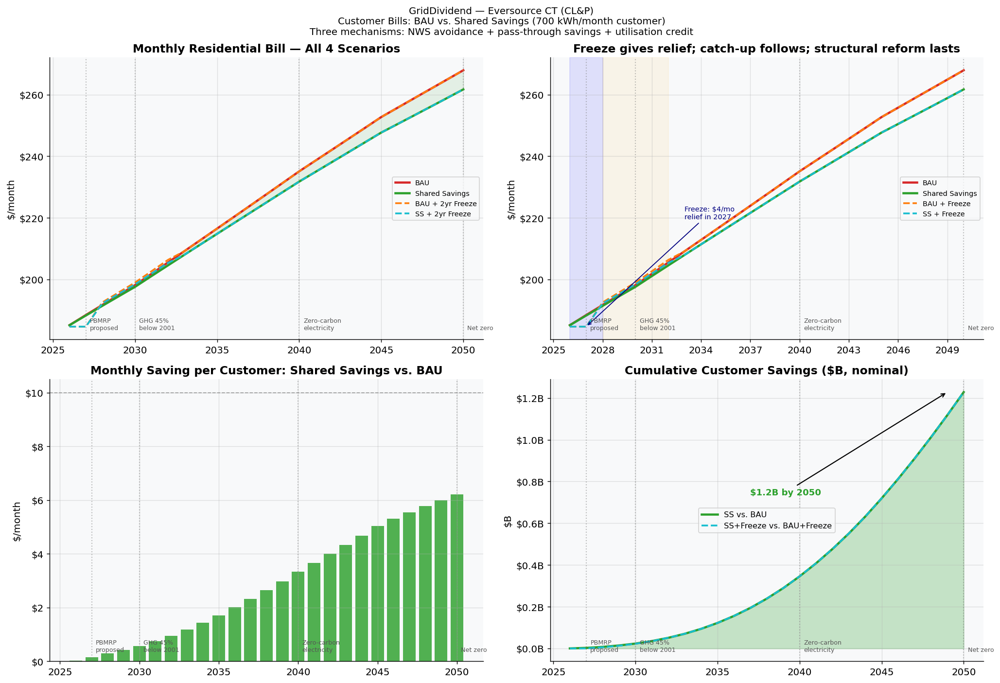


Eversource CT (CL&P) — Bill Results Table (700 kWh/month)
  Year    BAU$/mo    SS$/mo    BAU+Frz    SS+Frz   Saving/yr       %    Cum$B
  ----------------------------------------------------------------------
  2026     185.1    185.1     184.7    184.7          0    0.0%      0.0
  2027     188.4    188.3     184.7    184.7          2    0.1%      0.0
  2028     191.7    191.4     192.5    192.2          4    0.2%      0.0
  2030     198.2    197.6     199.0    198.4          7    0.3%      0.0
  2032     205.5    204.5     206.3    205.4         11    0.5%      0.1
  2035     216.5    214.8     216.5    214.8         21    0.8%      0.1
  2040     235.1    231.8     235.1    231.8         40    1.4%      0.3
  2045     252.7    247.7     252.7    247.7         60    2.0%      0.7
  2050     267.9    261.7     267.9    261.7         75    2.3%      1.2



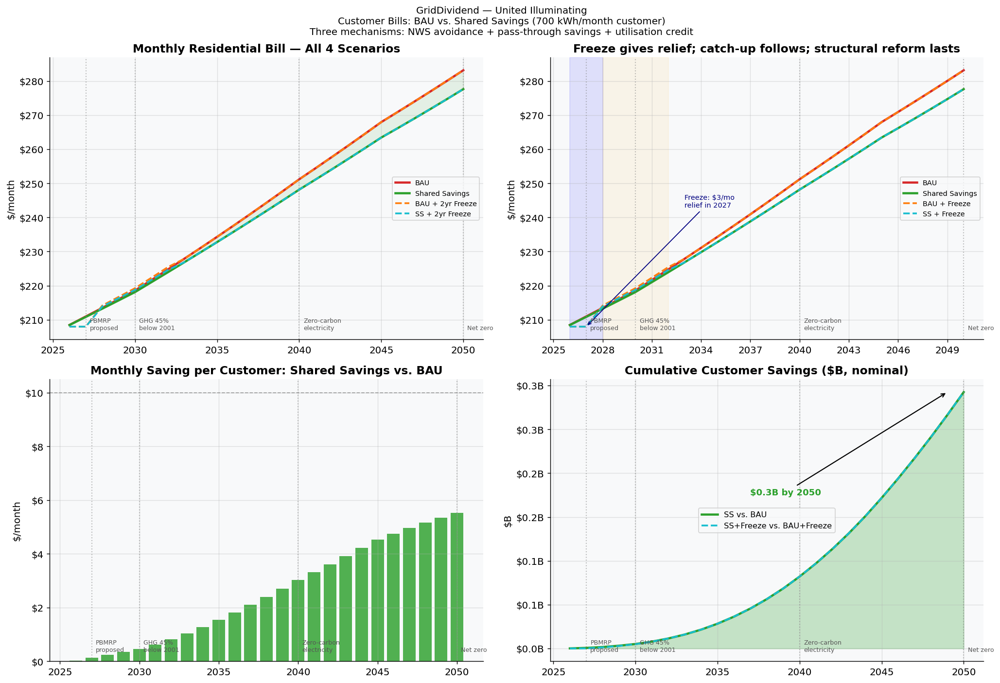


United Illuminating — Bill Results Table (700 kWh/month)
  Year    BAU$/mo    SS$/mo    BAU+Frz    SS+Frz   Saving/yr       %    Cum$B
  ----------------------------------------------------------------------
  2026     208.5    208.4     208.0    208.0          0    0.0%      0.0
  2027     211.0    210.8     208.0    208.0          2    0.1%      0.0
  2028     213.5    213.2     214.2    213.9          3    0.1%      0.0
  2030     218.6    218.1     219.3    218.8          6    0.2%      0.0
  2032     224.7    223.9     225.4    224.6         10    0.4%      0.0
  2035     234.3    232.8     234.3    232.8         18    0.7%      0.0
  2040     251.2    248.2     251.2    248.2         36    1.2%      0.1
  2045     268.0    263.4     268.0    263.4         54    1.7%      0.2
  2050     283.2    277.6     283.2    277.6         66    2.0%      0.3



In [10]:
for k in utilities_to_run:
    bau   = results[k]['bau'];   sh    = results[k]['shared']
    bau_f = results[k]['bau_freeze']; sh_f = results[k]['shared_freeze']
    name  = UTILITIES[k]['short_name']
    p     = utility_data[k]

    ann_sav_mo = bau['avg_monthly_bill'].values - sh['avg_monthly_bill'].values
    ann_sav_yr = bau['avg_annual_bill'].values  - sh['avg_annual_bill'].values
    cum_sav    = np.cumsum(ann_sav_yr * sh['customers'].values / 1e6) / 1000

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle(
        f'GridDividend — {name}\n'
        f'Customer Bills: BAU vs. Shared Savings ({p["residential_kwh_month"]:,.0f} kWh/month customer)\n'
        f'Three mechanisms: NWS avoidance + pass-through savings + utilisation credit',
        fontsize=11)

    # All 4 scenarios — full timeline
    ax = axes[0, 0]
    ax.plot(YEARS, bau['avg_monthly_bill'],   color=C['bau'],          lw=2.5, label='BAU')
    ax.plot(YEARS, sh['avg_monthly_bill'],    color=C['shared'],        lw=2.5, label='Shared Savings')
    ax.plot(YEARS, bau_f['avg_monthly_bill'], color=C['freeze_bau'],   lw=2, ls='--', label='BAU + 2yr Freeze')
    ax.plot(YEARS, sh_f['avg_monthly_bill'],  color=C['freeze_shared'], lw=2, ls='--', label='SS + 2yr Freeze')
    ax.fill_between(YEARS, sh['avg_monthly_bill'], bau['avg_monthly_bill'], alpha=0.10, color=C['shared'])
    vlines(ax)
    ax.set_title('Monthly Residential Bill — All 4 Scenarios')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.legend(fontsize=8)

    # Near-term zoom: freeze effect
    ax = axes[0, 1]
    zoom = list(YEARS)
    filt = lambda df, c: list(df[c])
    ax.plot(zoom, filt(bau,   'avg_monthly_bill'), color=C['bau'],          lw=2.5, label='BAU')
    ax.plot(zoom, filt(sh,    'avg_monthly_bill'), color=C['shared'],        lw=2.5, label='Shared Savings')
    ax.plot(zoom, filt(bau_f, 'avg_monthly_bill'), color=C['freeze_bau'],   lw=2, ls='--', label='BAU + Freeze')
    ax.plot(zoom, filt(sh_f,  'avg_monthly_bill'), color=C['freeze_shared'], lw=2, ls='--', label='SS + Freeze')
    ax.axvspan(2026, 2028, alpha=0.10, color='blue')
    ax.axvspan(2028, 2032, alpha=0.07, color='orange')
    b27  = bau_f[bau_f['year'] == 2027].iloc[0]
    b27n = bau[bau['year']   == 2027].iloc[0]
    relief = b27n['avg_monthly_bill'] - b27['avg_monthly_bill']
    ax.annotate(
        f'Freeze: ${relief:.0f}/mo\nrelief in 2027',
        xy=(2027, b27['avg_monthly_bill']),
        xytext=(2033, b27['avg_monthly_bill'] + 35),
        arrowprops=dict(arrowstyle='->', color='navy', lw=1), fontsize=8, color='navy')
    vlines(ax)
    ax.set_title('Freeze gives relief; catch-up follows; structural reform lasts')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.legend(fontsize=8)

    # Monthly saving bar chart
    ax = axes[1, 0]
    ax.bar(YEARS, ann_sav_mo,
           color=[C['shared'] if s > 0 else C['bau'] for s in ann_sav_mo],
           alpha=0.82, width=0.8)
    ax.axhline(10, color='gray', ls='--', lw=1, alpha=0.7)
    over10 = np.where(ann_sav_mo > 10)[0]
    if len(over10):
        first_i = over10[0]
        ax.annotate(f'$10/mo saving\nreached in {YEARS[first_i]}',
                    xy=(YEARS[first_i], ann_sav_mo[first_i]),
                    xytext=(YEARS[first_i] + 3, ann_sav_mo[first_i] + ann_sav_mo.max() * 0.15),
                    arrowprops=dict(arrowstyle='->', color='navy', lw=1),
                    fontsize=8, color='navy')
    vlines(ax)
    ax.set_title('Monthly Saving per Customer: Shared Savings vs. BAU')
    ax.set_ylabel('$/month')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

    # Cumulative savings
    ax = axes[1, 1]
    ax.fill_between(YEARS, 0, cum_sav, alpha=0.25, color=C['shared'])
    ax.plot(YEARS, cum_sav, color=C['shared'], lw=2.5, label='SS vs. BAU')
    ann_sav_f = bau_f['avg_annual_bill'].values - sh_f['avg_annual_bill'].values
    cum_sav_f = np.cumsum(ann_sav_f * sh_f['customers'].values / 1e6) / 1000
    ax.plot(YEARS, cum_sav_f, color=C['freeze_shared'], lw=2, ls='--', label='SS+Freeze vs. BAU+Freeze')
    vlines(ax)
    ax.set_title('Cumulative Customer Savings ($B, nominal)')
    ax.set_ylabel('$B')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}B'))
    final = cum_sav[-1]
    ax.annotate(f'${final:.1f}B by 2050', xy=(2049, final), xytext=(2037, final * 0.6),
        arrowprops=dict(arrowstyle='->', color='black', lw=1.2),
        fontsize=10, fontweight='bold', color=C['shared'])
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(f'charts/chart1_bills_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    # Results table
    print(f"\n{name} — Bill Results Table ({p['residential_kwh_month']:,.0f} kWh/month)")
    print(f"  {'Year':>4}  {'BAU$/mo':>9}  {'SS$/mo':>8}  {'BAU+Frz':>9}  {'SS+Frz':>8}"
          f"  {'Saving/yr':>10}  {'%':>6}  {'Cum$B':>7}")
    print("  " + "-" * 70)
    for yr in [2026, 2027, 2028, 2030, 2032, 2035, 2040, 2045, 2050]:
        br  = bau[bau['year']   == yr].iloc[0]
        sr  = sh[sh['year']    == yr].iloc[0]
        brf = bau_f[bau_f['year'] == yr].iloc[0]
        srf = sh_f[sh_f['year']  == yr].iloc[0]
        sv  = br['avg_annual_bill'] - sr['avg_annual_bill']
        idx = YEARS.index(yr)
        cumv = np.sum(
            (bau['avg_annual_bill'].values[:idx+1] - sh['avg_annual_bill'].values[:idx+1])
            * sh['customers'].values[:idx+1]) / 1e9
        print(f"  {yr:4d}   {br['avg_monthly_bill']:>7,.1f}   {sr['avg_monthly_bill']:>6,.1f}"
              f"   {brf['avg_monthly_bill']:>7,.1f}   {srf['avg_monthly_bill']:>6,.1f}"
              f"   {sv:>8,.0f}   {sv/br['avg_annual_bill']:>5.1%}   {cumv:>6.1f}")
    print()

## Section 6: Infrastructure Spending — CAPEX & OPEX

CL&P's distribution capital programme (~$549M in 2025, rising toward $800M a year by 2029 on Eversource's statements) and UI's much smaller one (~$70M a year after its 2025 capital cut) are mostly reliability, resilience and asset-condition work. Only a small share (18% rising to 30%) is treated as NWS-eligible.


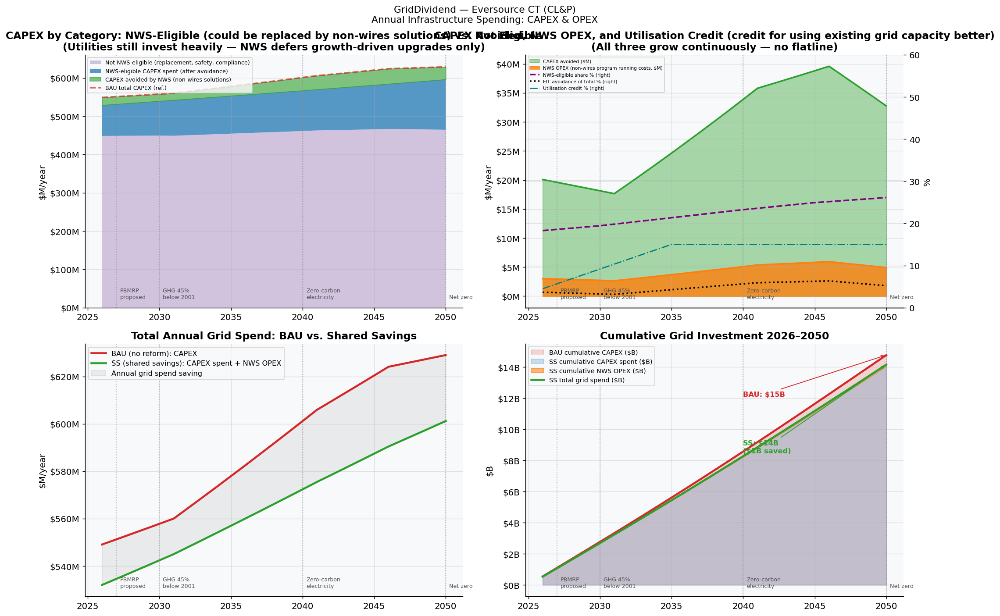


Eversource CT (CL&P) — CAPEX & NWS OPEX Table
  Year    BAU CAPEX    Elig%    Avoided    SS Spent    NWS OPEX   Eff.Avoid%
  ------------------------------------------------------------------------
  2026         549    18.3%       20        529          3         3.7%
  2028         553    18.9%       19        534          3         3.5%
  2030         558    19.4%       18        540          3         3.3%
  2035         578    21.3%       25        553          4         4.3%
  2040         601    23.3%       34        567          5         5.6%
  2045         620    24.9%       39        582          6         6.3%
  2050         629    26.1%       33        596          5         5.2%



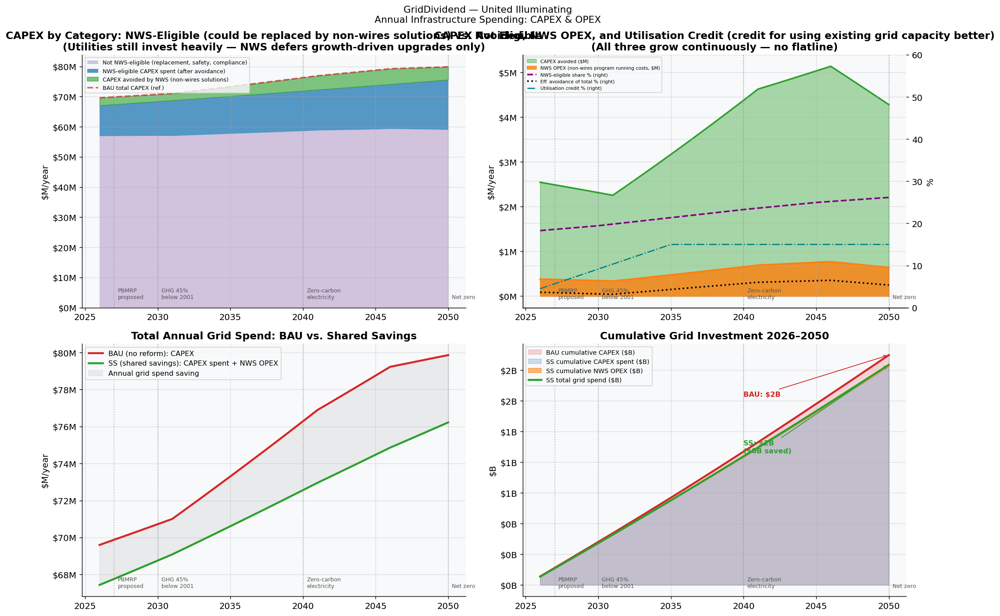


United Illuminating — CAPEX & NWS OPEX Table
  Year    BAU CAPEX    Elig%    Avoided    SS Spent    NWS OPEX   Eff.Avoid%
  ------------------------------------------------------------------------
  2026          70    18.3%        3         67          0         3.7%
  2028          70    18.9%        2         68          0         3.5%
  2030          71    19.4%        2         68          0         3.3%
  2035          73    21.4%        3         70          0         4.3%
  2040          76    23.3%        4         72          1         5.7%
  2045          79    25.0%        5         74          1         6.4%
  2050          80    26.2%        4         76          1         5.4%



In [11]:
for k in utilities_to_run:
    bau  = results[k]['bau']; sh = results[k]['shared']
    name = UTILITIES[k]['short_name']
    bau_cum    = np.cumsum(bau['capex_spent_m'].values)
    ss_cum     = np.cumsum(sh['capex_spent_m'].values)
    ss_nws_cum = np.cumsum(sh['nws_opex_m'].values)

    fig, axes = plt.subplots(2, 2, figsize=(16, 11))
    fig.suptitle(f'GridDividend — {name}\nAnnual Infrastructure Spending: CAPEX & OPEX', fontsize=12)

    ax = axes[0, 0]
    ax.stackplot(YEARS, sh['capex_ineligible_m'],
                 sh['capex_spent_m'] - sh['capex_ineligible_m'],
                 labels=['Not NWS-eligible (replacement, safety, compliance)',
                         'NWS-eligible CAPEX spent (after avoidance)'],
                 colors=[C['ineligible'], C['capex_spent']], alpha=0.75)
    ax.fill_between(YEARS, sh['capex_spent_m'], sh['capex_total_programme_m'],
                    alpha=0.60, color=C['capex_avoided'], label='CAPEX avoided by NWS (non-wires solutions)')
    ax.plot(YEARS, bau['capex_spent_m'], color=C['bau'], lw=2, ls='--', alpha=0.7,
            label='BAU total CAPEX (ref.)')
    vlines(ax)
    ax.set_title('CAPEX by Category: NWS-Eligible (could be replaced by non-wires solutions) vs. Not Eligible\n'
                 '(Utilities still invest heavily — NWS defers growth-driven upgrades only)')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=7, loc='upper left')

    ax = axes[0, 1]
    ax2 = ax.twinx()
    ax.fill_between(YEARS, 0, sh['capex_avoided_m'], alpha=0.40, color=C['capex_avoided'],
                    label='CAPEX avoided ($M)')
    ax.fill_between(YEARS, 0, sh['nws_opex_m'], alpha=0.80, color=C['opex_nws'],
                    label='NWS OPEX (non-wires program running costs, $M)')
    ax.plot(YEARS, sh['capex_avoided_m'], color=C['capex_avoided'], lw=2)
    ax.plot(YEARS, sh['nws_opex_m'],      color=C['opex_nws'],      lw=2)
    ax2.plot(YEARS, sh['nws_eligible_share_pct'],       color='purple', lw=2, ls='--',
             label='NWS-eligible share % (right)')
    ax2.plot(YEARS, sh['capex_avoidance_pct_of_total'], color='black',  lw=2, ls=':',
             label='Eff. avoidance of total % (right)')
    ax2.plot(YEARS, sh['utilisation_credit_pct'].values,
             color='teal', lw=1.5, ls='-.', label='Utilisation credit % (right)')
    ax2.set_ylim(0, 60); ax2.set_ylabel('%')
    vlines(ax)
    ax.set_title('CAPEX Avoided, NWS OPEX, and Utilisation Credit (credit for using existing grid capacity better)\n'
                 '(All three grow continuously — no flatline)')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    l1, lb1 = ax.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
    ax.legend(l1 + l2, lb1 + lb2, fontsize=6, loc='upper left')

    ax = axes[1, 0]
    ax.plot(YEARS, bau['capex_spent_m'],    color=C['bau'],    lw=2.5, label='BAU (no reform): CAPEX')
    ax.plot(YEARS, sh['total_grid_spend_m'], color=C['shared'], lw=2.5,
            label='SS (shared savings): CAPEX spent + NWS OPEX')
    ax.fill_between(YEARS, sh['total_grid_spend_m'], bau['capex_spent_m'],
                    alpha=0.13, color=C['neutral'], label='Annual grid spend saving')
    vlines(ax)
    ax.set_title('Total Annual Grid Spend: BAU vs. Shared Savings')
    ax.set_ylabel('$M/year')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 1]
    ax.fill_between(YEARS, 0, bau_cum / 1000, alpha=0.18, color=C['bau'],
                    label='BAU cumulative CAPEX ($B)')
    ax.fill_between(YEARS, 0, ss_cum / 1000, alpha=0.22, color=C['capex_spent'],
                    label='SS cumulative CAPEX spent ($B)')
    ax.fill_between(YEARS, ss_cum / 1000, (ss_cum + ss_nws_cum) / 1000, alpha=0.55,
                    color=C['opex_nws'], label='SS cumulative NWS OPEX ($B)')
    ax.plot(YEARS, bau_cum / 1000, color=C['bau'], lw=2.5)
    ax.plot(YEARS, (ss_cum + ss_nws_cum) / 1000, color=C['shared'], lw=2.5,
            label='SS total grid spend ($B)')
    b2050 = bau_cum[-1] / 1000; s2050 = (ss_cum[-1] + ss_nws_cum[-1]) / 1000
    ax.annotate(f'BAU: ${b2050:.0f}B', xy=(2050, b2050), xytext=(2040, b2050 * 0.82),
        arrowprops=dict(arrowstyle='->', color=C['bau'], lw=1),
        fontsize=9, color=C['bau'], fontweight='bold')
    ax.annotate(f'SS: ${s2050:.0f}B\n(${b2050-s2050:.0f}B saved)',
        xy=(2050, s2050), xytext=(2040, s2050 * 0.60),
        arrowprops=dict(arrowstyle='->', color=C['shared'], lw=1),
        fontsize=9, color=C['shared'], fontweight='bold')
    vlines(ax)
    ax.set_title('Cumulative Grid Investment 2026–2050')
    ax.set_ylabel('$B')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.0f}B'))
    ax.legend(fontsize=8)

    plt.tight_layout()
    plt.savefig(f'charts/chart2_capex_opex_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    print(f"\n{name} — CAPEX & NWS OPEX Table")
    print(f"  {'Year':>4}  {'BAU CAPEX':>11}  {'Elig%':>7}  {'Avoided':>9}  "
          f"{'SS Spent':>10}  {'NWS OPEX':>10}  {'Eff.Avoid%':>11}")
    print("  " + "-" * 72)
    for yr in [2026, 2028, 2030, 2035, 2040, 2045, 2050]:
        br = bau[bau['year'] == yr].iloc[0]; sr = sh[sh['year'] == yr].iloc[0]
        print(f"  {yr:4d}   {br['capex_spent_m']:>9,.0f}  "
              f"{sr['nws_eligible_share_pct']:>6.1f}%  "
              f"{sr['capex_avoided_m']:>7,.0f}   "
              f"{sr['capex_spent_m']:>8,.0f}   "
              f"{sr['nws_opex_m']:>8,.0f}   "
              f"{sr['capex_avoidance_pct_of_total']:>9.1f}%")
    print()

## Section 7: Utility Financial Results

Under shared savings, utility revenue exceeds BAU in the **early years** of the programme — the period when the utility most needs the commercial incentive to build NWS capabilities. As the avoided rate base accumulates, the compounding effect of foregone traditional earnings creates a crossover around the mid-2030s. This underscores why regulatory design matters: the shared savings percentage, performance corridor, and ROE framework need to be calibrated to keep the utility commercially motivated throughout the programme, not just in its early years.

**The early-year arithmetic:** the utility earns ~25¢ of shared savings income per $1 of deferred CAPEX but loses only ~7¢ in traditional earnings — a net benefit of ~18¢ per deferred dollar. This is what makes the reform commercially viable in its critical early phase.

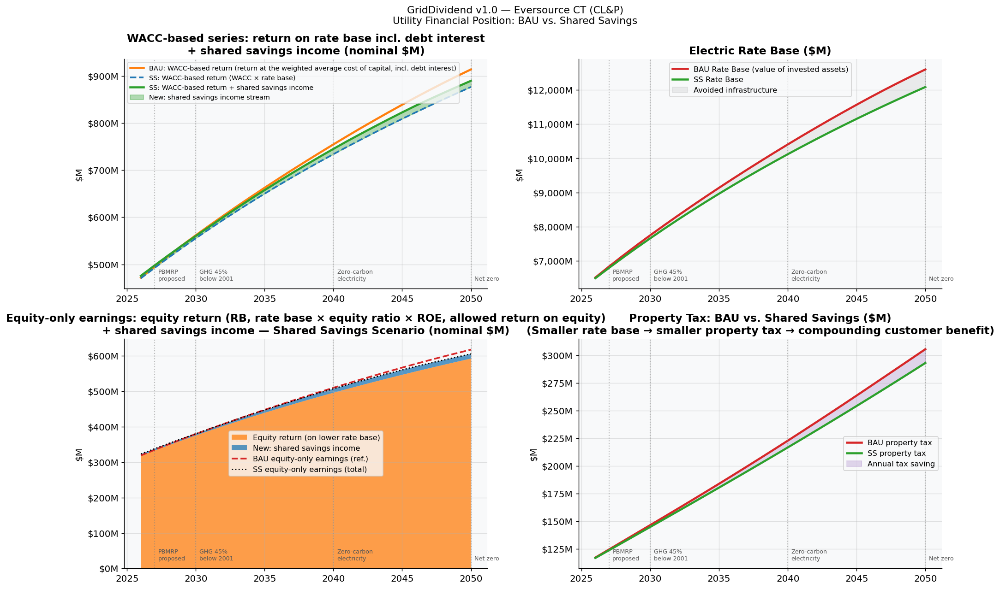

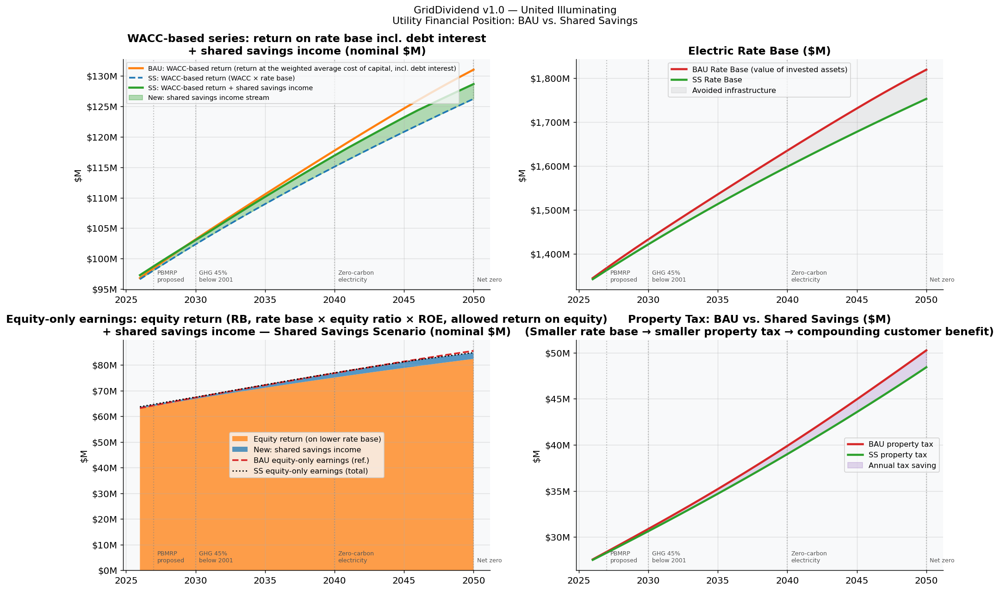

In [12]:
for k in utilities_to_run:
    bau  = results[k]['bau']; sh = results[k]['shared']
    name = UTILITIES[k]['short_name']

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle(f'GridDividend v1.0 — {name}\nUtility Financial Position: BAU vs. Shared Savings',
                 fontsize=12)

    ax = axes[0, 0]
    ax.plot(YEARS, bau['total_utility_revenue_m'], color=C['util_bau'], lw=2.5, label='BAU: WACC-based return (return at the weighted average cost of capital, incl. debt interest)')
    ax.plot(YEARS, sh['traditional_earnings_m'], color=C['util_shared'], lw=2, ls='--',
            label='SS: WACC-based return (WACC × rate base)')
    ax.plot(YEARS, sh['total_utility_revenue_m'], color=C['shared'], lw=2.5,
            label='SS: WACC-based return + shared savings income')
    ax.fill_between(YEARS, sh['traditional_earnings_m'], sh['total_utility_revenue_m'],
                    alpha=0.35, color=C['shared'], label='New: shared savings income stream')
    vlines(ax)
    ax.set_title('WACC-based series: return on rate base incl. debt interest\n'
                 '+ shared savings income (nominal $M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=8, loc='upper left')

    ax = axes[0, 1]
    ax.plot(YEARS, bau['rate_base_m'], color=C['bau'],    lw=2.5, label='BAU Rate Base (value of invested assets)')
    ax.plot(YEARS, sh['rate_base_m'],  color=C['shared'], lw=2.5, label='SS Rate Base')
    ax.fill_between(YEARS, sh['rate_base_m'], bau['rate_base_m'],
                    alpha=0.13, color=C['neutral'], label='Avoided infrastructure')
    vlines(ax)
    ax.set_title('Electric Rate Base ($M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 0]
    ax.stackplot(YEARS, sh['roe_earnings_m'], sh['utility_shared_revenue_m'],
        labels=['Equity return (on lower rate base)', 'New: shared savings income'],
        colors=[C['util_bau'], C['util_shared']], alpha=0.75)
    ax.plot(YEARS, bau['equity_earnings_m'], color=C['bau'], lw=2, ls='--',
            label='BAU equity-only earnings (ref.)')
    ax.plot(YEARS, sh['equity_earnings_m'], color='black', lw=1.5, ls=':',
            label='SS equity-only earnings (total)')
    vlines(ax)
    ax.set_title('Equity-only earnings: equity return (RB, rate base × equity ratio × ROE, allowed return on equity)\n'
                 '+ shared savings income — Shared Savings Scenario (nominal $M)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    ax = axes[1, 1]
    ax.plot(YEARS, bau['property_tax_m'], color=C['bau'],    lw=2.5, label='BAU property tax')
    ax.plot(YEARS, sh['property_tax_m'],  color=C['shared'], lw=2.5, label='SS property tax')
    ax.fill_between(YEARS, sh['property_tax_m'], bau['property_tax_m'],
                    alpha=0.25, color=C['tax'], label='Annual tax saving')
    vlines(ax)
    ax.set_title('Property Tax: BAU vs. Shared Savings ($M)\n'
                 '(Smaller rate base → smaller property tax → compounding customer benefit)')
    ax.set_ylabel('$M')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(f'charts/chart3_utility_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

## Section 8: Sensitivity Analysis

Tests how results change across parameter ranges. Dot = default value.

**Note on parameter correlation:** The analysis below varies one parameter at a time, holding all others constant. In practice many parameters are correlated — high electrification growth tends to increase NWS opportunity but also increases operational complexity and may reduce effective avoidance rates; higher DER penetration is both a driver of flexibility and a source of dispatch uncertainty. A full probabilistic analysis using Monte Carlo methods with correlated parameter draws would produce wider confidence intervals than the ranges shown here. The single-variable sensitivity charts should be read as illustrating which parameters matter most, not as bounding the full range of possible outcomes.

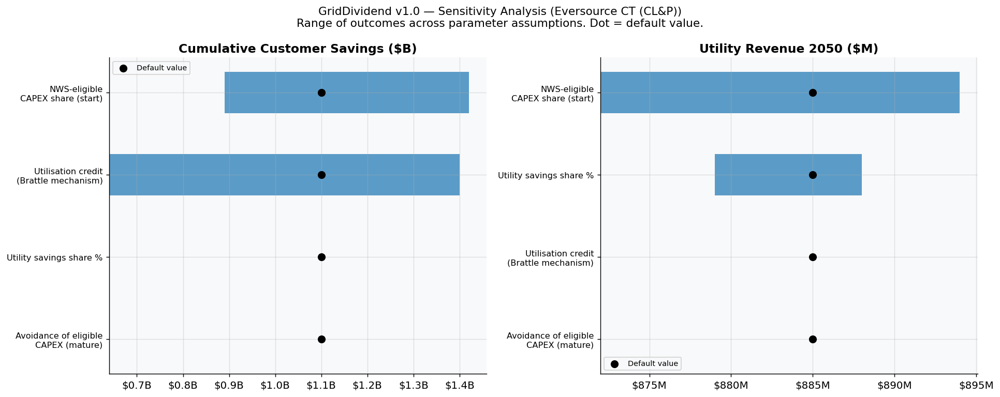

In [13]:
from engine import config_with
PARAM_DEFAULTS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   NWS_ELIGIBLE_CAPEX_SHARE_START,   # 0.18 (Eversource_CT.json)
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': 0.80,
    'UTILITY_SAVINGS_SHARE':            0.30,
    'FLEX_LOAD_UTILISATION_SHARE_SS':   0.15,
}
SENSITIVITY_RUNS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   [0.10, 0.15, 0.18, 0.25, 0.30],
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': [0.50, 0.65, 0.80, 0.90],
    'UTILITY_SAVINGS_SHARE':            [0.10, 0.20, 0.30, 0.40],
    'FLEX_LOAD_UTILISATION_SHARE_SS':   [0.00, 0.08, 0.15, 0.25],
}
PARAM_LABELS = {
    'NWS_ELIGIBLE_CAPEX_SHARE_START':   'NWS-eligible\nCAPEX share (start)',
    'NWS_AVOIDANCE_OF_ELIGIBLE_MATURE': 'Avoidance of eligible\nCAPEX (mature)',
    'UTILITY_SAVINGS_SHARE':            'Utility savings share %',
    'FLEX_LOAD_UTILISATION_SHARE_SS':   'Utilisation credit\n(Brattle mechanism)',
}

k = utilities_to_run[0]
p = utility_data[k]; bau_df = results[k]['bau']
all_sens = []
for pname, pvals in SENSITIVITY_RUNS.items():
    recs = []
    for val in pvals:
        cfg = config_with(MODEL_CONFIG, **{pname: val})   # explicit override beats utility JSON
        s = project(p, 'shared', config=cfg)
        cum_b = np.sum((bau_df['avg_annual_bill'].values - s['avg_annual_bill'].values)
                       * s['customers'].values) / 1e9
        ur = s[s['year'] == 2050]['total_utility_revenue_m'].values[0]
        recs.append({'parameter': pname, 'value': val, 'cum_b': round(cum_b, 2), 'ur': round(ur, 0)})
    all_sens.append(pd.DataFrame(recs))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(
    f'GridDividend v1.0 — Sensitivity Analysis ({UTILITIES[k]["short_name"]})\n'
    f'Range of outcomes across parameter assumptions. Dot = default value.',
    fontsize=12)

for ci, (metric, title) in enumerate([
    ('cum_b', 'Cumulative Customer Savings ($B)'),
    ('ur',    'Utility Revenue 2050 ($M)')]):
    ax = axes[ci]; ranges = []
    for s in all_sens:
        pname   = s['parameter'].iloc[0]
        default = PARAM_DEFAULTS[pname]
        lo = s[metric].min(); hi = s[metric].max()
        dr = s[abs(s['value'] - default) < 1e-9]
        mid = dr[metric].values[0] if len(dr) else (lo + hi) / 2
        ranges.append({'label': PARAM_LABELS[pname], 'lo': lo, 'hi': hi, 'mid': mid})
    rdf = pd.DataFrame(ranges).sort_values('hi', ascending=True)
    yp  = list(range(len(rdf)))
    ax.barh(yp, rdf['hi'] - rdf['lo'], left=rdf['lo'],
            color=C['util_shared'], alpha=0.72, height=0.5)
    ax.scatter(rdf['mid'], yp, color='black', zorder=5, s=55, label='Default')
    ax.set_yticks(yp); ax.set_yticklabels(rdf['label'], fontsize=9)
    ax.set_title(title)
    if metric == 'cum_b':
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:.1f}B'))
    else:
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}M'))
    ax.legend(['Default value'], fontsize=8)

plt.tight_layout()
plt.savefig('charts/chart4_sensitivity.png', bbox_inches='tight', dpi=130)
plt.show()

## Section 8b: ROE Sweep

Tests how lower allowed returns on equity interact with the shared-savings mechanism. For each utility, ROE runs from the rate-case value down to 7.0% in 0.5-point steps. Values below the rate case are an **illustrative market-return range**, not an auction-clearing rate. At each ROE the model runs BAU and the EASE Case (BASE scenario, with capacity pass-through applied as in Section 4). It sweeps `UTILITY_SAVINGS_SHARE` over 10–30% under both `SAVINGS_POOL_BASIS` values.

- **(a)** 2×2 quadrant: rate-case ROE vs 7.0% × BAU vs EASE Case, showing cumulative saving per customer against the status quo (rate-case ROE, BAU).
- **(b)** Cumulative saving per customer vs ROE.
- **(c)** Minimum incentive-compatible utility share vs ROE (cumulative utility earnings ≥ BAU over 10 and 25 years).
- **(d)** Year utility earnings fall permanently below BAU vs ROE.

Utility earnings = equity return on rate base + shared-savings income. Every dollar figure is labelled as undiscounted nominal or NPV (base year 2026). Charts are saved to `charts_article/roe_sweep_*_{utility keys}.png`.

**CORRECTED preset (continuation cell).** Section 8b's second cell reruns the sweep under the `CORRECTED` preset: depreciation in delivery RR, the `'revenue_requirement'` pool, negative pools carried forward, and bills indexed to BAU 2026. It runs once per `NWS_COST_TREATMENT` (`'expense'`, `'capitalise'`), with the utility share running 0–50%. It also prints the 2026 delivery revenue requirement reconciliation. `CORRECTED` is not the model default. Parts (a)–(d) above use `MODEL_CONFIG` as set in Section 1.

⚠ Eversource CT (CL&P): results are ILLUSTRATIVE — 8 parameters are flagged _VERIFY in the utility JSON.
⚠ Eversource CT (CL&P): results are PROVISIONAL — PURA Docket 17-10-46 (2018 settlement, approved 18 Apr 2018; rates in force May 2018 - 2026, base rates frozen to at least 1 Jan 2024 by the 2021 settlement); Docket 26-05-10 pending (filed 14 Jul 2026; decision expected mid-2027).
⚠ United Illuminating: results are ILLUSTRATIVE — 8 parameters are flagged _VERIFY in the utility JSON.

ROE sweep: 6,000 rows (utility × ROE × share × pool basis × scenario × year).
ROE values below the rate-case figure are an illustrative market-return range.

Eversource CT (CL&P) — Pool basis: 'capex' (v1.0) — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, undiscounted nominal $:


,BAU,EASE Case
Rate-case ROE 9.2%,$0,$856
Illustrative 7.0%,"$2,449","$3,224"


Eversource CT (CL&P) — Pool basis: 'capex' (v1.0) — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, NPV at 3% (2026 $):


,BAU,EASE Case
Rate-case ROE 9.2%,$0,$523
Illustrative 7.0%,"$1,687","$2,160"


Eversource CT (CL&P) — Pool basis: 'revenue_requirement' — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, undiscounted nominal $:


,BAU,EASE Case
Rate-case ROE 9.2%,$0,$725
Illustrative 7.0%,"$2,449","$3,109"


... (8 outputs left out)

United Illuminating — Pool basis: 'revenue_requirement' — share 30%
  Cumulative bill saving per customer vs status quo (rate-case ROE, BAU), 2026–2050, NPV at 3% (2026 $):


,BAU,EASE Case
Rate-case ROE 9.4%,$0,$408
Illustrative 7.0%,"$1,422","$1,802"


Headline metrics at UTILITY_SAVINGS_SHARE = 30%:


,utility,pool_basis,roe,EASE bill 2030 ($/mo nominal),EASE bill 2040 ($/mo nominal),EASE bill 2050 ($/mo nominal),Cum saving/cust vs BAU (undiscounted nominal $),"Cum saving/cust vs BAU (NPV 3%, 2026 $)","Cum saving/cust vs BAU (NPV 7%, 2026 $)",crossover_year,Yrs 1-3 net utility gain per $ deferred (nominal),Shared income / total earnings (25-yr),min_share_10y,min_share_25y
4,EversourceCT,capex,0.092,197.598,231.757,261.695,856.329,523.020,288.588,2031.0,0.166,0.020,0.249,0.393
9,EversourceCT,revenue_requirement,0.092,197.668,232.289,262.584,725.144,443.139,244.819,2026.0,-0.081,0.017,0.609,0.461
14,EversourceCT,capex,0.090,196.888,230.828,260.592,847.268,517.459,285.495,2032.0,0.168,0.021,0.242,0.383
19,EversourceCT,revenue_requirement,0.090,196.956,231.353,261.468,717.934,438.720,242.368,2026.0,-0.079,0.017,0.603,0.454
24,EversourceCT,capex,0.085,195.466,228.970,258.386,829.146,506.336,279.310,2034.0,0.173,0.022,0.229,0.361
29,EversourceCT,revenue_requirement,0.085,195.531,229.481,259.236,703.512,429.882,237.466,2026.0,-0.075,0.018,0.589,0.440
34,EversourceCT,capex,0.080,194.045,227.112,256.180,811.024,495.214,273.125,2037.0,0.179,0.023,0.215,0.340
39,EversourceCT,revenue_requirement,0.080,194.106,227.609,257.003,689.090,421.043,232.564,2026.0,-0.072,0.019,0.574,0.425
44,EversourceCT,capex,0.075,192.623,225.254,253.974,792.902,484.091,266.939,2040.0,0.184,0.025,0.202,0.319
49,EversourceCT,revenue_requirement,0.075,192.681,225.738,254.771,674.667,412.204,227.661,2026.0,-0.068,0.019,0.558,0.409


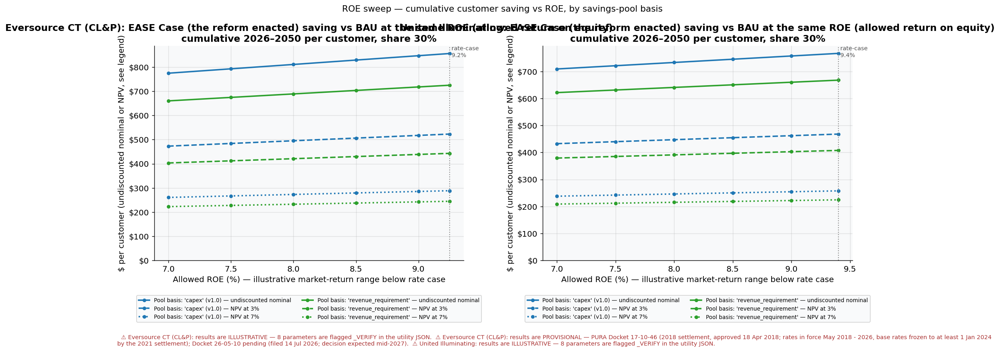

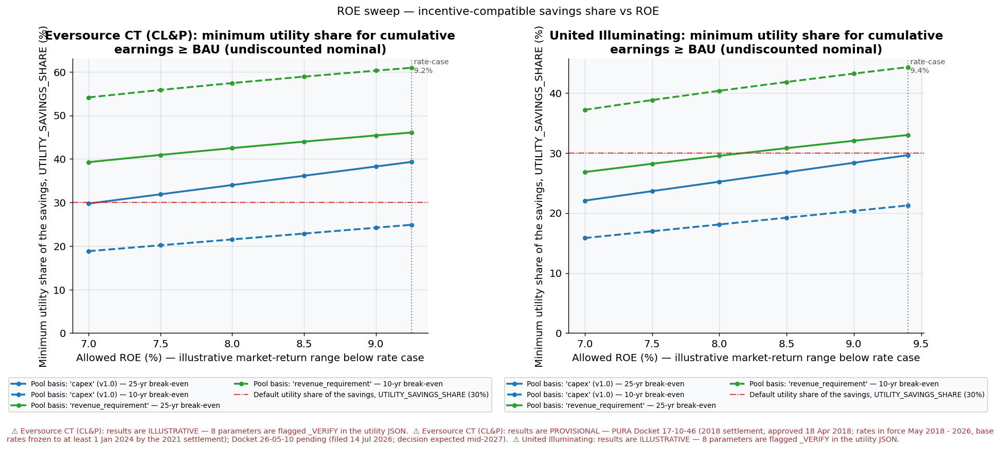

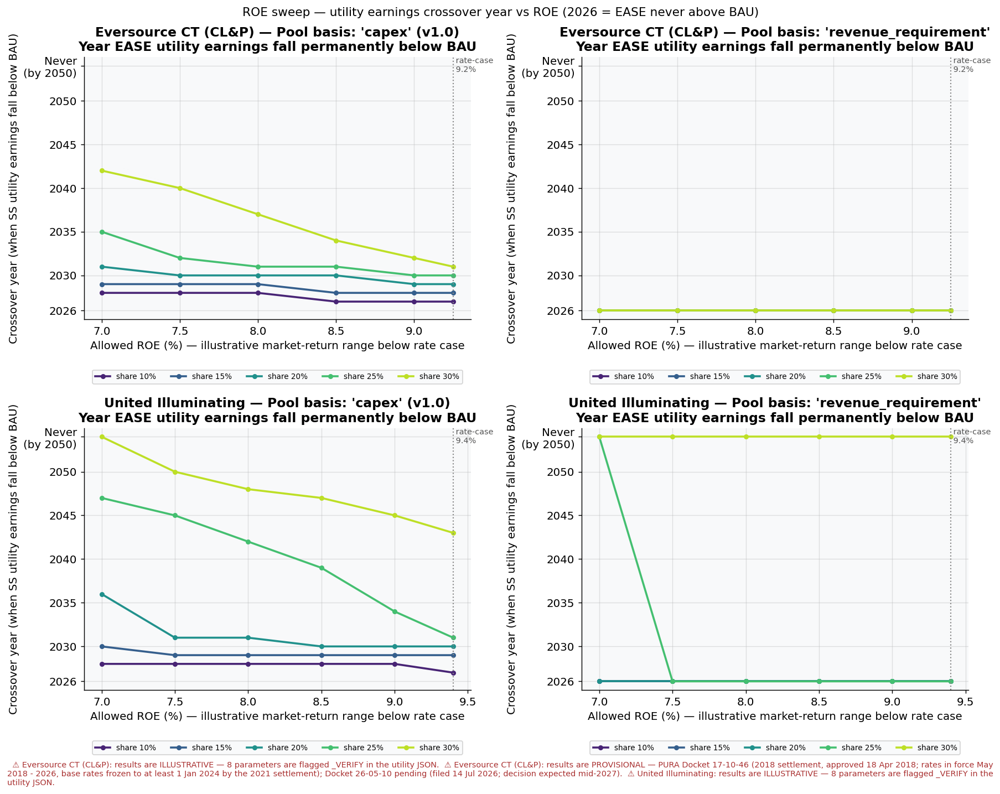

In [14]:
# ============================================================
# SECTION 8b: ROE SWEEP
# How lower allowed returns interact with the shared-savings mechanism.
# Engine: engine/roe_sweep.py. ROE values below the rate-case figure form an
# ILLUSTRATIVE MARKET-RETURN RANGE — none is an auction-clearing rate.
# Utility earnings = equity return (rate base × equity ratio × ROE)
#                    + shared-savings income.
# ============================================================
from engine.roe_sweep import (run_roe_sweep, compute_roe_metrics, quadrant_table,
                              data_quality_flags)
os.makedirs('charts_article', exist_ok=True)

ROE_SWEEP_FLOOR  = 0.070                           # bottom of illustrative range
ROE_SWEEP_STEP   = 0.005
ROE_SWEEP_SHARES = (0.10, 0.15, 0.20, 0.25, 0.30)  # UTILITY_SAVINGS_SHARE values
DEFAULT_SHARE    = MODEL_CONFIG['UTILITY_SAVINGS_SHARE']
BASIS_LABEL  = {'capex': "Pool basis: 'capex' (v1.0)",
                'revenue_requirement': "Pool basis: 'revenue_requirement'"}
BASIS_COLOUR = {'capex': C['util_shared'], 'revenue_requirement': C['shared']}

roe_sweep_df = run_roe_sweep(utility_data, MODEL_CONFIG, utilities_to_run,
                             scenario_def=SCENARIO_DEFS['BASE'],
                             shares=ROE_SWEEP_SHARES, roe_floor=ROE_SWEEP_FLOOR,
                             roe_step=ROE_SWEEP_STEP)
roe_metrics = compute_roe_metrics(roe_sweep_df)
flags = data_quality_flags(UTILITIES, utilities_to_run)
flag_note = ('  ⚠ ' + '  ⚠ '.join(flags)) if flags else ''
for f in flags:
    print('⚠', f)
print(f"\nROE sweep: {len(roe_sweep_df):,} rows "
      "(utility × ROE × share × pool basis × scenario × year).")
print("ROE values below the rate-case figure are an illustrative market-return range.\n")

# ── (a) 2×2 quadrant: rate-case ROE vs 7.0%, BAU vs EASE Case ─────────────────
for k in utilities_to_run:
    name = UTILITIES[k]['short_name']
    for basis in ['capex', 'revenue_requirement']:
        for col, lbl in [('nominal', 'undiscounted nominal $'), ('npv3', 'NPV at 3% (2026 $)')]:
            print(f"{name} — {BASIS_LABEL[basis]} — share {DEFAULT_SHARE:.0%}\n"
                  f"  Cumulative bill saving per customer vs status quo "
                  f"(rate-case ROE, BAU), 2026–2050, {lbl}:")
            q = quadrant_table(roe_metrics, k, basis, share=DEFAULT_SHARE,
                               roe_low=ROE_SWEEP_FLOOR, column=col)
            display(q.round(0).astype(int).apply(lambda s: s.map(lambda v: f'${v:,}')))

# ── Headline metrics at the default share ─────────────────────────────────────
show = roe_metrics[np.isclose(roe_metrics['share'], DEFAULT_SHARE)][[
    'utility', 'pool_basis', 'roe', 'ease_bill_2030', 'ease_bill_2040', 'ease_bill_2050',
    'cum_saving_nominal', 'cum_saving_npv3', 'cum_saving_npv7', 'crossover_year',
    'early_net_per_deferred_$', 'ss_income_share_of_earnings',
    'min_share_10y', 'min_share_25y']].rename(columns={
        'ease_bill_2030': 'EASE bill 2030 ($/mo nominal)',
        'ease_bill_2040': 'EASE bill 2040 ($/mo nominal)',
        'ease_bill_2050': 'EASE bill 2050 ($/mo nominal)',
        'cum_saving_nominal': 'Cum saving/cust vs BAU (undiscounted nominal $)',
        'cum_saving_npv3': 'Cum saving/cust vs BAU (NPV 3%, 2026 $)',
        'cum_saving_npv7': 'Cum saving/cust vs BAU (NPV 7%, 2026 $)',
        'early_net_per_deferred_$': 'Yrs 1-3 net utility gain per $ deferred (nominal)',
        'ss_income_share_of_earnings': 'Shared income / total earnings (25-yr)'})
print(f"Headline metrics at UTILITY_SAVINGS_SHARE = {DEFAULT_SHARE:.0%}:")
display(show.round(3))

def _fmt_roe_axis(ax, k):
    rc = utility_data[k]['roe']
    ax.axvline(rc * 100, color=C['neutral'], ls=':', lw=1.2)
    ax.text(rc * 100, ax.get_ylim()[1], f' rate-case\n {rc:.1%}', fontsize=8,
            color='#555', va='top')
    ax.set_xlabel('Allowed ROE (%) — illustrative market-return range below rate case')

def _save(fig, fname):
    fig.text(0.01, -0.02, flag_note, fontsize=8, color='#a33', ha='left', wrap=True)
    plt.tight_layout()
    plt.savefig(f'charts_article/{fname}_{UTIL_TAG}.png', bbox_inches='tight', dpi=300)
    plt.show()

n = len(utilities_to_run)
UTIL_TAG = '_'.join(k.lower() for k in utilities_to_run)   # e.g. coned_rge
d = roe_metrics[np.isclose(roe_metrics['share'], DEFAULT_SHARE)]

# ── (b) Cumulative saving per customer vs ROE ─────────────────────────────────
fig, axes = plt.subplots(1, n, figsize=(7.5 * n, 6.5), squeeze=False)
for ax, k in zip(axes[0], utilities_to_run):
    for basis in ['capex', 'revenue_requirement']:
        s = d[(d['utility'] == k) & (d['pool_basis'] == basis)].sort_values('roe')
        for col, ls, lbl in [('cum_saving_nominal', '-', 'undiscounted nominal'),
                             ('cum_saving_npv3', '--', 'NPV at 3%'),
                             ('cum_saving_npv7', ':', 'NPV at 7%')]:
            ax.plot(s['roe'] * 100, s[col], color=BASIS_COLOUR[basis], ls=ls, lw=2,
                    marker='o', ms=4, label=f"{BASIS_LABEL[basis]} — {lbl}")
    ax.set_title(f"{UTILITIES[k]['short_name']}: EASE Case (the reform enacted) saving vs BAU at the same ROE (allowed return on equity)\n"
                 f"cumulative 2026–2050 per customer, share {DEFAULT_SHARE:.0%}")
    ax.set_ylabel('$ per customer (undiscounted nominal or NPV, see legend)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — cumulative customer saving vs ROE, by savings-pool basis', fontsize=12)
_save(fig, 'roe_sweep_cumulative_savings')

# ── (c) Minimum incentive-compatible share vs ROE ─────────────────────────────
fig, axes = plt.subplots(1, n, figsize=(7.5 * n, 6.5), squeeze=False)
for ax, k in zip(axes[0], utilities_to_run):
    for basis in ['capex', 'revenue_requirement']:
        s = d[(d['utility'] == k) & (d['pool_basis'] == basis)].sort_values('roe')
        for col, ls, lbl in [('min_share_25y', '-', '25-yr'), ('min_share_10y', '--', '10-yr')]:
            ax.plot(s['roe'] * 100, s[col] * 100, color=BASIS_COLOUR[basis], ls=ls, lw=2,
                    marker='o', ms=4, label=f"{BASIS_LABEL[basis]} — {lbl} break-even")
    ax.axhline(DEFAULT_SHARE * 100, color=C['bau'], lw=1, ls='-.',
               label=f"Default utility share of the savings, UTILITY_SAVINGS_SHARE ({DEFAULT_SHARE:.0%})")
    ax.set_title(f"{UTILITIES[k]['short_name']}: minimum utility share for cumulative\n"
                 "earnings ≥ BAU (undiscounted nominal)")
    ax.set_ylabel('Minimum utility share of the savings, UTILITY_SAVINGS_SHARE (%)')
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — incentive-compatible savings share vs ROE', fontsize=12)
_save(fig, 'roe_sweep_min_share')

# ── (d) Earnings crossover year vs ROE ────────────────────────────────────────
NEVER = YEARS[-1] + 4
fig, axes = plt.subplots(n, 2, figsize=(14, 5.4 * n), squeeze=False)
share_cmap = plt.cm.viridis(np.linspace(0.1, 0.9, len(ROE_SWEEP_SHARES)))
for r, k in enumerate(utilities_to_run):
    for c_, basis in enumerate(['capex', 'revenue_requirement']):
        ax = axes[r, c_]
        for sh_, col in zip(ROE_SWEEP_SHARES, share_cmap):
            s = roe_metrics[(roe_metrics['utility'] == k) & (roe_metrics['pool_basis'] == basis)
                            & np.isclose(roe_metrics['share'], sh_)].sort_values('roe')
            ax.plot(s['roe'] * 100, s['crossover_year'].fillna(NEVER), color=col, lw=2,
                    marker='o', ms=4, label=f'share {sh_:.0%}')
        ax.set_ylim(YEARS[0] - 1, NEVER + 1)
        ticks = [YEARS[0]] + list(range(2030, YEARS[-1] + 1, 5))
        ax.set_yticks(ticks + [NEVER])
        ax.set_yticklabels([f'{int(y)}' for y in ticks] + ['Never\n(by 2050)'])
        ax.set_title(f"{UTILITIES[k]['short_name']} — {BASIS_LABEL[basis]}\n"
                     "Year EASE utility earnings fall permanently below BAU")
        ax.set_ylabel('Crossover year (when SS utility earnings fall below BAU)')
        _fmt_roe_axis(ax, k)
        ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=5)
fig.suptitle('ROE sweep — utility earnings crossover year vs ROE '
             f'({YEARS[0]} = EASE never above BAU)', fontsize=12)
_save(fig, 'roe_sweep_crossover_year')

CORRECTED preset flags: {'INCLUDE_DEPRECIATION_EXPENSE': True, 'SAVINGS_POOL_BASIS': 'revenue_requirement', 'NEGATIVE_POOL_TREATMENT': 'carry_forward', 'BILL_INDEX_BASE': 'bau', 'NWS_COST_TREATMENT': 'expense', 'ROE_OVERRIDE_REBASE_BILL': True, 'CAPACITY_SAVINGS_ALLOCATION': 'sales_share', 'CAPACITY_COST_GROWTH': 'INFLATION_RATE'}

2026 delivery revenue requirement reconciliation (BAU, rate-case ROE, nominal $M):
  ⚠ United Illuminating: recalibrated other O&M is 62% of delivery RR (> 50%) — implausibly high; rate base may be understated relative to rate-case revenue


,Rate-case delivery RR,Return (WACC × RB),Property tax,Depreciation (3.5% × RB),Other O&M (recalibrated),Other O&M % of delivery RR,v1.0 model delivery RR,v1.0 other O&M
Utility,,,,,,,,
Eversource CT (CL&P),1425.0,472.0,117.0,216.0,620.0,44%,977.0,388.0
United Illuminating,453.0,97.0,28.0,46.0,282.0,62%,256.0,131.0



CORRECTED sweep: 13,200 rows. Variants: ['CORRECTED/expense', 'CORRECTED/capitalise']

Cumulative bill saving per residential customer, EASE Case vs BAU at the same ROE, 2026–2050, share 30%:


$ per residential customer, undiscounted nominal  \
Utility              variant              ROE                                                      
Eversource CT (CL&P) CORRECTED/expense    9.2%                                             648.0   
                                          7.0%                                             600.0   
United Illuminating  CORRECTED/expense    9.4%                                             570.0   
                                          7.0%                                             542.0   
Eversource CT (CL&P) CORRECTED/capitalise 9.2%                                             645.0   
                                          7.0%                                             600.0   
United Illuminating  CORRECTED/capitalise 9.4%                                             569.0   
                                          7.0%                                             542.0   

                                                $ per residential customer, NPV at 3% (2026 $)  \
Utility              variant              ROE                                                    
Eversource CT (CL&P) CORRECTED/expense    9.2%                                           394.0   
                                          7.0%                                           365.0   
United Illuminating  CORRECTED/expense    9.4%                                           347.0   
                                          7.0%                                           329.0   
Eversource CT (CL&P) CORRECTED/capitalise 9.2%                                           394.0   
                                          7.0%                                           366.0   
United Illuminating  CORRECTED/capitalise 9.4%                                           347.0   
                                          7.0%                                           330.0   

                                                $ per residential customer, NPV at 7% (2026 $)  
Utility              variant              ROE                                                   
Eversource CT (CL&P) CORRECTED/expense    9.2%                                           216.0  
                                          7.0%                                           200.0  
United Illuminating  CORRECTED/expense    9.4%                                           190.0  
                                          7.0%                                           180.0  
Eversource CT (CL&P) CORRECTED/capitalise 9.2%                                           218.0  
                                          7.0%                                           202.0  
United Illuminating  CORRECTED/capitalise 9.4%                                           191.0  
                                          7.0%                                           181.0

Break-even UTILITY_SAVINGS_SHARE: cumulative equity-only earnings ≥ BAU (undiscounted nominal). Independent of the share swept.


10-yr break-even share  \
Utility              variant              ROE                           
Eversource CT (CL&P) CORRECTED/expense    9.2%                  44.9%   
                                          7.0%                  38.2%   
United Illuminating  CORRECTED/expense    9.4%                  34.9%   
                                          7.0%                  28.5%   
Eversource CT (CL&P) CORRECTED/capitalise 9.2%                  36.5%   
                                          7.0%                  30.4%   
United Illuminating  CORRECTED/capitalise 9.4%                  28.8%   
                                          7.0%                  23.1%   

                                               25-yr break-even share  
Utility              variant              ROE                          
Eversource CT (CL&P) CORRECTED/expense    9.2%                  35.4%  
                                          7.0%                  29.3%  
United Illuminating  CORRECTED/expense    9.4%                  26.9%  
                                          7.0%                  21.5%  
Eversource CT (CL&P) CORRECTED/capitalise 9.2%                  32.8%  
                                          7.0%                  27.0%  
United Illuminating  CORRECTED/capitalise 9.4%                  24.9%  
                                          7.0%                  19.8%

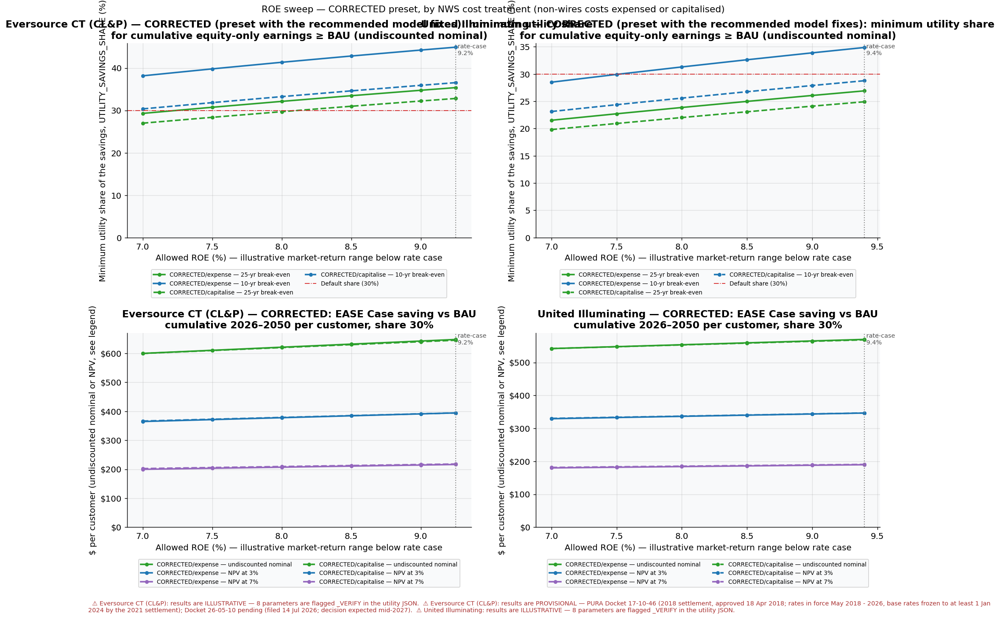

In [15]:
# ============================================================
# SECTION 8b (CONTINUED): CORRECTED PRESET SWEEP
# Runs the CORRECTED preset (engine/model.py PRESETS) — depreciation in
# delivery RR, 'revenue_requirement' pool, negative pools carried forward,
# bills indexed to BAU 2026 — for each NWS_COST_TREATMENT, ROE from the rate
# case to 7.0%, and UTILITY_SAVINGS_SHARE 0–50%. CORRECTED is NOT the model
# default; this cell leaves MODEL_CONFIG unchanged.
# Utility earnings here are equity-only (equity return + shared income).
# ============================================================
from engine import apply_preset, delivery_rr_reconciliation, PRESETS
from engine.roe_sweep import run_corrected_sweep

print('CORRECTED preset flags:', PRESETS['CORRECTED'])
print('\n2026 delivery revenue requirement reconciliation (BAU, rate-case ROE, nominal $M):')
recon = []
for k in utilities_to_run:
    r = delivery_rr_reconciliation(utility_data[k], MODEL_CONFIG)
    recon.append({'Utility': UTILITIES[k]['short_name'],
                  'Rate-case delivery RR': r['target_delivery_rr_m'],
                  'Return (WACC × RB)': r['return_m'],
                  'Property tax': r['property_tax_m'],
                  'Depreciation (3.5% × RB)': r['depreciation_m'],
                  'Other O&M (recalibrated)': r['other_om_recalibrated_m'],
                  'Other O&M % of delivery RR': f"{r['other_om_recalibrated_share']:.0%}",
                  'v1.0 model delivery RR': r['v10_delivery_rr_m'],
                  'v1.0 other O&M': r['other_om_v10_m']})
    for w in r['warnings']:
        print(f"  ⚠ {UTILITIES[k]['short_name']}: {w}")
display(pd.DataFrame(recon).set_index('Utility').round(0))

corr_df      = run_corrected_sweep(utility_data, MODEL_CONFIG, utilities_to_run,
                                   scenario_def=SCENARIO_DEFS['BASE'],
                                   roe_floor=ROE_SWEEP_FLOOR, roe_step=ROE_SWEEP_STEP)
corr_metrics = compute_roe_metrics(corr_df)
TREATMENTS   = list(dict.fromkeys(corr_metrics['variant']))
TREAT_STYLE  = {TREATMENTS[0]: '-', TREATMENTS[-1]: '--'}
print(f"\nCORRECTED sweep: {len(corr_df):,} rows. Variants: {TREATMENTS}")

# ── Cumulative saving per customer under CORRECTED (share = default) ──────────
at = corr_metrics[np.isclose(corr_metrics['share'], DEFAULT_SHARE)
                  & (np.isclose(corr_metrics['roe'], corr_metrics['rate_case_roe'])
                     | np.isclose(corr_metrics['roe'], ROE_SWEEP_FLOOR))].copy()
at['ROE'] = at['roe'].map(lambda r: f'{r:.1%}')
from engine import per_customer_label
_cust_lbl = per_customer_label(apply_preset(MODEL_CONFIG, 'CORRECTED'))   # 'per residential customer'
print(f"\nCumulative bill saving {_cust_lbl}, EASE Case vs BAU at the same ROE, 2026–2050, "
      f"share {DEFAULT_SHARE:.0%}:")
display(at.assign(Utility=at['utility'].map(lambda k: UTILITIES[k]['short_name']))
          .set_index(['Utility', 'variant', 'ROE'])[
              ['cum_saving_nominal', 'cum_saving_npv3', 'cum_saving_npv7']]
          .rename(columns={'cum_saving_nominal': f'$ {_cust_lbl}, undiscounted nominal',
                           'cum_saving_npv3': f'$ {_cust_lbl}, NPV at 3% (2026 $)',
                           'cum_saving_npv7': f'$ {_cust_lbl}, NPV at 7% (2026 $)'})
          .round(0))

# ── Break-even (minimum) utility share ────────────────────────────────────────
be = at.assign(Utility=at['utility'].map(lambda k: UTILITIES[k]['short_name']))
print("Break-even UTILITY_SAVINGS_SHARE: cumulative equity-only earnings ≥ BAU "
      "(undiscounted nominal). Independent of the share swept.")
display(be.set_index(['Utility', 'variant', 'ROE'])[['min_share_10y', 'min_share_25y']]
          .rename(columns={'min_share_10y': '10-yr break-even share',
                           'min_share_25y': '25-yr break-even share'})
          .apply(lambda col: col.map(lambda v: f'{v:.1%}' if np.isfinite(v) else 'none ≤ 100%')))

# ── Charts: CORRECTED min share and cumulative saving vs ROE ──────────────────
d_c = corr_metrics[np.isclose(corr_metrics['share'], DEFAULT_SHARE)]
fig, axes = plt.subplots(2, n, figsize=(7.5 * n, 11), squeeze=False)
for j, k in enumerate(utilities_to_run):
    ax = axes[0, j]
    for v in TREATMENTS:
        s = d_c[(d_c['utility'] == k) & (d_c['variant'] == v)].sort_values('roe')
        for col, colour, lbl in [('min_share_25y', C['shared'], '25-yr'),
                                 ('min_share_10y', C['util_shared'], '10-yr')]:
            ax.plot(s['roe'] * 100, s[col] * 100, color=colour, ls=TREAT_STYLE[v], lw=2,
                    marker='o', ms=4, label=f'{v} — {lbl} break-even')
    ax.axhline(DEFAULT_SHARE * 100, color=C['bau'], lw=1, ls='-.',
               label=f'Default share ({DEFAULT_SHARE:.0%})')
    ax.set_title(f"{UTILITIES[k]['short_name']} — CORRECTED (preset with the recommended model fixes): minimum utility share\n"
                 "for cumulative equity-only earnings ≥ BAU (undiscounted nominal)")
    ax.set_ylabel('Minimum utility share of the savings, UTILITY_SAVINGS_SHARE (%)'); ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)

    ax = axes[1, j]
    for v in TREATMENTS:
        s = d_c[(d_c['utility'] == k) & (d_c['variant'] == v)].sort_values('roe')
        for col, colour, lbl in [('cum_saving_nominal', C['shared'], 'undiscounted nominal'),
                                 ('cum_saving_npv3', C['util_shared'], 'NPV at 3%'),
                                 ('cum_saving_npv7', C['tax'], 'NPV at 7%')]:
            ax.plot(s['roe'] * 100, s[col], color=colour, ls=TREAT_STYLE[v], lw=2,
                    marker='o', ms=4, label=f'{v} — {lbl}')
    ax.set_title(f"{UTILITIES[k]['short_name']} — CORRECTED: EASE Case saving vs BAU\n"
                 f"cumulative 2026–2050 per customer, share {DEFAULT_SHARE:.0%}")
    ax.set_ylabel('$ per customer (undiscounted nominal or NPV, see legend)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
    ax.set_ylim(bottom=0)
    _fmt_roe_axis(ax, k)
    ax.legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.suptitle('ROE sweep — CORRECTED preset, by NWS cost treatment (non-wires costs expensed or capitalised)', fontsize=12)
_save(fig, 'roe_sweep_corrected')

## Section 9: Side-by-Side Comparison

Eversource CT (CL&P) against United Illuminating: the two Connecticut distribution companies on the same benchmark (700 kWh/month), market (ISO-NE) and policy calendar.


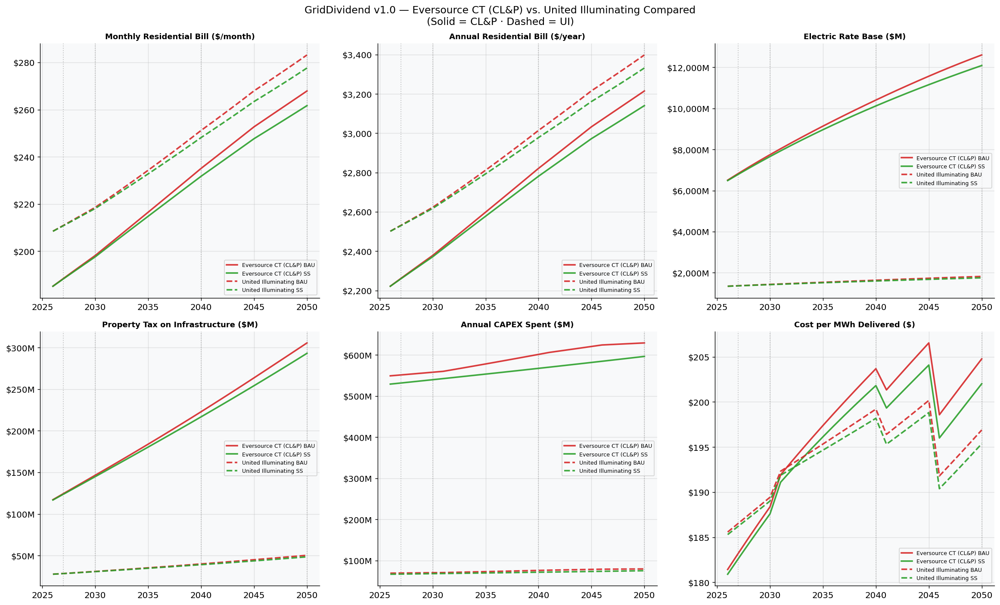

In [16]:
if len(utilities_to_run) < 2:
    print("Comparison needs two utilities.")
else:
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    fig.suptitle('GridDividend v1.0 — Eversource CT (CL&P) vs. United Illuminating Compared\n'
                 '(Solid = CL&P · Dashed = UI)', fontsize=13)
    panels = [
        ('avg_monthly_bill', 'Monthly Residential Bill ($/month)',  '${:,.0f}'),
        ('avg_annual_bill',  'Annual Residential Bill ($/year)',    '${:,.0f}'),
        ('rate_base_m',      'Electric Rate Base ($M)',             '${:,.0f}M'),
        ('property_tax_m',   'Property Tax on Infrastructure ($M)', '${:,.0f}M'),
        ('capex_spent_m',    'Annual CAPEX Spent ($M)',             '${:,.0f}M'),
        ('cost_per_mwh',     'Cost per MWh Delivered ($)',          '${:,.0f}'),
    ]
    for idx, (col, title, fmt) in enumerate(panels):
        ax = axes[idx // 3][idx % 3]
        for key in utilities_to_run:
            bau = results[key]['bau']; sh = results[key]['shared']
            lbl = UTILITIES[key]['short_name']
            ls  = '--' if key == 'UI_CT' else '-'
            ax.plot(YEARS, bau[col], color=C['bau'],    lw=2, ls=ls, alpha=0.9, label=f'{lbl} BAU')
            ax.plot(YEARS, sh[col],  color=C['shared'], lw=2, ls=ls, alpha=0.9, label=f'{lbl} SS')
        for yr in MY: ax.axvline(yr, color='gray', ls=':', alpha=0.45, lw=1.1)
        ax.set_title(title, fontsize=10)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _, f=fmt: f.format(x)))
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.savefig('charts/chart5_comparison.png', bbox_inches='tight', dpi=130)
    plt.show()

## Section 9b: Near-Term vs Long-Term Trade-Off

These scenarios explore the parameter space around near-term vs long-term bill savings. They are not forecasts and do not represent recommendations. BASE is the reference case. ACCELERATED assumes the utility has existing NWS capabilities and the programme reaches maturity faster — this is a legislative design choice about what preconditions the statute should require before the reform takes effect. FREEZE\_PLUS uses a longer rate freeze as the near-term mechanism, accepting deferred cost recovery in exchange for immediate relief. COMBINED layers both approaches. Each has different implications for utility commercial viability, regulatory complexity, and legislative design — the choice between them is a policy question, not a modelling one.

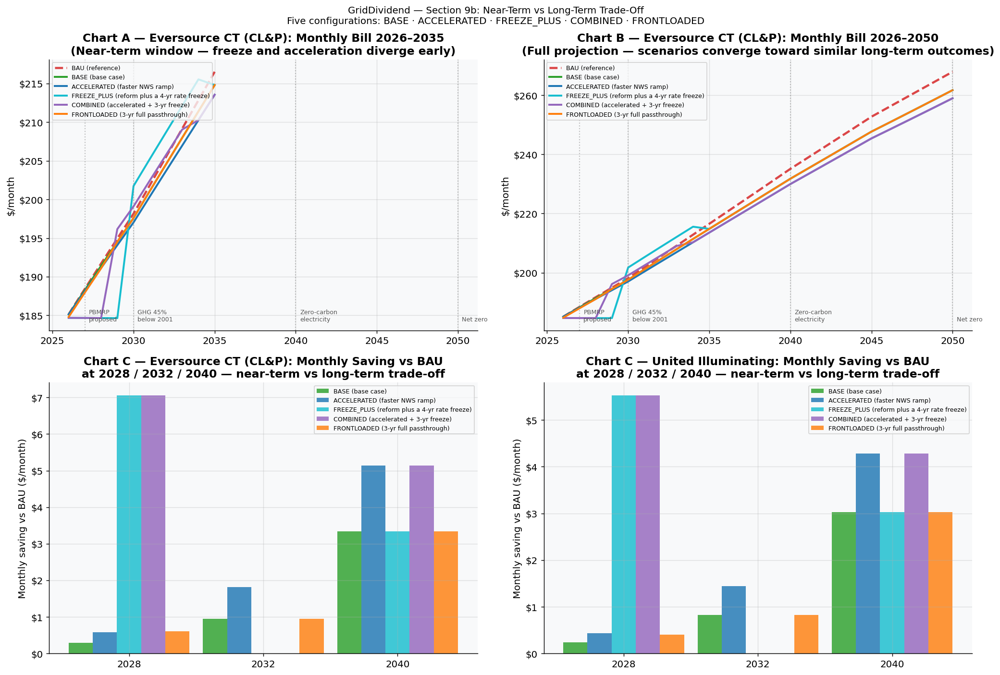

In [17]:
# ============================================================
# SECTION 9b: NEAR-TERM VS LONG-TERM TRADE-OFF — CHARTS
# Chart A: Con Edison monthly bill trajectories, 2026-2035 (near-term window)
# Chart B: Con Edison monthly bill trajectories, 2026-2050 (full projection)
# Chart C: Monthly saving vs BAU at 2028/2032/2040, both utilities side by side
# ============================================================

k_main    = utilities_to_run[0]
name_main = UTILITIES[k_main]['short_name']
bau_main  = results[k_main]['bau']

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle(
    'GridDividend — Section 9b: Near-Term vs Long-Term Trade-Off\n'
    'Five configurations: BASE · ACCELERATED · FREEZE_PLUS · COMBINED · FRONTLOADED',
    fontsize=11)

# ── Chart A: near-term window 2026–2035 ──────────────────────────────────────
ax = axes[0, 0]
bau_a = bau_main[bau_main['year'] <= 2035]
ax.plot(bau_a['year'], bau_a['avg_monthly_bill'],
        color=C['bau'], lw=2.5, ls='--', alpha=0.85, label='BAU (reference)')
for sname, sdef in SCENARIO_DEFS.items():
    df_a = scenario_results[k_main][sname]
    df_a = df_a[df_a['year'] <= 2035]
    ax.plot(df_a['year'], df_a['avg_monthly_bill'],
            color=sdef['colour'], lw=2.2, label=sdef['label'])
vlines(ax)
ax.set_title(f'Chart A — {name_main}: Monthly Bill 2026–2035\n'
             '(Near-term window — freeze and acceleration diverge early)')
ax.set_ylabel('$/month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=7, loc='upper left')

# ── Chart B: full projection 2026–2050 ───────────────────────────────────────
ax = axes[0, 1]
ax.plot(YEARS, bau_main['avg_monthly_bill'],
        color=C['bau'], lw=2.5, ls='--', alpha=0.85, label='BAU (reference)')
for sname, sdef in SCENARIO_DEFS.items():
    df_b = scenario_results[k_main][sname]
    ax.plot(df_b['year'], df_b['avg_monthly_bill'],
            color=sdef['colour'], lw=2.2, label=sdef['label'])
vlines(ax)
ax.set_title(f'Chart B — {name_main}: Monthly Bill 2026–2050\n'
             '(Full projection — scenarios converge toward similar long-term outcomes)')
ax.set_ylabel('$/month')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(fontsize=7, loc='upper left')

# ── Chart C: savings vs BAU at 2028 / 2032 / 2040, both utilities ────────────
snapshots = [2028, 2032, 2040]
x_pos     = np.arange(len(snapshots))
bar_w     = max(0.10, 0.90 / len(SCENARIO_DEFS))

for ci, k in enumerate(utilities_to_run[:2]):
    ax     = axes[1, ci]
    bau_df = results[k]['bau']
    for si, (sname, sdef) in enumerate(SCENARIO_DEFS.items()):
        sh_df   = scenario_results[k][sname]
        savings = []
        for yr in snapshots:
            bau_bill = bau_df[bau_df['year'] == yr].iloc[0]['avg_monthly_bill']
            sh_bill  = sh_df[sh_df['year']  == yr].iloc[0]['avg_monthly_bill']
            savings.append(max(0.0, bau_bill - sh_bill))
        offset = (si - (len(SCENARIO_DEFS) - 1) / 2) * bar_w
        ax.bar(x_pos + offset, savings, bar_w,
               color=sdef['colour'], label=sdef['label'], alpha=0.82)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(y) for y in snapshots])
    ax.set_ylabel('Monthly saving vs BAU ($/month)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_title(f'Chart C — {UTILITIES[k]["short_name"]}: Monthly Saving vs BAU\n'
                 'at 2028 / 2032 / 2040 — near-term vs long-term trade-off')
    ax.legend(fontsize=7)

if len(utilities_to_run) < 2:
    axes[1, 1].set_visible(False)

plt.tight_layout()
plt.savefig('charts/chart9b_nearterm_tradeoff.png', bbox_inches='tight', dpi=130)
plt.show()


In [18]:
# ============================================================
# SECTION 9b: NEAR-TERM VS LONG-TERM TRADE-OFF — SUMMARY TABLES
# Separate tables for each utility.
# Per scenario: bills at 2028/2035/2050, first year savings exceed
# $10/month vs BAU, and cumulative savings to 2050.
# ============================================================

def print_scenario_table(k):
    name   = UTILITIES[k]['short_name']
    bau_df = results[k]['bau']
    hdr = (f"  {'Scenario':<16} {'2028 $/mo':>10} {'2035 $/mo':>10} "
           f"{'2050 $/mo':>10} {'$10+/mo yr':>11} {'Cum $B':>8}")
    kwh_9b = UTILITIES[k].get('residential_kwh_month', 1000)
    print(f'Section 9b — {name} Scenario Summary Table ({kwh_9b:,.0f} kWh/month benchmark)')
    print(hdr)
    print('  ' + '-' * (len(hdr) - 2))
    for sname, sdef in SCENARIO_DEFS.items():
        df  = scenario_results[k][sname]
        b28 = df[df['year'] == 2028].iloc[0]['avg_monthly_bill']
        b35 = df[df['year'] == 2035].iloc[0]['avg_monthly_bill']
        b50 = df[df['year'] == 2050].iloc[0]['avg_monthly_bill']
        first_10 = '—'
        for yr in YEARS:
            bau_bill = bau_df[bau_df['year'] == yr].iloc[0]['avg_monthly_bill']
            sh_bill  = df[df['year'] == yr].iloc[0]['avg_monthly_bill']
            if bau_bill - sh_bill > 10:
                first_10 = str(yr)
                break
        cum = np.sum(
            (bau_df['avg_annual_bill'].values - df['avg_annual_bill'].values)
            * df['customers'].values
        ) / 1e9
        print(f'  {sname:<16} {b28:>9.1f}  {b35:>9.1f}  {b50:>9.1f}  '
              f'{first_10:>10}  {cum:>6.1f}B')
    print()

for k in utilities_to_run:
    print_scenario_table(k)


Section 9b — Eversource CT (CL&P) Scenario Summary Table (700 kWh/month benchmark)
  Scenario          2028 $/mo  2035 $/mo  2050 $/mo  $10+/mo yr   Cum $B
  ----------------------------------------------------------------------
  BASE                 191.4      214.8      261.7           —     1.2B
  ACCELERATED          191.1      213.6      259.0           —     1.9B
  FREEZE_PLUS          184.7      214.8      261.7        2029     1.2B
  COMBINED             184.7      213.6      259.0           —     1.9B
  FRONTLOADED          191.1      214.8      261.7           —     1.2B

Section 9b — United Illuminating Scenario Summary Table (700 kWh/month benchmark)
  Scenario          2028 $/mo  2035 $/mo  2050 $/mo  $10+/mo yr   Cum $B
  ----------------------------------------------------------------------
  BASE                 213.2      232.8      277.6           —     0.3B
  ACCELERATED          213.0      231.9      275.8           —     0.4B
  FREEZE_PLUS          207.9      232.

$10/month threshold year by NWS ramp length (BASE params)
   Ramp yrs  Eversource CT (CL&P)  United Illuminating
  --------------------------------------
          5         >2050         >2050
          6         >2050         >2050
          7         >2050         >2050
          8         >2050         >2050
          9         >2050         >2050 ◄ BASE
         10         >2050         >2050
         11         >2050         >2050
         12         >2050         >2050
         13         >2050         >2050
         14         >2050         >2050
         15         >2050         >2050


Saved: charts_article/chart6_ramp_sensitivity.png


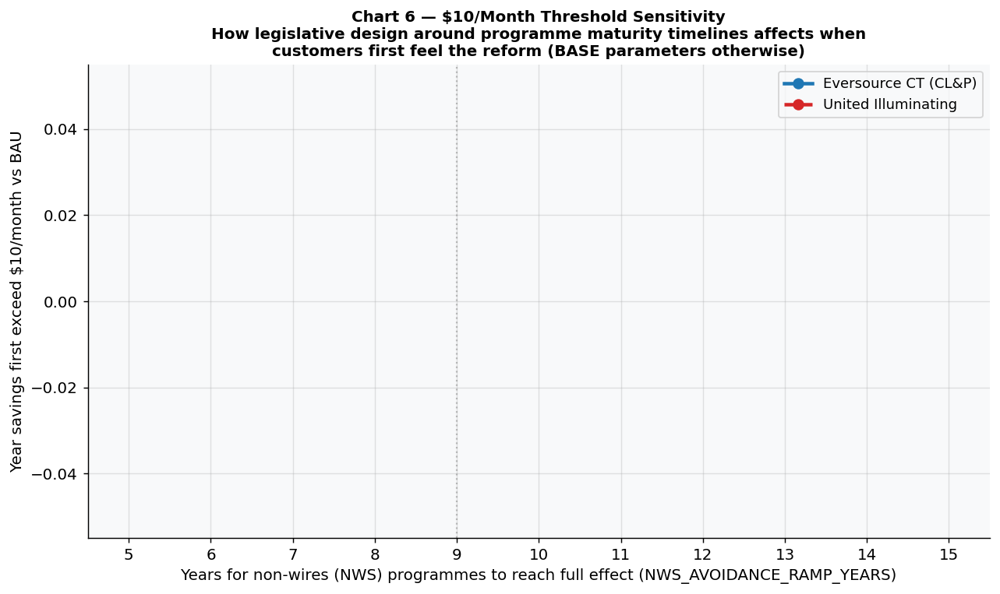

In [19]:
# ============================================================
# SECTION 9b (CONTINUED): $10/MONTH THRESHOLD RAMP SENSITIVITY
# Sweeps NWS_AVOIDANCE_RAMP_YEARS 5→15, BASE case params otherwise.
# For each ramp length: first year monthly savings vs BAU exceed $10/mo.
# ============================================================

ramp_range = list(range(5, 16))   # 5 to 15 inclusive
ramp_threshold = {k: [] for k in utilities_to_run}

for ramp_yrs in ramp_range:
    cfg = {**MODEL_CONFIG, 'NWS_AVOIDANCE_RAMP_YEARS': ramp_yrs}
    for k in utilities_to_run:
        p      = utility_data[k]
        bau_df = results[k]['bau']
        sh     = project(p, 'shared', False, config=cfg)
        # Apply same capacity pass-through as run_named_scenario BASE
        pt_m = []
        for yr in YEARS:
            b_row = bau_df[bau_df['year']==yr].iloc[0]
            s_row = sh[sh['year']==yr].iloc[0]
            peak_red = max(0.0, b_row['peak_mw'] - s_row['peak_mw'])
            cap_c    = capacity_cost_in_year(cfg, k, yr)   # per-utility growth (engine)
            saving_m = peak_red * cap_c
            monthly_red = (saving_m*(1-passthrough_utility_share(cfg)[0])*1e6) / (s_row['customers']*12)
            pt_m.append(monthly_red)
        pt_df = pd.DataFrame({'year': YEARS, 'pt': pt_m})
        sh = sh.merge(pt_df, on='year', how='left')
        sh['avg_monthly_bill'] -= sh['pt']
        threshold_yr = None
        for yr in YEARS:
            bau_bill = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
            sh_bill  = sh[sh['year']==yr].iloc[0]['avg_monthly_bill']
            if bau_bill - sh_bill > 10:
                threshold_yr = yr
                break
        ramp_threshold[k].append(threshold_yr if threshold_yr else 2051)

# Print results table
print('$10/month threshold year by NWS ramp length (BASE params)')
print(f"  {'Ramp yrs':>9}", end='')
for k in utilities_to_run:
    print(f"  {UTILITIES[k]['short_name']:>12}", end='')
print()
print('  ' + '-' * (10 + 14 * len(utilities_to_run)))
for i, r in enumerate(ramp_range):
    marker = ' ◄ BASE' if r == 9 else ''
    print(f"  {r:>9}", end='')
    for k in utilities_to_run:
        t = ramp_threshold[k][i]
        print(f"  {t if t < 2051 else '>2050':>12}", end='')
    print(marker)

# Chart 6: ramp sensitivity
import os; os.makedirs('charts_article', exist_ok=True)

fig6, ax6 = plt.subplots(figsize=(10, 6))
util_styles = {'EversourceCT': ('-', '#1f77b4', 'Eversource CT (CL&P)'),
               'UI_CT':  ('--', '#d62728', 'United Illuminating')}
for k in utilities_to_run:
    ls, col, lbl = util_styles.get(k, ('-', '#888888', UTILITIES[k]['short_name']))
    vals = [t if t < 2051 else None for t in ramp_threshold[k]]
    ax6.plot(ramp_range, vals, color=col, ls=ls, lw=2.5, marker='o', ms=7, label=lbl)
_base_ramp = MODEL_CONFIG['NWS_AVOIDANCE_RAMP_YEARS']
_base_thr = ramp_threshold[utilities_to_run[0]][ramp_range.index(_base_ramp)]
if _base_thr < 2051:
    ax6.axhline(_base_thr, color='gray', ls=':', lw=1.5, alpha=0.7)
    ax6.text(15.05, _base_thr, f'BASE threshold\n(ramp={_base_ramp})', fontsize=9, va='center', color='gray')
ax6.axvline(_base_ramp, color='gray', ls=':', lw=1.2, alpha=0.5)
ax6.set_xlabel('Years for non-wires (NWS) programmes to reach full effect (NWS_AVOIDANCE_RAMP_YEARS)', fontsize=11)
ax6.set_ylabel('Year savings first exceed $10/month vs BAU', fontsize=11)
ax6.set_title('Chart 6 — $10/Month Threshold Sensitivity\n'
              'How legislative design around programme maturity timelines affects when\n'
              'customers first feel the reform (BASE parameters otherwise)',
              fontsize=11)
ax6.set_xticks(ramp_range)
ax6.set_xlim(4.5, 15.5)
ax6.legend(fontsize=10)
fig6.tight_layout()
fname6 = 'charts_article/chart6_ramp_sensitivity.png'
fig6.savefig(fname6, dpi=300, bbox_inches='tight')
print(f'Saved: {fname6}')
plt.show()


## Section 9c: Article Charts

Publication-quality charts saved to `charts_article/` at 300 dpi: near-term and full-projection bill savings vs BAU for Eversource CT (Charts 1–2) and United Illuminating (Charts 3–4), milestone bars (Chart 5) and the ramp sensitivity (Chart 6).


Saved: charts_article/chart1_eversourcect_nearterm.png


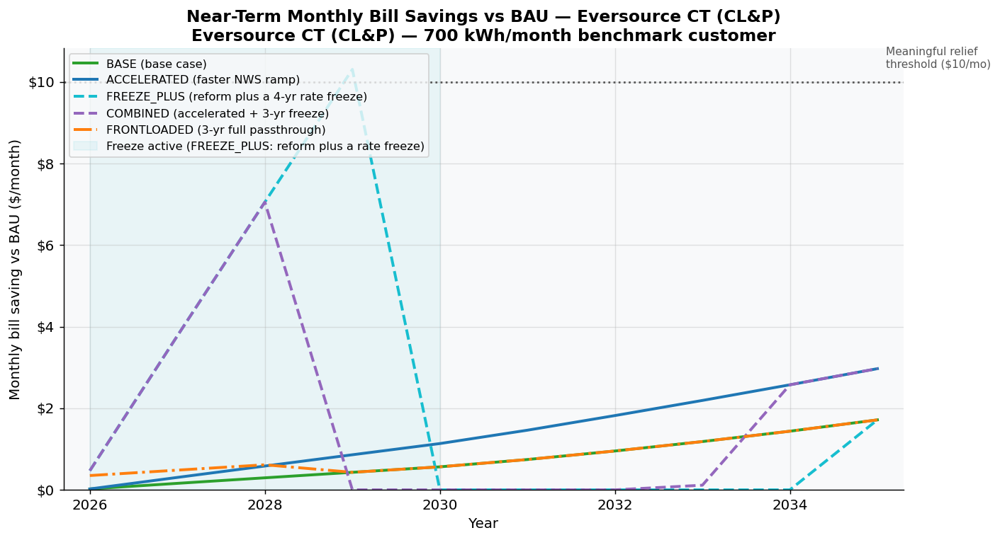

Saved: charts_article/chart2_eversourcect_full.png


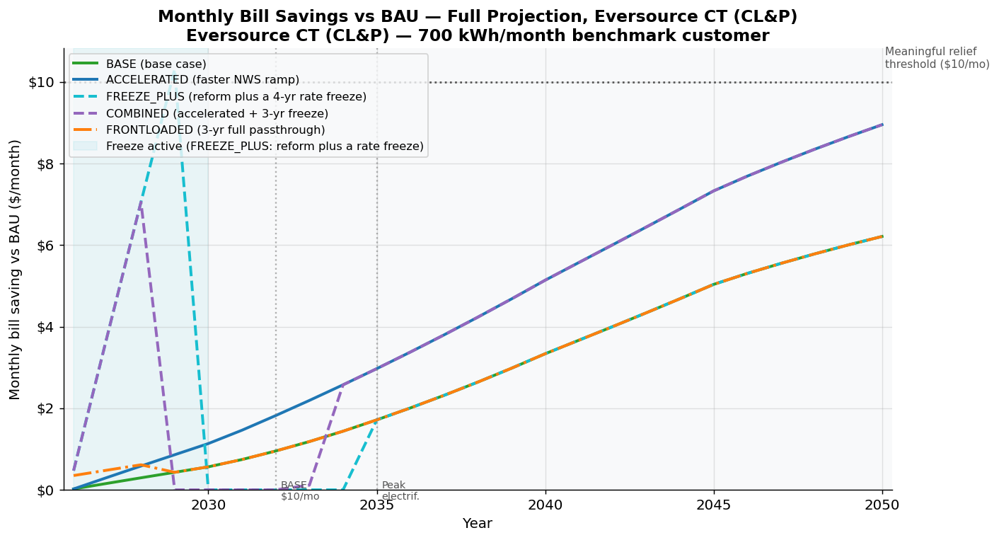

Saved: charts_article/chart3_ui_ct_nearterm.png


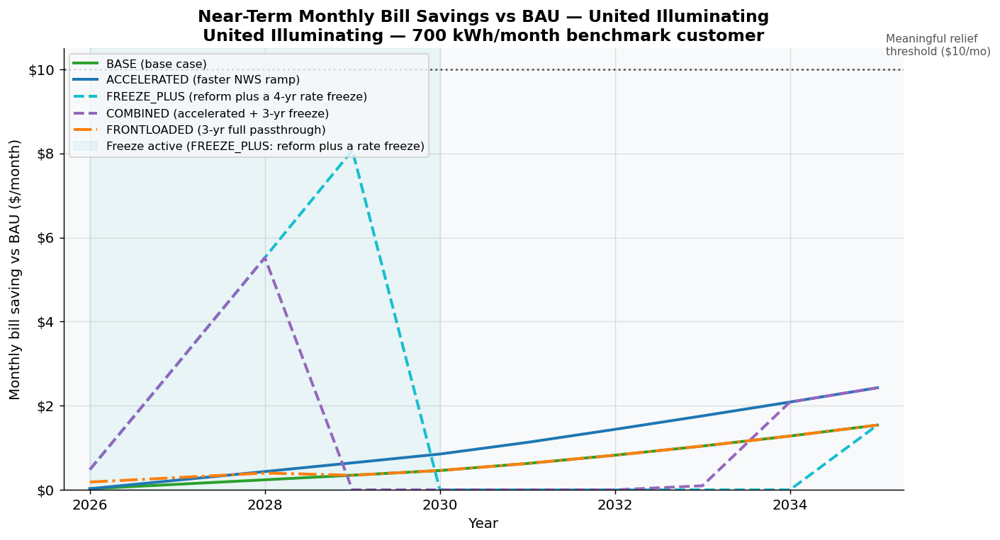

Saved: charts_article/chart4_ui_ct_full.png


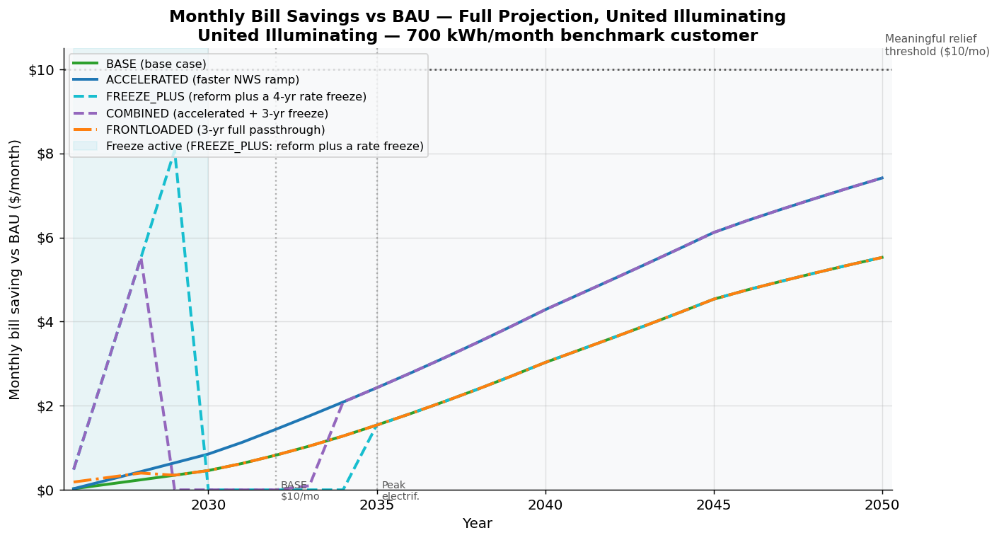

Saved: charts_article/chart5_milestone_bars.png


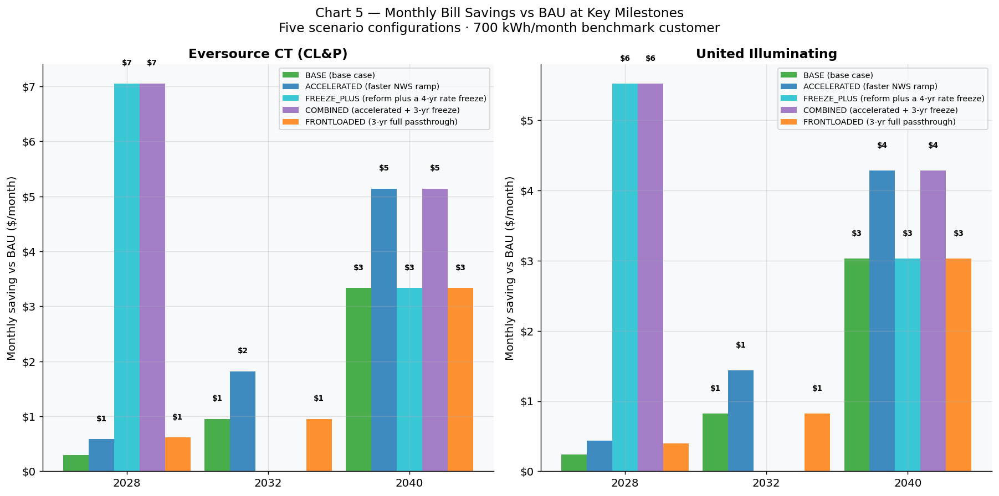

In [20]:
# ============================================================
# SECTION 9c: ARTICLE CHARTS 1-5
# All saved to charts_article/ at 300 dpi.
# Charts 1-4: monthly savings vs BAU (floor 0), near-term and full.
# Chart 5: bar chart at milestone years, both utilities.
# ============================================================

import os; os.makedirs('charts_article', exist_ok=True)

SC = {sname: sdef for sname, sdef in SCENARIO_DEFS.items()}
SC_LINES = {
    'BASE':        ('-',   SC['BASE']['colour'],        'BASE (base case)'),
    'ACCELERATED': ('-',   SC['ACCELERATED']['colour'], 'ACCELERATED (faster NWS ramp)'),
    'FREEZE_PLUS': ('--',  SC['FREEZE_PLUS']['colour'], 'FREEZE_PLUS (reform plus a 4-yr rate freeze)'),
    'COMBINED':    ('--',  SC['COMBINED']['colour'],    'COMBINED (accelerated + 3-yr freeze)'),
    'FRONTLOADED': ('-.',  SC['FRONTLOADED']['colour'], 'FRONTLOADED (3-yr full passthrough)'),
}

def savings_series(k, sname, years=None):
    """Monthly savings vs BAU, floored at 0, for given years."""
    if years is None: years = YEARS
    bau_df = results[k]['bau']
    sh_df  = scenario_results[k][sname]
    savs = []
    for yr in years:
        b = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
        s = sh_df[sh_df['year']==yr].iloc[0]['avg_monthly_bill']
        savs.append(max(0.0, b - s))
    return savs

def make_savings_chart(k, years, title, fname, extra_vlines=None):
    """Charts 1-4 template: savings vs BAU over a year range."""
    name = UTILITIES[k]['short_name']
    # FREEZE_PLUS freeze end year (2026 + RATE_FREEZE_YEARS = 2030)
    freeze_end_yr = 2026 + SC['FREEZE_PLUS']['params'].get('RATE_FREEZE_YEARS', RATE_FREEZE_YEARS)

    fig, ax = plt.subplots(figsize=(11, 6))
    for sname, (ls, col, lbl) in SC_LINES.items():
        svs = savings_series(k, sname, years)
        ax.plot(years, svs, color=col, ls=ls, lw=2.2, label=lbl)

    # $10/month reference line
    ax.axhline(10, color='#555', ls=':', lw=1.5)
    ax.text(years[-1] + 0.1, 10.3, 'Meaningful relief\nthreshold ($10/mo)',
            fontsize=8.5, va='bottom', color='#555')

    # Shade freeze-active period for FREEZE_PLUS
    freeze_shade_end = min(freeze_end_yr, years[-1])
    if freeze_shade_end > years[0]:
        ax.axvspan(years[0], freeze_shade_end, alpha=0.07,
                   color=SC['FREEZE_PLUS']['colour'], label='Freeze active (FREEZE_PLUS: reform plus a rate freeze)')

    # Extra vertical reference lines
    if extra_vlines:
        for yr, lbl in extra_vlines.items():
            if years[0] <= yr <= years[-1]:
                ax.axvline(yr, color='gray', ls=':', lw=1.3, alpha=0.6)
                ylo, yhi = ax.get_ylim()
                ax.text(yr + 0.15, ylo + (yhi-ylo)*0.02, lbl,
                        fontsize=8, color='#555', va='bottom')

    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel('Monthly bill saving vs BAU ($/month)', fontsize=11)
    kwh_9c = UTILITIES[k].get('residential_kwh_month', 1000)
    ax.set_title(f'{title}\n{name} — {kwh_9c:,.0f} kWh/month benchmark customer', fontsize=13)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_xlim(years[0] - 0.3, years[-1] + 0.3)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=9, loc='upper left')
    fig.tight_layout()
    fig.savefig(fname, dpi=300, bbox_inches='tight')
    print(f'Saved: {fname}')
    plt.show()

# ── Charts 1–4 ───────────────────────────────────────────────────────────────
near = [y for y in YEARS if y <= 2035]
full = YEARS
vlines_full = {2032: 'BASE\n$10/mo', 2035: 'Peak\nelectrif.'}

k_primary = utilities_to_run[0]
name_primary = UTILITIES[k_primary]['short_name']

make_savings_chart(
    k_primary, near,
    f'Near-Term Monthly Bill Savings vs BAU — {name_primary}',
    f'charts_article/chart1_{k_primary.lower()}_nearterm.png')

make_savings_chart(
    k_primary, full,
    f'Monthly Bill Savings vs BAU — Full Projection, {name_primary}',
    f'charts_article/chart2_{k_primary.lower()}_full.png',
    extra_vlines=vlines_full)

if 'UI_CT' in utilities_to_run:
    make_savings_chart(
        'UI_CT', near,
        'Near-Term Monthly Bill Savings vs BAU — United Illuminating',
        'charts_article/chart3_ui_ct_nearterm.png')

    make_savings_chart(
        'UI_CT', full,
        'Monthly Bill Savings vs BAU — Full Projection, United Illuminating',
        'charts_article/chart4_ui_ct_full.png',
        extra_vlines=vlines_full)

# ── Chart 5: bar chart — milestone savings, both utilities ────────────────────
snapshots  = [2028, 2032, 2040]
x_pos      = np.arange(len(snapshots))
snames     = list(SC.keys())
bar_w      = max(0.10, 0.90 / len(snames))
n_util     = min(2, len(utilities_to_run))

fig5, axes5 = plt.subplots(1, n_util, figsize=(7 * n_util, 7), sharey=False)
if n_util == 1: axes5 = [axes5]

for ci, k in enumerate(utilities_to_run[:n_util]):
    ax = axes5[ci]
    bau_df = results[k]['bau']
    for si, sname in enumerate(snames):
        ls, col, lbl = SC_LINES[sname]
        sh_df   = scenario_results[k][sname]
        savings = []
        for yr in snapshots:
            b = bau_df[bau_df['year']==yr].iloc[0]['avg_monthly_bill']
            s = sh_df[sh_df['year']==yr].iloc[0]['avg_monthly_bill']
            savings.append(max(0.0, b - s))
        offset = (si - (len(snames) - 1) / 2) * bar_w
        bars = ax.bar(x_pos + offset, savings, bar_w, color=col,
                      label=lbl, alpha=0.85)
        for bar, val in zip(bars, savings):
            if val >= 0.5:
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                        f'${val:.0f}', ha='center', va='bottom', fontsize=7.5,
                        fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(y) for y in snapshots], fontsize=11)
    ax.set_ylabel('Monthly saving vs BAU ($/month)', fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
    ax.set_title(f'{UTILITIES[k]["short_name"]}', fontsize=13, fontweight='bold')
    ax.legend(fontsize=8)
    ax.set_ylim(bottom=0)

kwh_5 = UTILITIES[utilities_to_run[0]].get('residential_kwh_month', 1000)
fig5.suptitle(
    'Chart 5 — Monthly Bill Savings vs BAU at Key Milestones\n'
    f'Five scenario configurations · {kwh_5:,.0f} kWh/month benchmark customer',
    fontsize=13)
fig5.tight_layout()
fname5 = 'charts_article/chart5_milestone_bars.png'
fig5.savefig(fname5, dpi=300, bbox_inches='tight')
print(f'Saved: {fname5}')
plt.show()


Saved: charts_article/chart7_deferral_sensitivity.png


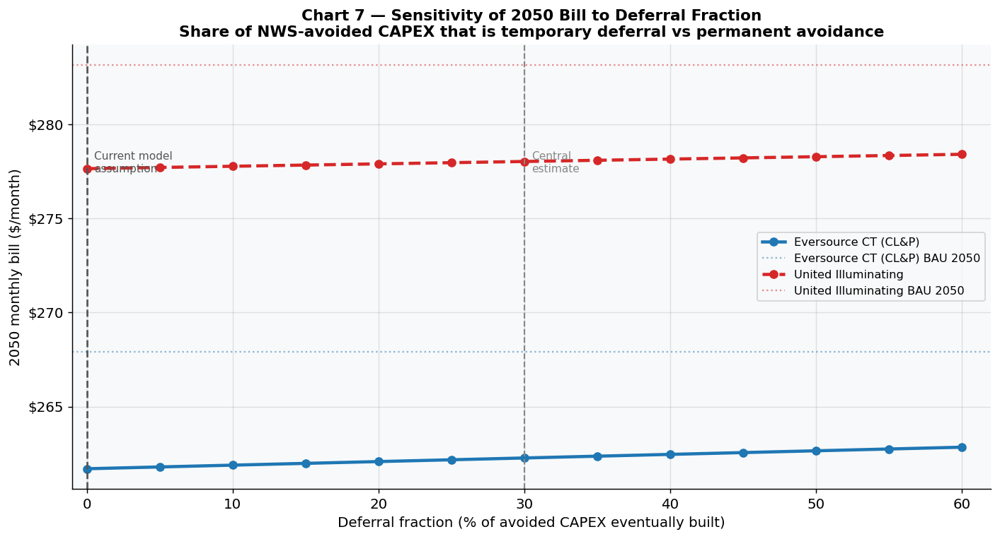


Deferral fraction sensitivity — 2050 monthly bill ($/month)
    Deferral %  Eversource CT (CL&P)  United Illuminating
  --------------------------------------
            0%  $     262  $     278  ← current model
            5%  $     262  $     278
           10%  $     262  $     278
           15%  $     262  $     278
           20%  $     262  $     278
           25%  $     262  $     278
           30%  $     262  $     278  ← central estimate
           35%  $     262  $     278
           40%  $     262  $     278
           45%  $     263  $     278
           50%  $     263  $     278
           55%  $     263  $     278
           60%  $     263  $     278


In [21]:
# ============================================================
# SECTION 9d: DEFERRAL FRACTION SENSITIVITY
# Sweeps DEFERRAL_FRACTION 0.0 → 0.60 in steps of 0.05.
# For each value: re-runs shared savings scenario, records 2050 monthly bill.
# Saves chart7_deferral_sensitivity.png to charts_article/.
# ============================================================

import os; os.makedirs('charts_article', exist_ok=True)

deferral_range   = [round(x * 0.05, 2) for x in range(13)]  # 0.00 to 0.60
bill_2050_by_df  = {k: [] for k in utilities_to_run}

for df_val in deferral_range:
    cfg = {**MODEL_CONFIG, 'DEFERRAL_FRACTION': df_val}
    for k in utilities_to_run:
        p    = utility_data[k]
        sh   = project(p, 'shared', False, config=cfg)
        # Apply capacity pass-through (same as BASE scenario)
        bau_df_ref = results[k]['bau']
        pt_m = []
        for yr in YEARS:
            b_row = bau_df_ref[bau_df_ref['year'] == yr].iloc[0]
            s_row = sh[sh['year'] == yr].iloc[0]
            peak_red = max(0.0, b_row['peak_mw'] - s_row['peak_mw'])
            cap_c    = capacity_cost_in_year(cfg, k, yr)   # per-utility growth (engine)
            monthly_red = (peak_red * cap_c * (1 - passthrough_utility_share(cfg)[0]) * 1e6) / (
                           s_row['customers'] * 12)
            pt_m.append(monthly_red)
        pt_frame = pd.DataFrame({'year': YEARS, 'pt': pt_m})
        sh = sh.merge(pt_frame, on='year', how='left')
        sh['avg_monthly_bill'] -= sh['pt']
        b50 = sh[sh['year'] == 2050].iloc[0]['avg_monthly_bill']
        bill_2050_by_df[k].append(b50)

# ── Chart 7 ────────────────────────────────────────────────────────────────
fig7, ax7 = plt.subplots(figsize=(11, 6))

util_styles7 = {
    'EversourceCT': ('-',  '#1f77b4', 'Eversource CT (CL&P)'),
    'UI_CT':  ('--', '#d62728', 'United Illuminating'),
}

for k in utilities_to_run:
    ls7, col7, lbl7 = util_styles7.get(k, ('-', '#888888', k))
    ax7.plot([v * 100 for v in deferral_range], bill_2050_by_df[k],
             color=col7, ls=ls7, lw=2.5, marker='o', ms=6, label=lbl7)
    # BAU reference line
    bau_50 = results[k]['bau'][results[k]['bau']['year'] == 2050].iloc[0]['avg_monthly_bill']
    ax7.axhline(bau_50, color=col7, ls=':', lw=1.3, alpha=0.5,
                label=f'{UTILITIES[k]["short_name"]} BAU 2050')

ax7.axvline(0.0,  color='#555', ls='--', lw=1.5)
ax7.text(0.5,  ax7.get_ylim()[1] * 0.98, 'Current model\nassumption',
         fontsize=8.5, va='top', color='#555')
ax7.axvline(30.0, color='#888', ls='--', lw=1.2)
ax7.text(30.5, ax7.get_ylim()[1] * 0.98, 'Central\nestimate',
         fontsize=8.5, va='top', color='#888')

ax7.set_xlabel('Deferral fraction (% of avoided CAPEX eventually built)', fontsize=11)
ax7.set_ylabel('2050 monthly bill ($/month)', fontsize=11)
ax7.set_title(
    'Chart 7 — Sensitivity of 2050 Bill to Deferral Fraction\n'
    'Share of NWS-avoided CAPEX that is temporary deferral vs permanent avoidance',
    fontsize=12)
ax7.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax7.set_xlim(-1, 62)
ax7.legend(fontsize=9)
fig7.tight_layout()
fname7 = 'charts_article/chart7_deferral_sensitivity.png'
fig7.savefig(fname7, dpi=300, bbox_inches='tight')
print(f'Saved: {fname7}')
plt.show()

# Print summary table
print('\nDeferral fraction sensitivity — 2050 monthly bill ($/month)')
hdr = f"  {'Deferral %':>12}"
for k in utilities_to_run:
    hdr += f"  {UTILITIES[k]['short_name']:>10}"
print(hdr)
print('  ' + '-' * (14 + 12 * len(utilities_to_run)))
for i, df_val in enumerate(deferral_range):
    row = f'  {df_val*100:>11.0f}%'
    for k in utilities_to_run:
        row += f'  ${bill_2050_by_df[k][i]:>8.0f}'
    marker = '  ← current model' if df_val == 0.0 else (
             '  ← central estimate' if df_val == 0.30 else '')
    print(row + marker)

## Section 9d: The Long-Term Case — Cumulative Cost and Policy Window Analysis

These charts address the central policy question: not how much does shared savings reform save in year one, but what does it mean for what customers pay over the lifetime of the programme? The cumulative cost chart, the crossover analysis, and the policy window framing are designed to reframe the discussion from short-term relief to long-term trajectory.

Saved: charts_article/chart8_cumulative_eversourcect.png


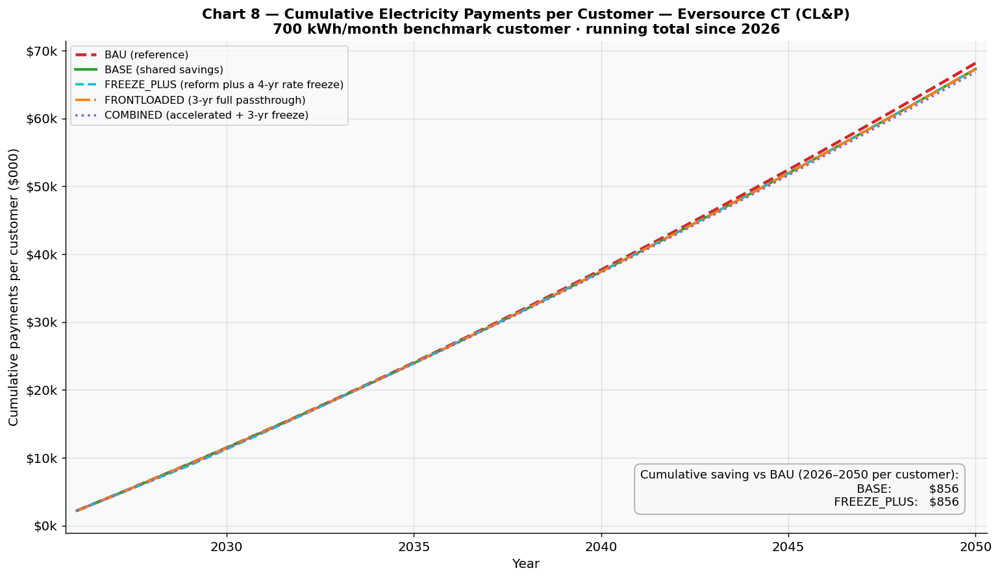

Saved: charts_article/chart9_crossover_eversourcect.png


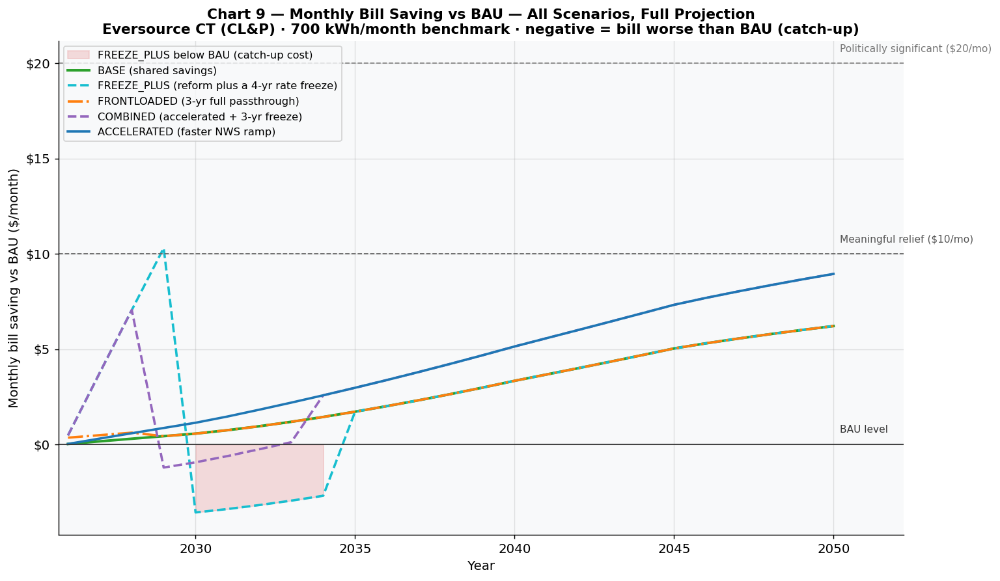

Saved: charts_article/chart10_policy_window_eversourcect.png


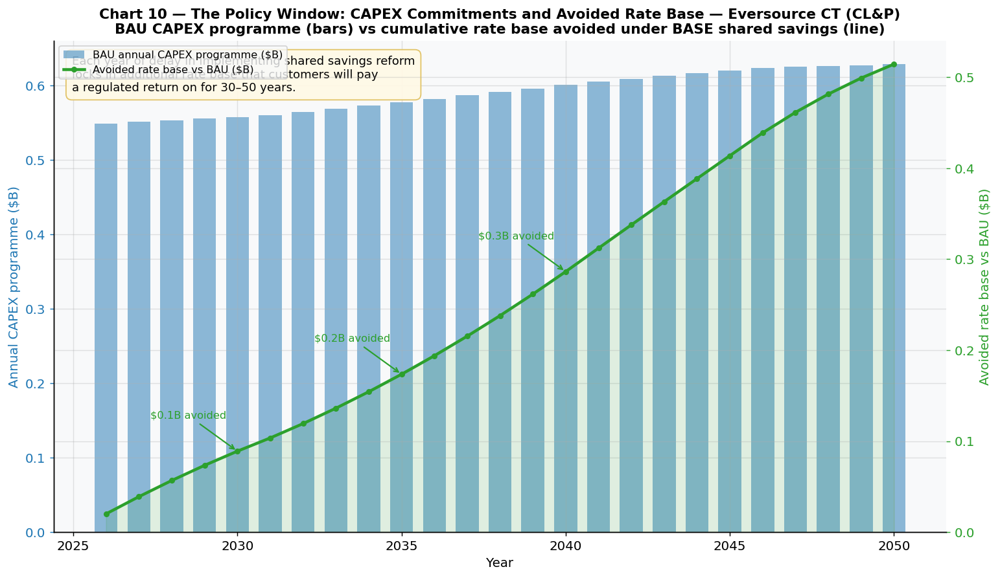

Saved: charts_article/chart11_household_impact_eversourcect.png


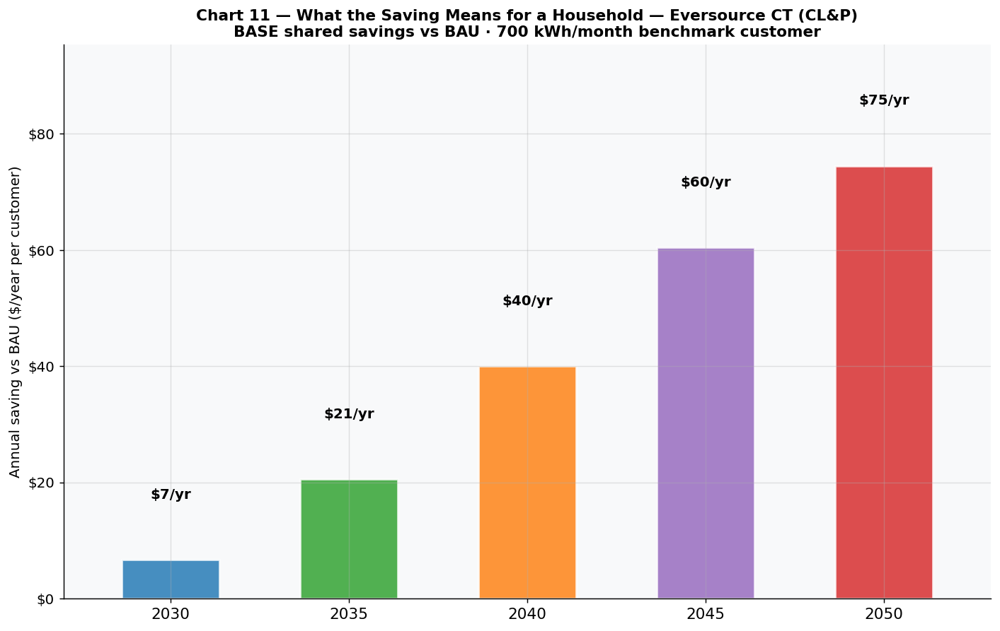


KEY NUMBERS — SECTION 9d

Crossover year (BASE cumulative cost first < FREEZE_PLUS cumulative):
  Does not occur within 2026–2050

Cumulative payments 2026–2050 per customer (700 kWh/month benchmark):
  BAU:          $    68,158
  BASE:         $    67,302  (saves $856 vs BAU)
  FREEZE_PLUS:  $    67,302  (saves $856 vs BAU)

Avoided rate base BASE vs BAU ($B):
  2035: $0.2B
  2050: $0.5B

Annual saving per customer — BASE vs BAU:
  2030: $7/year   ($1/month)
  2035: $21/year   ($2/month)
  2040: $40/year   ($3/month)
  2045: $60/year   ($5/month)
  2050: $75/year   ($6/month)


Saved: charts_article/chart12_the_case_for_reform_eversourcect.png


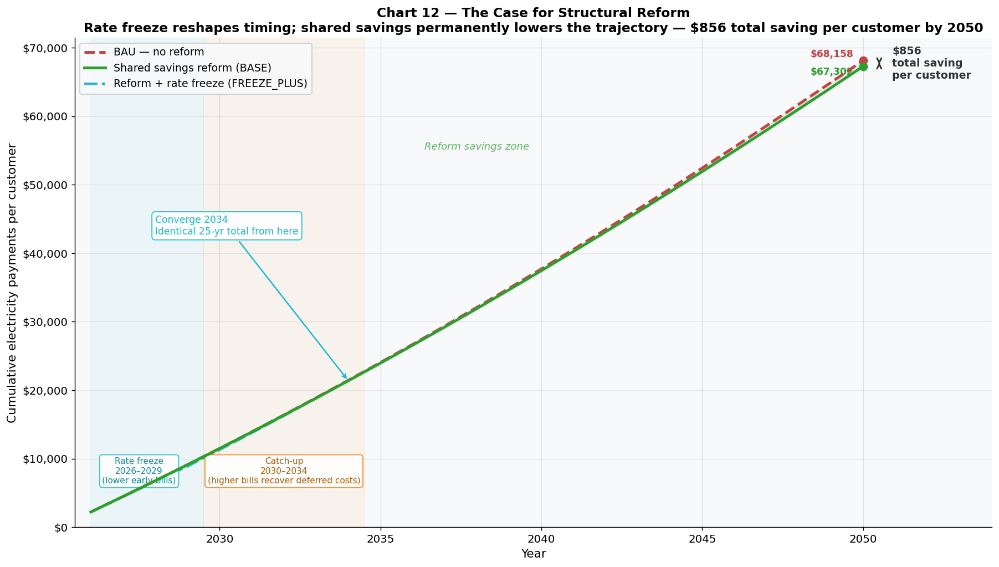

In [22]:
# ============================================================
# SECTION 9d: LONG-TERM CASE — CUMULATIVE COST AND POLICY WINDOW
# Charts 8–11 saved to charts_article/ at 300 dpi.
# ============================================================

# Explicitly scope primary utility key and params for this section
k_primary = utilities_to_run[0]
p = utility_data[k_primary]

import os
os.makedirs('charts_article', exist_ok=True)

k_9d   = utilities_to_run[0]
name_9d = UTILITIES[k_9d]['short_name']
bau_9d  = results[k_9d]['bau']
base_9d = scenario_results[k_9d]['BASE']
frzp_9d = scenario_results[k_9d]['FREEZE_PLUS']
fl_9d   = scenario_results[k_9d]['FRONTLOADED']
comb_9d = scenario_results[k_9d]['COMBINED']
accel_9d = scenario_results[k_9d]['ACCELERATED']

# ── Helpers ───────────────────────────────────────────────────────────────────
def cum_payments_9d(df):
    """Running total paid by a residential customer ($ thousands) since 2026 (usage benchmark: p['residential_kwh_month'] kWh/month)."""
    return np.cumsum(df.sort_values('year')['avg_annual_bill'].values) / 1000

def monthly_saving_9d(sc_df):
    """Monthly saving vs BAU ($/month); NOT floored — can be negative."""
    return [
        float(bau_9d[bau_9d['year'] == yr].iloc[0]['avg_monthly_bill']) -
        float(sc_df[sc_df['year'] == yr].iloc[0]['avg_monthly_bill'])
        for yr in YEARS
    ]

# Pre-compute cumulative series
cum_bau_9d  = cum_payments_9d(bau_9d)
cum_base_9d = cum_payments_9d(base_9d)
cum_frzp_9d = cum_payments_9d(frzp_9d)
cum_fl_9d   = cum_payments_9d(fl_9d)
cum_comb_9d = cum_payments_9d(comb_9d)

# Pre-compute saving series
sav_base_9d  = monthly_saving_9d(base_9d)
sav_frzp_9d  = monthly_saving_9d(frzp_9d)
sav_fl_9d    = monthly_saving_9d(fl_9d)
sav_comb_9d  = monthly_saving_9d(comb_9d)
sav_accel_9d = monthly_saving_9d(accel_9d)

# Find crossover: first year where BASE cumulative cost < FREEZE_PLUS cumulative cost
crossover_9d = None
for _i9d, _yr9d in enumerate(YEARS):
    if cum_base_9d[_i9d] < cum_frzp_9d[_i9d]:
        crossover_9d = _yr9d
        break

# ============================================================
# CHART 8: Cumulative customer payments — Con Edison
# ============================================================
fig8, ax8 = plt.subplots(figsize=(12, 7))

_cum_lines_8 = [
    (cum_bau_9d,  '--', C['bau'],                              2.5, 'BAU (reference)'),
    (cum_base_9d, '-',  SCENARIO_DEFS['BASE']['colour'],       2.2, 'BASE (shared savings)'),
    (cum_frzp_9d, '--', SCENARIO_DEFS['FREEZE_PLUS']['colour'], 2.0, 'FREEZE_PLUS (reform plus a 4-yr rate freeze)'),
    (cum_fl_9d,   '-.', SCENARIO_DEFS['FRONTLOADED']['colour'], 2.0, 'FRONTLOADED (3-yr full passthrough)'),
    (cum_comb_9d, ':',  SCENARIO_DEFS['COMBINED']['colour'],   2.0, 'COMBINED (accelerated + 3-yr freeze)'),
]
for _vals, _ls, _col, _lw, _lbl in _cum_lines_8:
    ax8.plot(YEARS, _vals, ls=_ls, color=_col, lw=_lw, label=_lbl)

# Vertical crossover line
if crossover_9d is not None:
    _ylo8, _yhi8 = ax8.get_ylim()
    ax8.axvline(crossover_9d, color='#444', ls=':', lw=1.8, alpha=0.8)
    ax8.text(crossover_9d + 0.3, _ylo8 + (_yhi8 - _ylo8) * 0.50,
             f'Shared savings\novertakes freeze\n({crossover_9d})',
             fontsize=9, color='#444', va='center',
             bbox=dict(boxstyle='round,pad=0.4', facecolor='white', edgecolor='#ccc', alpha=0.90))

# Cumulative saving text box (lower right)
_csave_base = (cum_bau_9d[-1] - cum_base_9d[-1]) * 1000
_csave_frzp = (cum_bau_9d[-1] - cum_frzp_9d[-1]) * 1000
ax8.text(0.97, 0.05,
         f'Cumulative saving vs BAU (2026–2050 per customer):\n'
         f'  BASE:          ${_csave_base:,.0f}\n'
         f'  FREEZE_PLUS:   ${_csave_frzp:,.0f}',
         transform=ax8.transAxes, ha='right', va='bottom', fontsize=10,
         bbox=dict(boxstyle='round,pad=0.5', facecolor='#f8f8f8', edgecolor='#aaa', alpha=0.95))

ax8.set_xlabel('Year', fontsize=11)
ax8.set_ylabel('Cumulative payments per customer ($000)', fontsize=11)
ax8.set_title(
    f'Chart 8 — Cumulative Electricity Payments per Customer — {name_9d}\n'
    f'{p["residential_kwh_month"]:,.0f} kWh/month benchmark customer · running total since 2026',
    fontsize=12)
ax8.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}k'))
ax8.set_xlim(YEARS[0] - 0.3, YEARS[-1] + 0.3)
ax8.legend(fontsize=9, loc='upper left')
fig8.tight_layout()
fname8 = f'charts_article/chart8_cumulative_{k_9d.lower()}.png'
fig8.savefig(fname8, dpi=300, bbox_inches='tight')
print(f'Saved: {fname8}')
plt.show()

# ============================================================
# CHART 9: Crossover analysis — annual saving vs BAU, all scenarios
# ============================================================
fig9, ax9 = plt.subplots(figsize=(12, 7))

# Shade region where FREEZE_PLUS saving is negative (bills worse than BAU)
_frzp_arr = np.array(sav_frzp_9d)
if np.any(_frzp_arr < 0):
    ax9.fill_between(YEARS, _frzp_arr, 0,
                     where=(_frzp_arr < 0),
                     color='#d62728', alpha=0.15,
                     label='FREEZE_PLUS below BAU (catch-up cost)')

_sav_lines_9 = [
    (sav_base_9d,  '-',   SCENARIO_DEFS['BASE']['colour'],        2.2, 'BASE (shared savings)'),
    (sav_frzp_9d,  '--',  SCENARIO_DEFS['FREEZE_PLUS']['colour'], 2.0, 'FREEZE_PLUS (reform plus a 4-yr rate freeze)'),
    (sav_fl_9d,    '-.',  SCENARIO_DEFS['FRONTLOADED']['colour'], 2.0, 'FRONTLOADED (3-yr full passthrough)'),
    (sav_comb_9d,  '--',  SCENARIO_DEFS['COMBINED']['colour'],    2.0, 'COMBINED (accelerated + 3-yr freeze)'),
    (sav_accel_9d, '-',   SCENARIO_DEFS['ACCELERATED']['colour'], 2.0, 'ACCELERATED (faster NWS ramp)'),
]
for _vals, _ls, _col, _lw, _lbl in _sav_lines_9:
    ax9.plot(YEARS, _vals, ls=_ls, color=_col, lw=_lw, label=_lbl)

# Reference lines
_yr_end = YEARS[-1]
ax9.axhline(0,  color='#333', ls='-',  lw=1.0)
ax9.axhline(10, color='#666', ls='--', lw=1.0)
ax9.axhline(20, color='#888', ls='--', lw=1.0)
ax9.text(_yr_end + 0.2,  0.5, 'BAU level',                       fontsize=8.5, va='bottom', color='#333')
ax9.text(_yr_end + 0.2, 10.5, 'Meaningful relief ($10/mo)',       fontsize=8.5, va='bottom', color='#555')
ax9.text(_yr_end + 0.2, 20.5, 'Politically significant ($20/mo)', fontsize=8.5, va='bottom', color='#777')

ax9.set_xlabel('Year', fontsize=11)
ax9.set_ylabel('Monthly bill saving vs BAU ($/month)', fontsize=11)
ax9.set_title(
    'Chart 9 — Monthly Bill Saving vs BAU — All Scenarios, Full Projection\n'
    f'{name_9d} · {p["residential_kwh_month"]:,.0f} kWh/month benchmark · negative = bill worse than BAU (catch-up)',
    fontsize=12)
ax9.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
ax9.set_xlim(YEARS[0] - 0.3, YEARS[-1] + 2.2)
ax9.legend(fontsize=9, loc='upper left')
fig9.tight_layout()
fname9 = f'charts_article/chart9_crossover_{k_9d.lower()}.png'
fig9.savefig(fname9, dpi=300, bbox_inches='tight')
print(f'Saved: {fname9}')
plt.show()

# ============================================================
# CHART 10: Policy window — rate base commitments
# ============================================================
fig10, ax10a = plt.subplots(figsize=(12, 7))
ax10b = ax10a.twinx()

# Left axis: BAU annual CAPEX programme in $B (bars)
_bau_capex_b = [
    float(bau_9d[bau_9d['year'] == yr].iloc[0]['capex_total_programme_m']) / 1000
    for yr in YEARS
]
ax10a.bar(YEARS, _bau_capex_b, color='#1f77b4', alpha=0.50, width=0.7,
          label='BAU annual CAPEX programme ($B)')

# Right axis: cumulative avoided rate base (rb_bau − rb_base, $B)
_rb_diff_b = [
    (float(bau_9d[bau_9d['year'] == yr].iloc[0]['rate_base_m']) -
     float(base_9d[base_9d['year'] == yr].iloc[0]['rate_base_m'])) / 1000
    for yr in YEARS
]
ax10b.plot(YEARS, _rb_diff_b, color='#2ca02c', lw=2.5, marker='o', ms=4,
           label='Avoided rate base vs BAU ($B)')
ax10b.fill_between(YEARS, 0, _rb_diff_b, color='#2ca02c', alpha=0.12)
ax10b.set_ylim(bottom=0)

# Annotations at 2030, 2035, 2040
for _ann_yr in [2030, 2035, 2040]:
    _ann_i = YEARS.index(_ann_yr)
    _ann_v = _rb_diff_b[_ann_i]
    ax10b.annotate(
        f'${_ann_v:.1f}B avoided',
        xy=(_ann_yr, _ann_v),
        xytext=(_ann_yr - 1.5, _ann_v + max(_rb_diff_b) * 0.07),
        fontsize=9, color='#2ca02c', ha='center',
        arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=1.2))

# Policy window text box
ax10a.text(0.02, 0.97,
           'Each year of delay in implementing shared savings reform\n'
           'locks in additional rate base that customers will pay\n'
           'a regulated return on for 30\u201350 years.',
           transform=ax10a.transAxes, ha='left', va='top', fontsize=10,
           bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff9e6', edgecolor='#e0c060', alpha=0.95))

ax10a.set_xlabel('Year', fontsize=11)
ax10a.set_ylabel('Annual CAPEX programme ($B)', fontsize=11, color='#1f77b4')
ax10b.set_ylabel('Avoided rate base vs BAU ($B)', fontsize=11, color='#2ca02c')
ax10a.tick_params(axis='y', colors='#1f77b4')
ax10b.tick_params(axis='y', colors='#2ca02c')
ax10a.set_title(
    f'Chart 10 — The Policy Window: CAPEX Commitments and Avoided Rate Base — {name_9d}\n'
    'BAU CAPEX programme (bars) vs cumulative rate base avoided under BASE shared savings (line)',
    fontsize=12)
_h10a, _l10a = ax10a.get_legend_handles_labels()
_h10b, _l10b = ax10b.get_legend_handles_labels()
ax10a.legend(_h10a + _h10b, _l10a + _l10b, fontsize=9, loc='upper left')
fig10.tight_layout()
fname10 = f'charts_article/chart10_policy_window_{k_9d.lower()}.png'
fig10.savefig(fname10, dpi=300, bbox_inches='tight')
print(f'Saved: {fname10}')
plt.show()

# ============================================================
# CHART 11: Household budget impact — what the saving buys
# ============================================================
_milestones_11 = [2030, 2035, 2040, 2045, 2050]
_ann_save_11   = {}
_bau_ann_11    = {}
for _yr11 in _milestones_11:
    _b_bau11  = float(bau_9d[bau_9d['year'] == _yr11].iloc[0]['avg_monthly_bill'])
    _b_base11 = float(base_9d[base_9d['year'] == _yr11].iloc[0]['avg_monthly_bill'])
    _ann_save_11[_yr11] = (_b_bau11 - _b_base11) * 12
    _bau_ann_11[_yr11]  = _b_bau11 * 12

_START_BILL   = p['start_monthly_bill']   # $/month starting bill (first utility, 700 kWh)
_GROCERY_WK   = 200.0    # $/week grocery assumption
_CAR_PMT_MO   = 500.0    # $/month car payment assumption
_ENERGY_BURDEN = 2000.0  # median US household annual electricity spend estimate $/yr
_TAKEHOME_MO  = 3750.0   # $45k net annual / 12 months

def _human_label_11(yr, saving):
    if yr == 2030:
        months = saving / (_START_BILL * 12) * 12
        return f'{months:.1f} months of\nelectricity bills'
    elif yr == 2035:
        weeks = saving / _GROCERY_WK
        return f'{weeks:.1f} weeks of\ngroceries'
    elif yr == 2040:
        mo_car = saving / _CAR_PMT_MO
        return f'{mo_car:.1f} months of\ncar payments'
    elif yr == 2045:
        pct = saving / _ENERGY_BURDEN * 100
        return f'{pct:.0f}% of median\nannual energy spend'
    elif yr == 2050:
        wks_pay = saving / (_TAKEHOME_MO / 4.33)
        return f'${saving:,.0f}/year\n\u2248{wks_pay:.1f} weeks\ntake-home pay'

fig11, ax11 = plt.subplots(figsize=(11, 7))
_bar_colors_11 = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']
_x11 = np.arange(len(_milestones_11))
_bars11 = ax11.bar(_x11,
                   [_ann_save_11[yr] for yr in _milestones_11],
                   color=_bar_colors_11, alpha=0.82, width=0.55,
                   edgecolor='white', linewidth=1.5)

for _i11, (_yr11, _bar11) in enumerate(zip(_milestones_11, _bars11)):
    _val11 = _ann_save_11[_yr11]
    _lbl11 = _human_label_11(_yr11, _val11)
    # Dollar amount above bar
    ax11.text(_bar11.get_x() + _bar11.get_width() / 2,
              _bar11.get_height() + 10,
              f'${_val11:,.0f}/yr',
              ha='center', va='bottom', fontsize=11, fontweight='bold')
    # Human label inside bar (white text)
    if _val11 > 80:
        ax11.text(_bar11.get_x() + _bar11.get_width() / 2,
                  _bar11.get_height() / 2,
                  _lbl11,
                  ha='center', va='center', fontsize=9.5,
                  color='white', fontweight='bold')

ax11.set_xticks(_x11)
ax11.set_xticklabels([str(yr) for yr in _milestones_11], fontsize=12)
ax11.set_ylabel('Annual saving vs BAU ($/year per customer)', fontsize=11)
ax11.set_title(
    f'Chart 11 — What the Saving Means for a Household — {name_9d}\n'
    f'BASE shared savings vs BAU · {p["residential_kwh_month"]:,.0f} kWh/month benchmark customer',
    fontsize=12)
ax11.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
ax11.set_ylim(0, max(_ann_save_11.values()) * 1.28)
ax11.set_xlim(-0.6, len(_milestones_11) - 0.4)
fig11.tight_layout()
fname11 = f'charts_article/chart11_household_impact_{k_9d.lower()}.png'
fig11.savefig(fname11, dpi=300, bbox_inches='tight')
print(f'Saved: {fname11}')
plt.show()

# ============================================================
# KEY NUMBERS FOR ARTICLE TEXT
# ============================================================
print()
print('=' * 65)
print('KEY NUMBERS — SECTION 9d')
print('=' * 65)

print(f'\nCrossover year (BASE cumulative cost first < FREEZE_PLUS cumulative):')
print(f'  {crossover_9d if crossover_9d else "Does not occur within 2026–2050"}')

print(f"\nCumulative payments 2026–2050 per customer ({p.get('residential_kwh_month', 600)} kWh/month benchmark):")
print(f'  BAU:          ${cum_bau_9d[-1]*1000:>10,.0f}')
print(f'  BASE:         ${cum_base_9d[-1]*1000:>10,.0f}  (saves ${(cum_bau_9d[-1]-cum_base_9d[-1])*1000:,.0f} vs BAU)')
print(f'  FREEZE_PLUS:  ${cum_frzp_9d[-1]*1000:>10,.0f}  (saves ${(cum_bau_9d[-1]-cum_frzp_9d[-1])*1000:,.0f} vs BAU)')

print(f'\nAvoided rate base BASE vs BAU ($B):')
_idx35 = YEARS.index(2035); _idx50 = YEARS.index(2050)
print(f'  2035: ${_rb_diff_b[_idx35]:.1f}B')
print(f'  2050: ${_rb_diff_b[_idx50]:.1f}B')

print(f'\nAnnual saving per customer — BASE vs BAU:')
for _yr11 in _milestones_11:
    _s = _ann_save_11[_yr11]
    print(f'  {_yr11}: ${_s:,.0f}/year   (${_s/12:.0f}/month)')

# ============================================================
# CHART 12: THE CASE FOR REFORM — headline chart
# Three cumulative payment lines 2026-2050.
# ============================================================
_conv_yr_12 = None
for _i12, _yr12 in enumerate(YEARS):
    if abs(cum_base_9d[_i12] - cum_frzp_9d[_i12]) < 0.001:
        _conv_yr_12 = _yr12
        break

cum_saving_12 = int(round(
    (bau_9d['avg_annual_bill'].values - base_9d['avg_annual_bill'].values).sum()
))

fig12, ax12 = plt.subplots(figsize=(14, 8))

# ── Fill the reform savings zone (between BAU and BASE) ─────────────────────
ax12.fill_between(YEARS, cum_bau_9d, cum_base_9d,
                  color='#2ca02c', alpha=0.10, zorder=1)

# ── Shade freeze period and catch-up period ──────────────────────────────────
# Same timing as run_named_scenario(): freeze 2026 to freeze_end - 1, catch-up freeze_end to catchup_end
_fz_yrs = SC['FREEZE_PLUS']['params'].get('RATE_FREEZE_YEARS', RATE_FREEZE_YEARS)
_fz_end = 2026 + _fz_yrs
_cu_end = _fz_end + RATE_FREEZE_RECOVERY_YEARS
ax12.axvspan(2026, _fz_end - 0.5, alpha=0.055, color='#17becf', zorder=1,
             label='_nolegend_')
ax12.axvspan(_fz_end - 0.5, _cu_end + 0.5, alpha=0.055, color='#ff7f0e', zorder=1,
             label='_nolegend_')

# ── Three lines ───────────────────────────────────────────────────────────────
ax12.plot(YEARS, cum_bau_9d,
          color='#c44444', ls='--', lw=2.8, zorder=4,
          label='BAU — no reform')
ax12.plot(YEARS, cum_base_9d,
          color='#2ca02c', ls='-', lw=2.8, zorder=5,
          label='Shared savings reform (BASE)')
ax12.plot(YEARS, cum_frzp_9d,
          color='#17becf', ls=(0, (6, 2)), lw=2.2, zorder=3,
          label='Reform + rate freeze (FREEZE_PLUS)')

# ── Mark convergence ─────────────────────────────────────────────────────────
if _conv_yr_12:
    _cv_i = YEARS.index(_conv_yr_12)
    _cv_y = cum_base_9d[_cv_i]
    ax12.annotate(
        f'Converge {_conv_yr_12}\nIdentical 25-yr total from here',
        xy=(_conv_yr_12, _cv_y),
        xytext=(_conv_yr_12 - 6.0, _cv_y * 2.0),
        fontsize=9.5, color='#17becf',
        arrowprops=dict(arrowstyle='->', color='#17becf', lw=1.4),
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white',
                  edgecolor='#17becf', alpha=0.92))

# ── Total saving bracket at right edge ───────────────────────────────────────
_y_bau50  = cum_bau_9d[-1]
_y_base50 = cum_base_9d[-1]
_x_ann    = YEARS[-1] + 0.5

ax12.annotate('', xy=(_x_ann, _y_base50), xytext=(_x_ann, _y_bau50),
              arrowprops=dict(arrowstyle='<->', color='#333', lw=1.6))
ax12.text(_x_ann + 0.4, (_y_bau50 + _y_base50) / 2,
          f'${cum_saving_12:,}\ntotal saving\nper customer',
          fontsize=10.5, color='#333', va='center', fontweight='bold')

# ── Endpoint dots ─────────────────────────────────────────────────────────────
ax12.scatter([2050], [_y_bau50],  color='#c44444', s=60, zorder=6)
ax12.scatter([2050], [_y_base50], color='#2ca02c', s=60, zorder=6)

_bau50_k  = _y_bau50 * 1000
_base50_k = _y_base50 * 1000
ax12.text(YEARS[-1] - 0.3, _y_bau50  + 0.5, f'${_bau50_k:,.0f}',
          ha='right', fontsize=9.5, color='#c44444', fontweight='bold')
ax12.text(YEARS[-1] - 0.3, _y_base50 - 1.2, f'${_base50_k:,.0f}',
          ha='right', fontsize=9.5, color='#2ca02c', fontweight='bold')

# ── Period annotations ────────────────────────────────────────────────────────
_ylo12, _yhi12 = ax12.get_ylim()
_ann_y = _ylo12 + (_yhi12 - _ylo12) * 0.10
ax12.text((2026 + _fz_end - 1) / 2, _ann_y,
          f'Rate freeze\n2026–{_fz_end - 1}\n(lower early bills)',
          ha='center', va='bottom', fontsize=8.5, color='#0e8a9e',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                    edgecolor='#17becf', alpha=0.85))
ax12.text((_fz_end + _cu_end) / 2, _ann_y,
          f'Catch-up\n{_fz_end}–{_cu_end}\n(higher bills recover deferred costs)',
          ha='center', va='bottom', fontsize=8.5, color='#b05a00',
          bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                    edgecolor='#ff7f0e', alpha=0.85))

# ── Reform zone label ─────────────────────────────────────────────────────────
ax12.text(2038, (_y_bau50 + _y_base50) / 2 * 0.82,
          'Reform savings zone',
          ha='center', va='center', fontsize=10, color='#2ca02c',
          style='italic', alpha=0.75)

# ── Axes ─────────────────────────────────────────────────────────────────────
ax12.set_xlabel('Year', fontsize=12)
ax12.set_ylabel('Cumulative electricity payments per customer', fontsize=12)
ax12.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda v, _: f'${v*1000:,.0f}'))
ax12.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 4.0)
ax12.set_ylim(bottom=0)

ax12.set_title(
    'Chart 12 — The Case for Structural Reform\n'
    'Rate freeze reshapes timing; shared savings permanently lowers the trajectory — '
    f'${cum_saving_12:,} total saving per customer by 2050',
    fontsize=13, fontweight='bold')

ax12.legend(fontsize=10.5, loc='upper left',
            framealpha=0.95, edgecolor='#ccc')
ax12.grid(axis='y', alpha=0.25, lw=0.8)

fig12.tight_layout()
fname12 = f'charts_article/chart12_the_case_for_reform_{k_9d.lower()}.png'
fig12.savefig(fname12, dpi=300, bbox_inches='tight')
print(f'Saved: {fname12}')
plt.show()

## Section 10: Model Caveats

### Primary Scope Statement

*These caveats describe the earlier model (Sections 1-12). The layered model's method and limitations (Section 13) are in [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md).*

GridDividend is a **strategic policy simulation framework** demonstrating the direction and order of magnitude of the shared savings opportunity. It is not a utility planning model, a rate case replica, or a forecast. The following limitations should be understood before interpreting any result.

### The Three Most Important Limitations

**A. The model is spatially aggregate — this is its most fundamental constraint.**

Real distribution systems are constrained *networks*, not pools of interchangeable capacity. A battery in one neighbourhood cannot relieve a thermal overload in another. NWS effectiveness depends critically on whether the DER is located at or near the constrained feeder, whether its dispatch window coincides with the overload interval, and what type of constraint it is — thermal, voltage, fault current, or protection coordination. The model represents NWS as a system-wide percentage of eligible CAPEX, which is a necessary simplification but one that could materially overstate NWS effectiveness in spatially concentrated or constraint-type-specific portions of the CAPEX programme. Individual feeders will see outcomes ranging from zero NWS benefit (fault-current-driven, asset-condition-driven, or geographically isolated upgrades) to near-complete NWS deferral (growth-driven, thermally constrained, demand-coincident feeders with local DER). The system average used in this model does not predict outcomes at the project level. State-level analysis should obtain the utility's CAPEX programme by constraint type and location and apply NWS eligibility and avoidance rates at that level.

**B. The model tracks the full tariff bill but not all bill drivers.**

The bill figures include both delivery (distribution infrastructure) and supply (Standard Service energy, ISO-NE capacity and transmission), and the reform affects both: delivery falls as infrastructure investment is avoided; supply falls modestly as lower peak demand reduces ISO-NE capacity market obligations. What the model does not project are independent movements in wholesale energy prices, transmission investment costs, or policy surcharges — these grow with load at their starting trajectory and are unaffected by the shared savings reform. Readers should interpret the savings figures as what a distribution utility under shared savings incentives can influence, not as a projection of total electricity bill movements.

**C. The 80% mature avoidance rate is a programme-level average, not a guarantee.**

The `NWS_AVOIDANCE_OF_ELIGIBLE_MATURE` parameter (default 80%) represents what a well-run, mature NWS programme could achieve across a diverse portfolio of eligible upgrades. It is supported by the Brattle Ontario analysis (NWS cost-effective in 95% of feeder scenarios) and UK DSO flexibility market outcomes. However, it assumes geographic diversity — that the programme spans many feeder types, constraint categories, and seasons so that high avoidance on some projects compensates for low avoidance on others. For any individual feeder or project, the achievable avoidance could be anywhere from zero to 100%. The UK reference should also be used carefully: UK feeders, planning criteria, and market design differ materially from US distribution systems, and demonstrated UK outcomes cannot be imported directly. Applying this parameter to a single constrained corridor or a narrow CAPEX category would likely overstate achievable avoidance significantly.

### Additional Caveats

**1. Time value of money.** Cumulative savings in Sections 4-9 are undiscounted nominal sums. Near-term deferrals are worth more in present value than late deferrals (Brattle Ontario). Section 8b and Section 13 also report NPVs (3% and 7%, base year 2026), which are lower but tell the same directional story.

**2. DERMS and programme administration costs.** Not separately tracked. Both GridDividend and the Brattle Ontario analysis omit these. Both analyses therefore slightly overstate net NWS benefits. The operational question is addressed in the companion piece on distribution system operations.

**3. Gas operations** not modelled. CL&P and UI are electric-only; building electrification interacts with the Connecticut gas companies' systems (Yankee Gas, Southern Connecticut Gas, Connecticut Natural Gas), which are outside this model.

**4. Full revenue requirement disaggregation** not attempted. Pension costs, storm recovery, environmental remediation, and depreciation schedules are simplified.

**5. ISO-NE market dynamics** represented by a simple pass-through savings rate. Full capacity market modelling is future work, particularly for application to other regions.

**6. CIAC dynamics** not modelled. Under current regulation, utilities have a financial incentive to specify infrastructure solutions funded by ratepayers — which add to rate base and earn a regulated return — over flexible interconnection alternatives. Developer-funded CIAC contributions reduce rate base under FERC accounting but do not change this fundamental bias toward hardware. The model assumes the full CAPEX programme is utility-funded and rate-base-eligible, slightly overstating BAU bills. Both scenarios are therefore slightly mis-stated in the same direction; savings estimates may be modestly overstated. A future version should add a `developer_funded_capex_fraction` parameter.

**7. Individual customer class impacts** estimated from revenue share proxies, not actual tariff structures. Low-income customers not separately tracked.

**8. Connecticut data derivations.** CL&P's rate base is derived from FERC Form 1 2025 (distribution functional basis), not from a rate-case order: its base rates date from the 2018 settlement and a new case is pending. UI's rate base is derived the same way; its revenue requirement is from Docket 24-10-04 as reconsidered. Capital spending paths are derived (see each JSON's `_capex_VERIFY`). Transmission (the TAC) sits in supply_rate_kwh in the earlier model.

**9. Regulatory gaming** not modelled. The model assumes honest accounting.

**10. Utilisation credit scope.** The 15% default is conservative relative to Brattle's Untapped Grid base case (~33%), appropriate because GridDividend models distribution scope only.

**11. Parameter correlation and probabilistic uncertainty.** The sensitivity analysis varies parameters one at a time. In practice many are correlated — high electrification growth increases NWS opportunity but also increases operational complexity; higher DER penetration is both a driver of flexibility and a source of dispatch uncertainty. These correlations mean outputs represent one deterministic path through a wide distribution of plausible outcomes. The directional conclusion is robust; the specific 2050 magnitudes are not.

---

## Future Work (Part Nine of companion article)

Key extensions prioritised for future versions:

**Model refinement:** Discounted cash flow analysis · Revenue requirement disaggregation · ISO-NE capacity market modelling · DERMS cost parameter · CIAC/flexible interconnection dynamics

**Usability:** Graphical parameter interface (Jupyter widgets) · Scenario comparison table · Low-income customer tracking · Gas interaction module

**Other regulatory environments:** Multi-state parameterisation · Vertically integrated utility variant · UK/Australian DSO variant

**Removing fat from customer bills:** Energy efficiency as bill reduction (not surcharge) · Demand response programme unbundling · Interconnection cost reduction for DER developers

**Operational frontier:** Companion piece in preparation on DER management for grid reliability — pre-fault positioning, contingency response, post-fault restoration, protection coordination.

**Legislative design:** A well-designed shared savings statute prioritises the utility's commercial position: annual recognition of shared savings income (no rate case needed to capture what was earned); ring-fencing of that income from rate case compression; and streamlined contract approval to reduce administrative burden on NWS programmes. These protections make the reform commercially attractive to utilities, not just to customers.

---

## References and Further Reading

- Currie, R.A.F. (2025). *Electric Utility Reform in an Age of Electrification.* The States Forum. https://www.statesforum.org/electric-utility-reform-in-an-age-of-electrification/
- Hledik, R., Lam, L., and Peters, K. (2026). *The Untapped Grid: How Better Utilization of the Power System Can Improve Energy Affordability.* The Brattle Group, prepared for GridLab and Utilize Coalition.
- Sergici, S., Ramakrishnan, A., Graham, K., Hledik, R., Grocott, O., and McAdam, C. (2026). *The Value of Using DERs for Distribution System Services in Ontario.* The Brattle Group, prepared for Clean Energy Canada. https://cleanenergycanada.org/wp-content/uploads/2026/04/Distribution-Value-of-DERs-in-Ontario-Final-1.pdf
- PURA Docket 17-10-46 (2018 settlement; Eversource 2018 10-K and 8-K, 11 Jan 2018); 2021 settlement (CL&P 8-K, 1 Oct 2021); Docket 25-12-13 (storm costs, 29 Jul 2026); Docket 26-05-10 (pending)
- PURA Docket 22-08-08 (25 Aug 2023) and Docket 24-10-04 (28 Oct 2025; reconsideration 3 Mar 2026): United Illuminating rate cases
- OCC, *Understand your electric bill*; OCC FAQ on the 2026 RAM decision (1 May 2026); OCC consumer advisory on Standard Service rates (22 May 2026)
- Eversource 2025 Annual Report; Eversource, *2025 Forecast of Loads and Resources* (CT Siting Council, 26 Feb 2025); UI, *2025 Report on Loads and Resources* (28 Feb 2025)
- FERC Form 1 2021-2025 via PUDL (Catalyst Cooperative); EIA Form 861 2021-2025
- ISO New England: FCA 15-18 results; ICR and related values for FCA 18; RNS Rate Effective January 1, 2026; 2026 CELT
- Connecticut Public Acts 18-82, 21-53, 22-5, 25-125, 25-173
- IRS Notice 2016-36: Safe harbor for transfers of interconnection equipment to regulated public utilities
- UKPN DSO (2025). *DSO Performance Panel Report 2024/25.* UK Power Networks. https://dso.ukpowernetworks.co.uk/
- Blake Clough Consulting (2025). *DSO Flexibility Markets: Transforming GB's Grid Economics.* https://www.blakeclough.com/dso-flexibility-markets-transforming-gbs-grid-economics/

---
*GridDividend is open source (MIT License). github.com/robertafcurrie/GridDividend*  
*The author welcomes corrections, contributions, and extensions. If you improve a parameter, add a utility, or find a better data source, please open a pull request.*

**12. Accelerated scenario assumptions.** The ACCELERATED and COMBINED scenarios in Section 1b assume the utility has existing NWS infrastructure, active DER aggregator relationships, and demonstrated programme delivery capability before the shared savings reform takes effect. These preconditions are a legislative design choice — not a modelling assumption that can be applied unconditionally. In jurisdictions without mature NWS programmes, the accelerated ramp parameters (35% starting avoidance, 6-year ramp to maturity) would likely overstate early-year savings. Any application of the accelerated scenarios should be validated against the utility's actual DER programme status, aggregator market depth, and demonstrated dispatch performance before use in policy analysis.

**13. Permanent avoidance vs temporary deferral.** The model assumes all NWS avoidance is permanent — avoided CAPEX never enters the rate base. In practice, a significant share of NWS outcomes are temporary deferrals: the constraint returns as load eventually outgrows NWS capacity and the deferred asset must be built. For dense urban networks like Con Edison, where electrification and data centre load will continue to grow, a deferral fraction of 40–60% may be more realistic long-term than the current assumption of zero. The `DEFERRAL_FRACTION` and `DEFERRAL_PERIOD_YEARS` parameters in Section 1 allow this to be explored. A further statutory design question arises: if the utility earns shared savings income during a deferral window and the deferred asset is eventually built and added to rate base, have customers paid twice? Whether this requires a clawback provision in  the shared savings statute is identified as priority legislative design work.

**14. No real grid-utilization data (earlier model).** In Sections 1-12, NWS-eligible CAPEX share and avoidance rates are system-wide estimates calibrated from rate-case filings and industry benchmarks (Brattle, UKPN), not measured from actual utility grid-utilization data — feeder-level hosting capacity, loading, or constraint maps. Where a utility publishes real grid-utilization data, it should replace these assumptions; until then, results should be read as illustrative of the shared-savings mechanism's mechanics, not as a claim about where on a specific utility's network NWS is actually viable. The layered model (Section 13) uses Dominion's grid utilization filing (SCC PUR-2026-00164) for its loading bands, as a proxy for the other utilities.

## Section 11: Summary Report

Generates a single-scenario HTML summary report per utility (never a cross-scenario comparison) for each key in `REPORT_SCENARIOS`, reusing the Section 5 bill chart. HTML only — see `engine/report.py`.

In [23]:
if GENERATE_SUMMARY_REPORT:
    from datetime import datetime, timezone
    from engine import compute_insights, render_report_html
    from engine.report import render_layered_section

    os.makedirs('../reports', exist_ok=True)  # top-level, sibling of notebooks/
    try:
        git_sha = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'],
                                  capture_output=True, text=True, cwd='..',
                                  timeout=5).stdout.strip() or None
    except Exception:
        git_sha = None
    generated_at = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')

    # Report prose calls the shared-savings scenario "EASE Case" regardless of
    # which SCENARIO_DEFS key drives it; BAU is always the counterfactual.
    REPORT_LABEL_OVERRIDES = {'BASE': 'EASE Case'}

    # One report per pool basis. The default ('capex') report is labelled an
    # UPPER BOUND in its lede and caveats (pool_basis_note=True). The
    # revenue-requirement report has no embedded chart: the Section 5 chart is
    # drawn on the default basis.
    variants = [(MODEL_CONFIG, results, scenario_results, '', True),
                (CONFIG_RR, results_rr, scenario_results_rr, '-RRpool', False)]
    for k in utilities_to_run:
        layered_html = render_layered_section(k, UTILITIES[k], utility_data[k])
        for sname in REPORT_SCENARIOS:
            sdef = SCENARIO_DEFS[sname]
            scenario_label = REPORT_LABEL_OVERRIDES.get(sname, sdef['label'])
            for cfg, res, sres, suffix, with_chart in variants:
                bau_df = res[k]['bau']
                scenario_df = sres[k][sname]
                # Freeze overlay pair exists only for the default-basis run.
                bau_freeze_df = results[k]['bau_freeze'] if with_chart else None
                scenario_freeze_df = results[k]['shared_freeze'] if with_chart else None
                chart_png = f'charts/chart1_bills_{k.lower()}.png' if with_chart else ''
                insights = compute_insights(bau_df, scenario_df, scenario_label, YEARS,
                                             bau_freeze_df=bau_freeze_df,
                                             scenario_freeze_df=scenario_freeze_df)
                html = render_report_html(k, UTILITIES[k], utility_data[k], scenario_label,
                                           YEARS, bau_df, scenario_df, insights, chart_png,
                                           generated_at, git_sha, model_config=cfg,
                                           bau_freeze_df=bau_freeze_df,
                                           scenario_freeze_df=scenario_freeze_df,
                                           pool_basis_note=True,
                                           layered_html=layered_html)
                base = f'../reports/{k}_{sname}{suffix}_{YEARS[0]}-{YEARS[-1]}'
                with open(f'{base}.html', 'w') as f:
                    f.write(html)
                print(f'Saved: {base}.html  ({POOL_LABEL[cfg.get("SAVINGS_POOL_BASIS", "capex")]})')


Saved: ../reports/EversourceCT_BASE_2026-2050.html  ('capex' pool (UPPER BOUND))
Saved: ../reports/EversourceCT_BASE-RRpool_2026-2050.html  ('revenue_requirement' pool)


Saved: ../reports/UI_CT_BASE_2026-2050.html  ('capex' pool (UPPER BOUND))
Saved: ../reports/UI_CT_BASE-RRpool_2026-2050.html  ('revenue_requirement' pool)


## Section 13: Layered Bill Projection

The current model (`engine/layers.py`; full method in [`docs/METHODOLOGY.md`](../docs/METHODOLOGY.md), every input in [`docs/ASSUMPTIONS.md`](../docs/ASSUMPTIONS.md)). It is independent of Sections 1-12.

**How it works.**
- It starts from today's residential bill, line by line (`starting_bill` in each utility JSON).
- It projects each bill category 2026-2050 under BAU and under shared savings.
- The difference is built from switchable layers, in waterfall order:
  - programs as core business (surcharges leave the bill; spend = incremental flexible MW x cost per kW-year, plus energy efficiency);
  - deferral;
  - load enabled;
  - capacity;
  - wholesale energy (flexible load shifted to off-peak hours);
  - avoided transmission: transmission upgrades deferred (in savings); in ISO-NE (as in PJM), the lower share of regional transmission costs (Regional Network Service is pooled across New England by 12CP network load) is a cost shift to other New England customers, reported separately and outside savings and earnings;
  - avoided distribution losses;
  - the shared savings mechanism;
  - an ROE lever (allowed ROE vs BAU, outside the pool).

  System needs (load growth, peak, capex split) applies to both cases.
- The utility's share of the savings pool is its **shared savings earnings**. Customers keep the rest.
- Values, sources and the Cautious / Central / Ambitious scenarios are in the JSON `forward_assumptions`.

**BAU basis.** BAU follows each utility's published distribution capital plan (`bau_plan` in the JSON; sources in [`docs/ASSUMPTIONS.md`](../docs/ASSUMPTIONS.md)).
- After the plan horizon, capex growth tapers to load growth by 2035; continuing the plan's growth rate or high electrification are the alternatives.
- Plan capex is split into growth, replacement, grid modernisation / resilience and other, each with an addressable share.
- Shared savings defers the growth-driven part as far as the network model finds deferrable, and right-sizes replacements and some grid modernisation.
- Transmission follows its own plan where it is a separate bill line.
- Set `bau_plan.basis` to `'model'` for the earlier, network-model BAU.

**Connecticut specifics.** The public-benefits credit in today's bill (from May 2026) returns to its pre-credit level from May 2027 (a `revert` on the NBFMCC and SBC lines), so a temporary credit is not projected forward. Capacity is ISO-NE (FCA 17 / 18 published prices, prompt auctions from 2028/29; a one-year auction lag at central). The model is summer-peak based; winter peaking from heat pumps in the 2030s is a known limitation.

**Electrification pace.** Central BAU load follows each utility's own forecast behind its plan (`bau_plan.electrification_pace` = `'utility_forecast'`). Set it to `'state_policy'` for the model's electrification assumptions; `LY.electrification_pace_table(uj, p)` reports both, and the difference is the additional opportunity if electrification follows state policy.

**The network.**
- Network capacity is explicit, in loading bands. Firm capacity grows only through reinforcement (lead time, maximum build rate), and load above capacity waits for the upgrade.
- A constrained sub-band (load above the planning limit, from Dominion PUR-2026-00164; a proxy elsewhere) is on in every scenario. There, the backlog is cleared at a set share a year, and new load waits the **Upgrade Delay for Interconnection**: the time a new customer in a constrained area waits for the grid upgrade before connecting (ordinary and large loads). The delay is measured per request year.
- Flexible headroom (firm flexible MW x locational match, plus flexible large-load connections) has one use per MW. It connects waiting load sooner (**load enabled**) where BAU leaves load waiting; otherwise it goes to **deferral** of reinforcement.
- Set any network input for a what-if in `NETWORK_OVERRIDES` at the top of the cell below. It overrides the scenario and JSON values for every run in this section and in the report.

**Outputs, Central unless stated.**
- Bills by category: the **average residential bill** (headline; efficiency lowers usage) and the benchmark-usage bill.
- Scenarios.
- Waterfall by layer.
- System-wide results and each layer's contribution to customer savings, bills and shared savings earnings (3b), with the ROE lever.
- Network capacity, MW by resource type, loading bands, access benefits (reported apart from the bill) and MW paths vs ramp limits (4a-4e).
- The constrained sub-band and the Upgrade Delay table (4f).
- The headroom sweep (4g).
- The value stack and the cost at which flexibility pays for itself.
- The tornado on the saving.
- Cumulative savings: undiscounted nominal, and NPV at 3% and 7% in 2026 $.
- Utility earnings.

Results are ranges across scenarios, not forecasts.


Eversource CT (CL&P): layered projection, Central scenario ($/month nominal per residential customer)
  Year-zero carve_out: Capacity (carved out: gsc 100%) $5.75/month
  Today's core-business program spend: $122.1M/yr (clm: 122.1 (derived: rate x total sales)); residential allocation factor 1.00

AVERAGE residential bill (usage lowered by EE), by category ($/month nominal):


,,Distribution base (delivery charges set in the rate case),Distribution riders (delivery charges outside the base rate),Programs (program surcharges),Supply energy (the electricity itself),Capacity (power available at peak),Transmission (high-voltage lines),Taxes and fees,total
year,case,,,,,,,,
2026,BAU,50.53,17.77,-10.25,75.29,5.75,35.35,0.0,174.43
2030,BAU,60.96,21.43,-0.27,83.11,8.51,42.33,0.0,216.08
2035,BAU,75.12,26.41,-0.31,94.03,9.63,50.27,0.0,255.16
2050,BAU,123.22,43.33,-0.45,136.19,13.97,72.80,0.0,389.06
2026,Shared savings,50.53,17.77,-10.25,75.29,5.75,35.35,0.0,174.43
2030,Shared savings,60.72,21.29,0.38,81.82,8.33,41.70,0.0,214.23
2035,Shared savings,73.01,25.47,2.69,90.13,8.67,48.29,0.0,248.26
2050,Shared savings,111.40,38.79,9.17,129.27,11.55,69.22,0.0,369.40



benchmark-usage bill (700 kWh/month), by category ($/month nominal):


,,Distribution base (delivery charges set in the rate case),Distribution riders (delivery charges outside the base rate),Programs (program surcharges),Supply energy (the electricity itself),Capacity (power available at peak),Transmission (high-voltage lines),Taxes and fees,total
year,case,,,,,,,,
2026,BAU,50.53,17.77,-10.25,75.29,5.75,35.35,0.0,174.43
2030,BAU,60.96,21.43,-0.27,83.11,8.51,42.33,0.0,216.08
2035,BAU,75.12,26.41,-0.31,94.03,9.63,50.27,0.0,255.16
2050,BAU,123.22,43.33,-0.45,136.19,13.97,72.80,0.0,389.06
2026,Shared savings,50.53,17.77,-10.25,75.29,5.75,35.35,0.0,174.43
2030,Shared savings,61.46,21.61,0.39,83.06,8.45,42.33,0.0,217.30
2035,Shared savings,75.41,26.51,2.80,93.82,9.02,50.27,0.0,257.83
2050,Shared savings,115.95,40.77,9.64,135.86,12.14,72.75,0.0,387.11


Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):


,BAU 2026,Shared savings 2026,BAU 2035,Shared savings 2035,BAU 2050,Shared savings 2050,"cum saving, undiscounted nominal $","cum saving, NPV 3% (2026 $)","cum saving, NPV 7% (2026 $)"
scenario,,,,,,,,,
Cautious,174.4,174.4,255.2,252.0,389.1,381.3,1169.2,728.7,413.1
Central,174.4,174.4,255.2,248.3,389.1,369.4,2800.8,1727.3,964.2
Ambitious,174.4,174.4,255.2,241.6,389.1,350.3,5530.7,3413.1,1907.0


Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; system needs applies to both cases so its bar is zero):


,BAU,System needs (load growth and the grid it needs),Programs as core business (flexibility and efficiency run by the utility),Deferral (grid upgrades deferred),Load enabled (new load connected sooner; bill effect only),Capacity (less capacity to buy),Wholesale energy (energy bought off-peak instead of on-peak),Avoided transmission (lower transmission costs),Avoided distribution losses (less energy lost on the wires),objective,Mechanism (the utility's share of the savings),ROE lever (the utility's allowed return),Shared savings
2026,174.43,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.0,174.43
2030,216.08,0.0,-1.07,-0.52,-0.02,-0.17,-0.04,0.00,-0.03,0.0,0.00,0.0,214.23
2035,255.16,0.0,-2.44,-3.65,0.02,-0.92,-0.15,-0.00,-0.10,0.0,0.34,0.0,248.26
2050,389.06,0.0,-1.75,-17.68,0.10,-2.34,-0.22,-0.05,-0.17,0.0,2.45,0.0,369.40


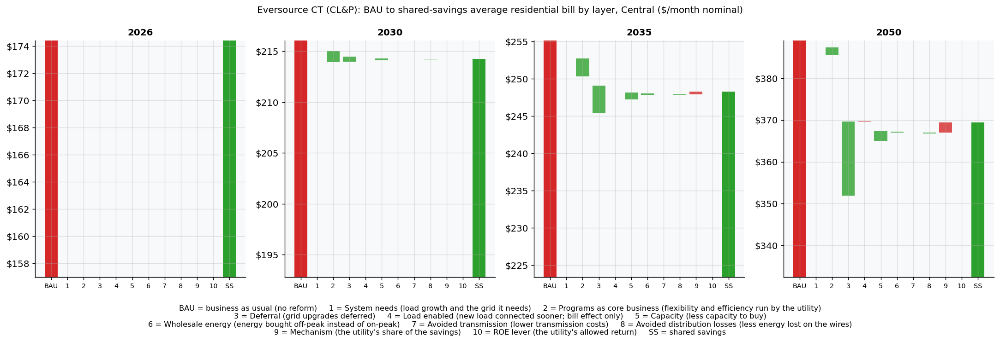

System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):


,Central
"Customer savings ($B, undiscounted nominal)",4.77
"Customer savings ($B, NPV 3%, 2026 $)",2.94
"of which efficiency energy ($B, undiscounted nominal)",3.19
"of which wholesale energy, load shifted ($B, undiscounted nominal)",0.10
"of which avoided transmission ($B, undiscounted nominal)",0.01
"of which avoided distribution losses ($B, undiscounted nominal)",0.08
"Lower share of zonal transmission costs ($B, undiscounted nominal)",0.75
"Cost shifted to other zone customers ($B, undiscounted nominal)",0.75
"of which ROE change, cost to customers ($B, undiscounted nominal)",-0.00
"Wires capex avoided or deferred ($B, undiscounted nominal)",4.25


Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):


,"Customer savings ($B, undiscounted nominal)","Customer savings ($B, NPV 3%, 2026 $)","Monthly bill 2035 ($, nominal)","Monthly bill 2050 ($, nominal)","Shared savings earnings ($B, undiscounted nominal)","Shared savings earnings ($B, NPV 3%, 2026 $)","Utility equity return ($B, undiscounted nominal)","Savings pool contribution ($B, undiscounted nominal)","Savings pool contribution ($B, NPV 3%, 2026 $)","Shared savings earnings attributable ($B, undiscounted nominal)","Shared savings earnings attributable ($B, NPV 3%, 2026 $)"
layer,,,,,,,,,,,
Programs as core business (flexibility and efficiency run by the utility),0.385,0.302,-2.436,-1.750,0.000,0.000,0.332,-2.808,-1.717,-0.842,-0.515
Deferral (grid upgrades deferred),4.040,2.395,-3.645,-17.679,0.000,0.000,-1.566,4.040,2.395,1.212,0.719
Load enabled (new load connected sooner; bill effect only),-0.043,-0.026,0.015,0.103,0.000,0.000,0.016,-0.043,-0.026,-0.013,-0.008
Capacity (less capacity to buy),0.877,0.539,-0.922,-2.336,0.000,0.000,0.000,0.877,0.539,0.263,0.162
Wholesale energy (energy bought off-peak instead of on-peak),0.104,0.066,-0.148,-0.215,0.000,0.000,0.000,0.104,0.066,0.031,0.020
Avoided transmission (lower transmission costs),0.012,0.007,-0.001,-0.054,0.000,0.000,0.000,0.012,0.007,0.004,0.002
Avoided distribution losses (less energy lost on the wires),0.077,0.049,-0.100,-0.170,0.000,0.000,0.000,0.077,0.049,0.023,0.015
objective,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Mechanism (the utility's share of the savings),-0.678,-0.394,0.339,2.447,0.678,0.394,0.000,0.000,0.000,0.000,0.000


ROE lever (Central = no change; outside the shared-savings pool):
  roe_delta -60 bp: customer savings $5.76B; 2050 monthly saving $22.24; SS equity return $14.89B vs BAU $17.09B
  roe_delta +60 bp: customer savings $3.79B; 2050 monthly saving $17.07; SS equity return $16.86B vs BAU $17.09B
Capacity formulation by scenario: avoided obligation (default) vs embedded (earlier formulation); capacity layer and customer savings $B undiscounted nominal (NPV 3%, 2026 $), monthly saving $/month nominal:


Capacity layer ($B, undiscounted nominal)  \
scenario  formulation                                                     
Cautious  embedded                                                 0.12   
          avoided_obligation                                       0.35   
Central   embedded                                                 0.36   
          avoided_obligation                                       0.88   
Ambitious embedded                                                 1.02   
          avoided_obligation                                       2.32   

                              Capacity layer ($B, NPV 3%, 2026 $)  \
scenario  formulation                                               
Cautious  embedded                                           0.08   
          avoided_obligation                                 0.21   
Central   embedded                                           0.23   
          avoided_obligation                                 0.54   
Ambitious embedded                                           0.65   
          avoided_obligation                                 1.44   

                              of which price suppression ($B, undiscounted nominal)  \
scenario  formulation                                                                 
Cautious  embedded                                                          0.0       
          avoided_obligation                                                0.0       
Central   embedded                                                          0.0       
          avoided_obligation                                                0.0       
Ambitious embedded                                                          0.0       
          avoided_obligation                                                0.0       

                              Customer savings ($B, undiscounted nominal)  \
scenario  formulation                                                       
Cautious  embedded                                                   1.73   
          avoided_obligation                                         1.89   
Central   embedded                                                   4.41   
          avoided_obligation                                         4.77   
Ambitious embedded                                                   9.15   
          avoided_obligation                                        10.06   

                              Customer savings ($B, NPV 3%, 2026 $)  \
scenario  formulation                                                 
Cautious  embedded                                             1.08   
          avoided_obligation                                   1.18   
Central   embedded                                             2.72   
          avoided_obligation                                   2.94   
Ambitious embedded                                             5.63   
          avoided_obligation                                   6.18   

                              Monthly saving 2035 ($, nominal)  \
scenario  formulation                                            
Cautious  embedded                                        3.03   
          avoided_obligation                              3.19   
Central   embedded                                        6.62   
          avoided_obligation                              6.90   
Ambitious embedded                                       12.70   
          avoided_obligation                             13.54   

                              Monthly saving 2050 ($, nominal)  \
scenario  formulation                                            
Cautious  embedded                                        7.27   
          avoided_obligation                              7.76   
Central   embedded                                       18.58   
          avoided_obligation                             19.66   
Ambitious embedded                                       36.10   
  

... (33 outputs left out)

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,19.0,19.0,0.0,0.0
2030,4.0,4.0,5.0,2.0
2035,0.0,0.0,4.0,0.0
2040,0.0,0.0,2.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 4.77; Customer savings ($B, NPV 3%, 2026 $): 2.94; of which efficiency energy ($B, undiscounted nominal): 3.19; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.10; of which avoided transmission ($B, undiscounted nominal): 0.01; of which avoided distribution losses ($B, undiscounted nominal): 0.08; Lower share of zonal transmission costs ($B, undiscounted nominal): 0.75; Cost shifted to other zone customers ($B, undiscounted nominal): 0.75; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 4.25; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 2.69; Reinforcement deferred (MW): 113.79; Capacity cost avoided ($B, undiscounted nominal): 0.87; Shared savings earnings ($B, undiscounted nominal): 0.68; Shared savings earnings ($B, NPV 3%, 2026 $): 0.39; MW connected sooner (peak year): 1.56; Upgrade Delay for Interconnection avoided (MW

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,19.0,19.0,0.0,0.0
2030,4.0,0.0,5.0,0.0
2035,0.0,0.0,4.0,0.0
2040,0.0,0.0,2.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 4.88; Customer savings ($B, NPV 3%, 2026 $): 3.00; of which efficiency energy ($B, undiscounted nominal): 3.19; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.10; of which avoided transmission ($B, undiscounted nominal): 0.01; of which avoided distribution losses ($B, undiscounted nominal): 0.08; Lower share of zonal transmission costs ($B, undiscounted nominal): 0.75; Cost shifted to other zone customers ($B, undiscounted nominal): 0.75; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 4.42; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 2.80; Reinforcement deferred (MW): 126.16; Capacity cost avoided ($B, undiscounted nominal): 0.87; Shared savings earnings ($B, undiscounted nominal): 0.72; Shared savings earnings ($B, NPV 3%, 2026 $): 0.42; MW connected sooner (peak year): 4.07; Upgrade Delay for Interconnection avoided (MW

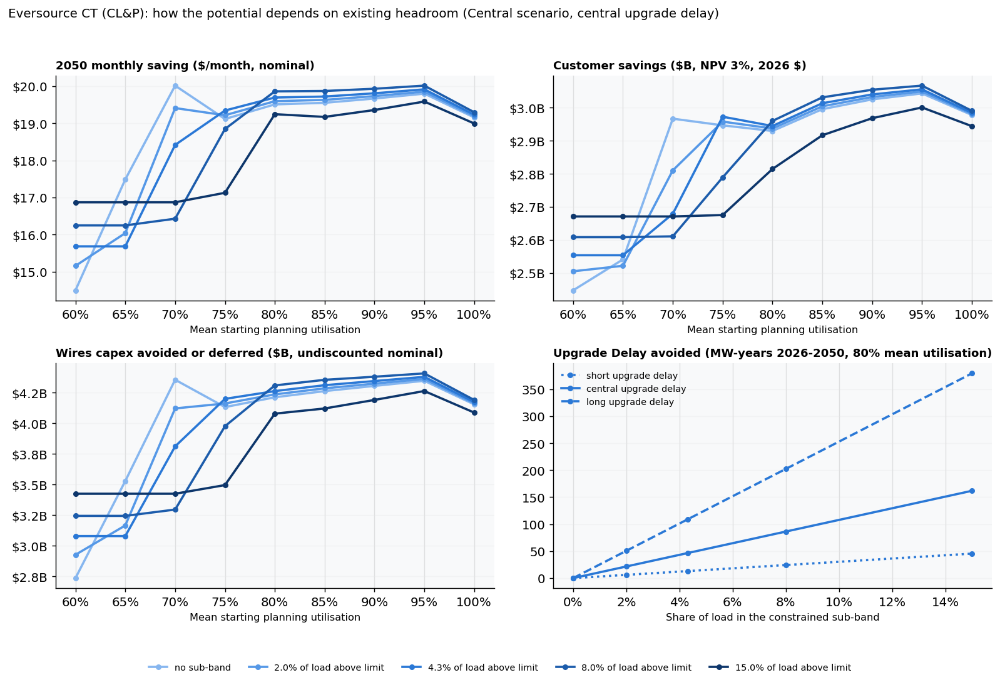

Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):


2050 monthly saving ($, nominal)  \
delay case mean utilisation sub-band share                                     
short      0.6              0.000                                      14.50   
                            0.020                                      15.29   
                            0.043                                      15.92   
                            0.080                                      16.59   
                            0.150                                      17.32   
...                                                                      ...   
long       1.0              0.000                                      19.16   
                            0.020                                      19.24   
                            0.043                                      19.34   
                            0.080                                      19.50   
                            0.150                                      19.36   

                                            Customer savings ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                
short      0.6              0.000                                                  3.91   
                            0.020                                                  4.05   
                            0.043                                                  4.17   
                            0.080                                                  4.30   
                            0.150                                                  4.45   
...                                                                                 ...   
long       1.0              0.000                                                  4.83   
                            0.020                                                  4.83   
                            0.043                                                  4.84   
                            0.080                                                  4.85   
                            0.150                                                  4.76   

                                            Customer savings ($B, NPV 3%, 2026 $)  \
delay case mean utilisation sub-band share                                          
short      0.6              0.000                                            2.45   
                            0.020                                            2.53   
                            0.043                                            2.59   
                            0.080                                            2.67   
                            0.150                                            2.76   
...                                                                           ...   
long       1.0              0.000                                            2.98   
                            0.020                                            2.98   
                            0.043                                            2.98   
                            0.080                                            2.99   
                            0.150                                            2.94   

                                            of which efficiency energy ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                          
short      0.6              0.000                                                        3.19       
                            0.020                                                        3.19       
                            0.043                                                        3.19       
                            0.080                                                        3.19       
                            0.150                                                        3.19       
...   


Value stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):


flexible kW (incremental)  cost $/kW-yr  \
scenario  year                                            
Cautious  2030                    26266.7          88.3   
          2035                    59100.0          99.9   
          2050                    86200.0         144.7   
Central   2030                   105822.2          66.2   
          2035                   335500.0         164.7   
          2050                   380700.0         234.5   
Ambitious 2030                   293733.3          40.1   
          2035                   855700.0         101.4   
          2050                   952800.0         145.9   

                capacity value $/kW-yr  deferral value $/kW-yr  \
scenario  year                                                   
Cautious  2030                    31.9                   128.6   
          2035                    36.1                   314.1   
          2050                    52.3                  1036.6   
Central   2030                    24.7                    75.8   
          2035                    28.8                   161.1   
          2050                    42.5                   676.7   
Ambitious 2030                    27.8                    49.5   
          2035                    35.1                   105.2   
          2050                    52.3                   483.1   

                load-enabled value $/kW-yr  total value $/kW-yr  
scenario  year                                                   
Cautious  2030                        10.1                170.6  
          2035                         4.6                354.8  
          2050                         0.7               1089.6  
Central   2030                         9.1                109.5  
          2035                         5.2                195.1  
          2050                         0.5                719.8  
Ambitious 2030                         6.5                 83.9  
          2035                         2.1                142.4  
          2050                         0.0                535.4

Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; Central assumption $232/kW-yr):


  average bill equal to BAU in 2035: $2,023/kW-yr  (bisection)


  average bill equal to BAU in 2050: $1,955/kW-yr  (bisection)


  cumulative 2026-2050 saving = 0 at 3% NPV: $1,879/kW-yr  (bisection)


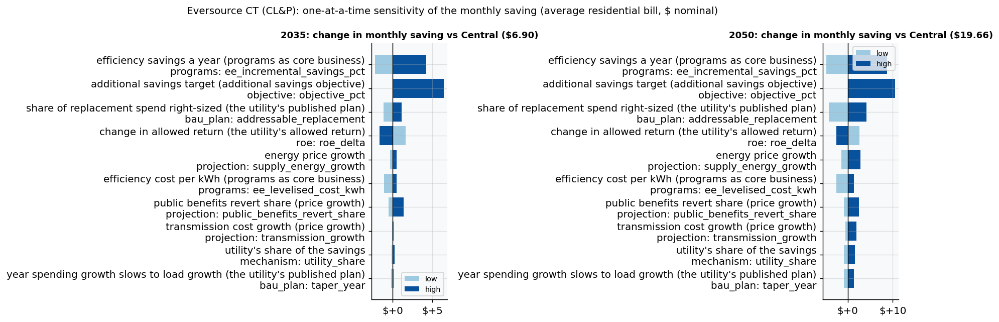

Top three assumptions by 2050 swing in the saving: programs/ee_incremental_savings_pct ($13.44); objective/objective_pct ($10.55); bau_plan/addressable_replacement ($8.33)

Cumulative saving per residential customer, 2026-2050, Central (average residential bill):
  undiscounted nominal $: $2,801
  NPV 3% (2026 $): $1,727
  NPV 7% (2026 $): $964


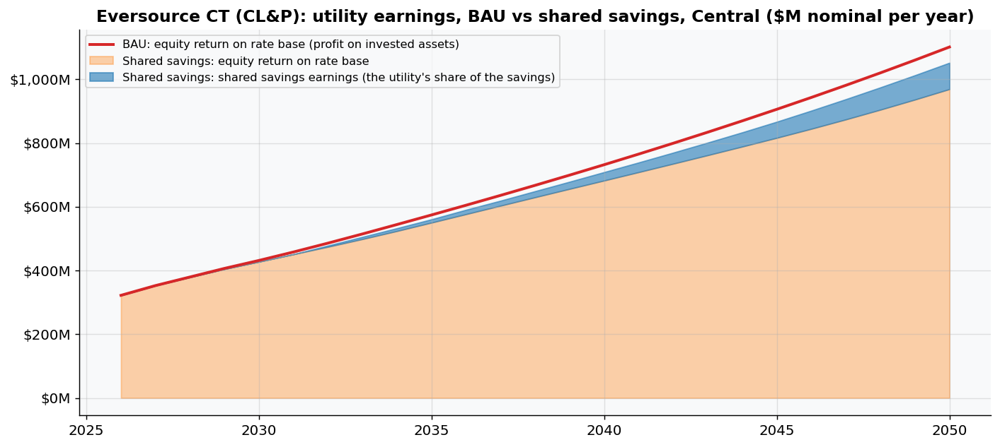

Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):


,BAU equity return,SS equity return,SS shared savings earnings,SS total earnings
$M,17093.0,15874.0,678.0,16552.0



United Illuminating: layered projection, Central scenario ($/month nominal per residential customer)
  Year-zero carve_out: Capacity (carved out: gsc 100%) $5.29/month
  Today's core-business program spend: $29.2M/yr (clm: 29.2 (derived: rate x total sales)); residential allocation factor 1.00

AVERAGE residential bill (usage lowered by EE), by category ($/month nominal):


,,Distribution base (delivery charges set in the rate case),Distribution riders (delivery charges outside the base rate),Programs (program surcharges),Supply energy (the electricity itself),Capacity (power available at peak),Transmission (high-voltage lines),Taxes and fees,total
year,case,,,,,,,,
2026,BAU,92.45,-2.22,-24.10,78.36,5.29,34.11,0.0,183.88
2030,BAU,97.13,-2.34,-15.56,86.49,7.88,40.84,0.0,214.44
2035,BAU,103.32,-2.49,-17.61,97.86,8.91,48.28,0.0,238.27
2050,BAU,129.18,-3.11,-25.50,141.73,12.91,69.92,0.0,325.12
2026,Shared savings,92.45,-2.22,-24.10,78.36,5.29,34.11,0.0,183.88
2030,Shared savings,97.06,-2.33,-14.57,85.15,7.66,40.24,0.0,213.21
2035,Shared savings,102.47,-2.45,-13.99,93.87,7.85,46.42,0.0,234.17
2050,Shared savings,124.17,-2.97,-17.64,135.96,10.58,67.23,0.0,317.32



benchmark-usage bill (700 kWh/month), by category ($/month nominal):


,,Distribution base (delivery charges set in the rate case),Distribution riders (delivery charges outside the base rate),Programs (program surcharges),Supply energy (the electricity itself),Capacity (power available at peak),Transmission (high-voltage lines),Taxes and fees,total
year,case,,,,,,,,
2026,BAU,92.45,-2.22,-24.10,78.36,5.29,34.11,0.0,183.88
2030,BAU,97.13,-2.34,-15.56,86.49,7.88,40.84,0.0,214.44
2035,BAU,103.32,-2.49,-17.61,97.86,8.91,48.28,0.0,238.27
2050,BAU,129.18,-3.11,-25.50,141.73,12.91,69.92,0.0,325.12
2026,Shared savings,92.45,-2.22,-24.10,78.36,5.29,34.11,0.0,183.88
2030,Shared savings,98.32,-2.37,-14.79,86.43,7.77,40.84,0.0,216.21
2035,Shared savings,105.97,-2.55,-14.55,97.62,8.16,48.28,0.0,242.93
2050,Shared savings,128.41,-3.09,-18.34,141.38,11.00,69.91,0.0,329.27


Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):


,BAU 2026,Shared savings 2026,BAU 2035,Shared savings 2035,BAU 2050,Shared savings 2050,"cum saving, undiscounted nominal $","cum saving, NPV 3% (2026 $)","cum saving, NPV 7% (2026 $)"
scenario,,,,,,,,,
Cautious,183.9,183.9,238.3,236.6,325.1,323.1,364.8,240.2,147.2
Central,183.9,183.9,238.3,234.2,325.1,317.3,1258.4,796.2,461.0
Ambitious,183.9,183.9,238.3,229.2,325.1,306.1,3044.1,1912.9,1096.9


Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; system needs applies to both cases so its bar is zero):


,BAU,System needs (load growth and the grid it needs),Programs as core business (flexibility and efficiency run by the utility),Deferral (grid upgrades deferred),Load enabled (new load connected sooner; bill effect only),Capacity (less capacity to buy),Wholesale energy (energy bought off-peak instead of on-peak),Avoided transmission (lower transmission costs),Avoided distribution losses (less energy lost on the wires),objective,Mechanism (the utility's share of the savings),ROE lever (the utility's allowed return),Shared savings
2026,183.88,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,183.88
2030,214.44,0.0,-0.71,-0.21,-0.03,-0.20,-0.04,0.00,-0.03,0.0,0.0,0.0,213.21
2035,238.27,0.0,-1.41,-1.37,-0.02,-1.01,-0.17,-0.00,-0.10,0.0,0.0,0.0,234.17
2050,325.12,0.0,0.47,-5.63,0.03,-2.25,-0.25,-0.01,-0.15,0.0,0.0,0.0,317.32


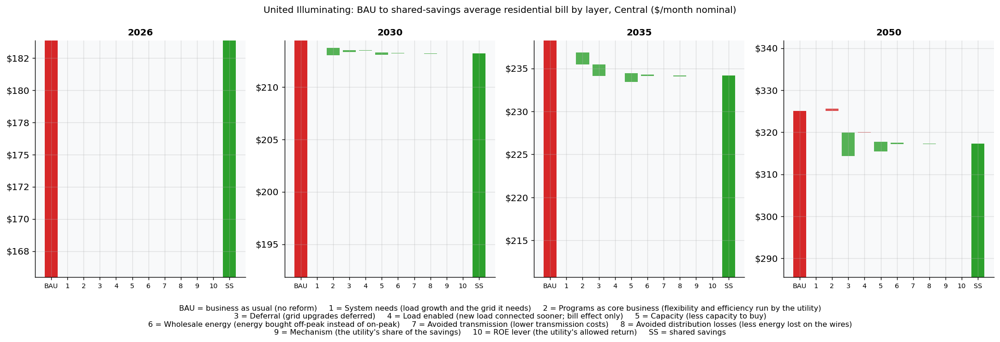

System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):


,Central
"Customer savings ($B, undiscounted nominal)",0.67
"Customer savings ($B, NPV 3%, 2026 $)",0.42
"of which efficiency energy ($B, undiscounted nominal)",0.71
"of which wholesale energy, load shifted ($B, undiscounted nominal)",0.03
"of which avoided transmission ($B, undiscounted nominal)",0.00
"of which avoided distribution losses ($B, undiscounted nominal)",0.02
"Lower share of zonal transmission costs ($B, undiscounted nominal)",0.29
"Cost shifted to other zone customers ($B, undiscounted nominal)",0.29
"of which ROE change, cost to customers ($B, undiscounted nominal)",-0.00
"Wires capex avoided or deferred ($B, undiscounted nominal)",0.37


Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):


,"Customer savings ($B, undiscounted nominal)","Customer savings ($B, NPV 3%, 2026 $)","Monthly bill 2035 ($, nominal)","Monthly bill 2050 ($, nominal)","Shared savings earnings ($B, undiscounted nominal)","Shared savings earnings ($B, NPV 3%, 2026 $)","Utility equity return ($B, undiscounted nominal)","Savings pool contribution ($B, undiscounted nominal)","Savings pool contribution ($B, NPV 3%, 2026 $)","Shared savings earnings attributable ($B, undiscounted nominal)","Shared savings earnings attributable ($B, NPV 3%, 2026 $)"
layer,,,,,,,,,,,
Programs as core business (flexibility and efficiency run by the utility),-0.027,0.000,-1.412,0.471,0.0,0.0,0.081,-0.740,-0.453,0.0,0.0
Deferral (grid upgrades deferred),0.363,0.216,-1.374,-5.631,0.0,0.0,-0.132,0.363,0.216,-0.0,-0.0
Load enabled (new load connected sooner; bill effect only),-0.004,-0.002,-0.017,0.030,0.0,0.0,0.001,-0.004,-0.002,0.0,0.0
Capacity (less capacity to buy),0.284,0.175,-1.013,-2.255,0.0,0.0,0.000,0.284,0.175,-0.0,-0.0
Wholesale energy (energy bought off-peak instead of on-peak),0.032,0.020,-0.175,-0.253,0.0,0.0,0.000,0.032,0.020,-0.0,-0.0
Avoided transmission (lower transmission costs),0.001,0.000,-0.000,-0.008,0.0,0.0,0.000,0.001,0.000,-0.0,-0.0
Avoided distribution losses (less energy lost on the wires),0.021,0.013,-0.105,-0.153,0.0,0.0,0.000,0.021,0.013,-0.0,-0.0
objective,0.000,0.000,0.000,0.000,0.0,0.0,0.000,0.000,0.000,-0.0,-0.0
Mechanism (the utility's share of the savings),0.000,0.000,0.000,0.000,0.0,0.0,0.000,0.000,0.000,-0.0,-0.0


ROE lever (Central = no change; outside the shared-savings pool):
  roe_delta -60 bp: customer savings $0.79B; 2050 monthly saving $8.84; SS equity return $1.95B vs BAU $2.12B
  roe_delta +60 bp: customer savings $0.55B; 2050 monthly saving $6.76; SS equity return $2.19B vs BAU $2.12B
Capacity formulation by scenario: avoided obligation (default) vs embedded (earlier formulation); capacity layer and customer savings $B undiscounted nominal (NPV 3%, 2026 $), monthly saving $/month nominal:


Capacity layer ($B, undiscounted nominal)  \
scenario  formulation                                                     
Cautious  embedded                                                 0.02   
          avoided_obligation                                       0.05   
Central   embedded                                                 0.12   
          avoided_obligation                                       0.28   
Ambitious embedded                                                 0.31   
          avoided_obligation                                       0.69   

                              Capacity layer ($B, NPV 3%, 2026 $)  \
scenario  formulation                                               
Cautious  embedded                                           0.01   
          avoided_obligation                                 0.03   
Central   embedded                                           0.08   
          avoided_obligation                                 0.18   
Ambitious embedded                                           0.20   
          avoided_obligation                                 0.43   

                              of which price suppression ($B, undiscounted nominal)  \
scenario  formulation                                                                 
Cautious  embedded                                                          0.0       
          avoided_obligation                                                0.0       
Central   embedded                                                          0.0       
          avoided_obligation                                                0.0       
Ambitious embedded                                                          0.0       
          avoided_obligation                                                0.0       

                              Customer savings ($B, undiscounted nominal)  \
scenario  formulation                                                       
Cautious  embedded                                                   0.12   
          avoided_obligation                                         0.16   
Central   embedded                                                   0.51   
          avoided_obligation                                         0.67   
Ambitious embedded                                                   1.50   
          avoided_obligation                                         1.77   

                              Customer savings ($B, NPV 3%, 2026 $)  \
scenario  formulation                                                 
Cautious  embedded                                             0.08   
          avoided_obligation                                   0.11   
Central   embedded                                             0.32   
          avoided_obligation                                   0.42   
Ambitious embedded                                             0.94   
          avoided_obligation                                   1.10   

                              Monthly saving 2035 ($, nominal)  \
scenario  formulation                                            
Cautious  embedded                                        1.55   
          avoided_obligation                              1.65   
Central   embedded                                        3.68   
          avoided_obligation                              4.10   
Ambitious embedded                                        8.17   
          avoided_obligation                              9.12   

                              Monthly saving 2050 ($, nominal)  \
scenario  formulation                                            
Cautious  embedded                                        1.70   
          avoided_obligation                              2.00   
Central   embedded                                        6.42   
          avoided_obligation                              7.80   
Ambitious embedded                                       16.87   
  

... (33 outputs left out)

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,5.0,5.0,0.0,0.0
2030,0.0,0.0,3.0,2.0
2035,0.0,0.0,1.0,0.0
2040,0.0,0.0,1.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 0.67; Customer savings ($B, NPV 3%, 2026 $): 0.42; of which efficiency energy ($B, undiscounted nominal): 0.71; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.03; of which avoided transmission ($B, undiscounted nominal): 0.00; of which avoided distribution losses ($B, undiscounted nominal): 0.02; Lower share of zonal transmission costs ($B, undiscounted nominal): 0.29; Cost shifted to other zone customers ($B, undiscounted nominal): 0.29; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 0.37; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 0.23; Reinforcement deferred (MW): 46.35; Capacity cost avoided ($B, undiscounted nominal): 0.28; Shared savings earnings ($B, undiscounted nominal): 0.00; Shared savings earnings ($B, NPV 3%, 2026 $): 0.00; MW connected sooner (peak year): 0.47; Upgrade Delay for Interconnection avoided (MW-

,BAU MW above planning limit,SS MW above planning limit,BAU MW waiting for upgrade,SS MW waiting for upgrade
year,,,,
2026,5.0,5.0,0.0,0.0
2030,0.0,0.0,3.0,0.0
2035,0.0,0.0,1.0,0.0
2040,0.0,0.0,1.0,0.0
2050,0.0,0.0,0.0,0.0


  Customer savings ($B, undiscounted nominal): 0.68; Customer savings ($B, NPV 3%, 2026 $): 0.43; of which efficiency energy ($B, undiscounted nominal): 0.71; of which wholesale energy, load shifted ($B, undiscounted nominal): 0.03; of which avoided transmission ($B, undiscounted nominal): 0.00; of which avoided distribution losses ($B, undiscounted nominal): 0.02; Lower share of zonal transmission costs ($B, undiscounted nominal): 0.29; Cost shifted to other zone customers ($B, undiscounted nominal): 0.29; of which ROE change, cost to customers ($B, undiscounted nominal): -0.00; Wires capex avoided or deferred ($B, undiscounted nominal): 0.38; Wires capex avoided or deferred ($B, NPV 3%, 2026 $): 0.24; Reinforcement deferred (MW): 50.32; Capacity cost avoided ($B, undiscounted nominal): 0.28; Shared savings earnings ($B, undiscounted nominal): 0.00; Shared savings earnings ($B, NPV 3%, 2026 $): 0.00; MW connected sooner (peak year): 2.25; Upgrade Delay for Interconnection avoided (MW-

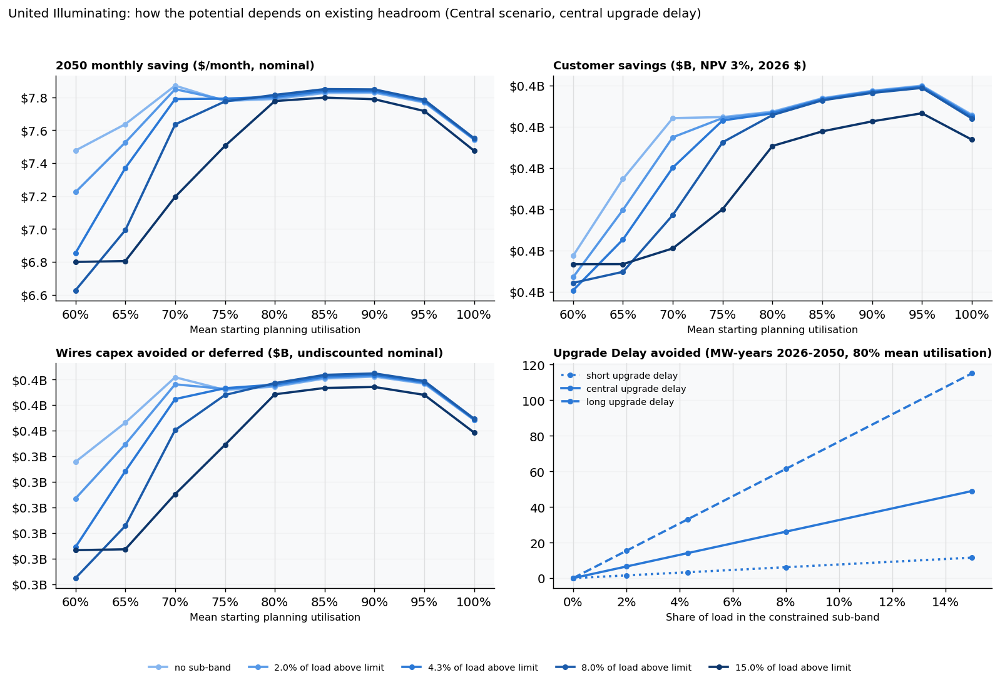

Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):


2050 monthly saving ($, nominal)  \
delay case mean utilisation sub-band share                                     
short      0.6              0.000                                       7.48   
                            0.020                                       7.26   
                            0.043                                       6.93   
                            0.080                                       6.74   
                            0.150                                       6.96   
...                                                                      ...   
long       1.0              0.000                                       7.54   
                            0.020                                       7.60   
                            0.043                                       7.66   
                            0.080                                       7.76   
                            0.150                                       7.87   

                                            Customer savings ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                
short      0.6              0.000                                                  0.61   
                            0.020                                                  0.61   
                            0.043                                                  0.61   
                            0.080                                                  0.61   
                            0.150                                                  0.63   
...                                                                                 ...   
long       1.0              0.000                                                  0.67   
                            0.020                                                  0.67   
                            0.043                                                  0.67   
                            0.080                                                  0.66   
                            0.150                                                  0.65   

                                            Customer savings ($B, NPV 3%, 2026 $)  \
delay case mean utilisation sub-band share                                          
short      0.6              0.000                                            0.39   
                            0.020                                            0.39   
                            0.043                                            0.39   
                            0.080                                            0.39   
                            0.150                                            0.40   
...                                                                           ...   
long       1.0              0.000                                            0.42   
                            0.020                                            0.42   
                            0.043                                            0.42   
                            0.080                                            0.42   
                            0.150                                            0.41   

                                            of which efficiency energy ($B, undiscounted nominal)  \
delay case mean utilisation sub-band share                                                          
short      0.6              0.000                                                        0.71       
                            0.020                                                        0.71       
                            0.043                                                        0.71       
                            0.080                                                        0.71       
                            0.150                                                        0.71       
...   


Value stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):


flexible kW (incremental)  cost $/kW-yr  \
scenario  year                                            
Cautious  2030                     2222.2          88.3   
          2035                     5000.0          99.9   
          2050                    10100.0         144.7   
Central   2030                    39422.2          66.2   
          2035                   117000.0         149.7   
          2050                   141600.0         215.1   
Ambitious 2030                    96000.0          40.5   
          2035                   272500.0          96.8   
          2050                   327400.0         139.8   

                capacity value $/kW-yr  deferral value $/kW-yr  \
scenario  year                                                   
Cautious  2030                    31.9                    81.9   
          2035                    36.1                   173.6   
          2050                    52.3                   523.2   
Central   2030                    24.9                    24.2   
          2035                    30.3                    48.2   
          2050                    46.7                   192.1   
Ambitious 2030                    26.4                    16.2   
          2035                    33.7                    35.6   
          2050                    53.7                   159.8   

                load-enabled value $/kW-yr  total value $/kW-yr  
scenario  year                                                   
Cautious  2030                        27.5                141.4  
          2035                         7.2                216.9  
          2050                         0.0                575.5  
Central   2030                         7.3                 56.3  
          2035                         4.5                 83.1  
          2050                         0.0                238.9  
Ambitious 2030                        10.1                 52.8  
          2035                         2.0                 71.3  
          2050                         0.0                213.5

Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; Central assumption $214/kW-yr):


  average bill equal to BAU in 2035: $900/kW-yr  (bisection)


  average bill equal to BAU in 2050: $674/kW-yr  (bisection)


  cumulative 2026-2050 saving = 0 at 3% NPV: $723/kW-yr  (bisection)


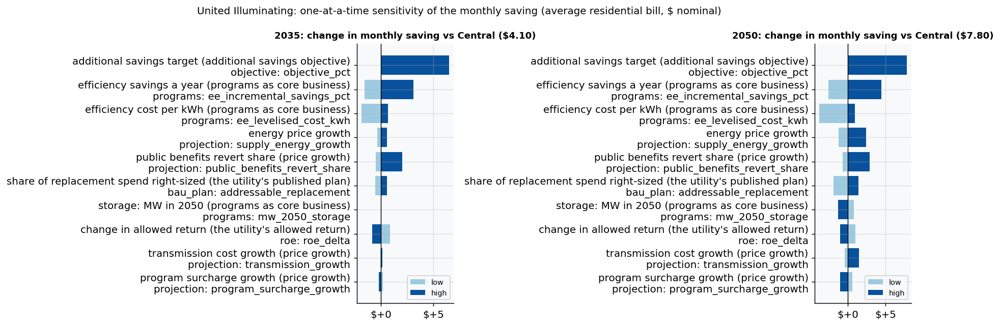

Top three assumptions by 2050 swing in the saving: objective/objective_pct ($7.89); programs/ee_incremental_savings_pct ($7.09); programs/ee_levelised_cost_kwh ($4.77)

Cumulative saving per residential customer, 2026-2050, Central (average residential bill):
  undiscounted nominal $: $1,258
  NPV 3% (2026 $): $796
  NPV 7% (2026 $): $461


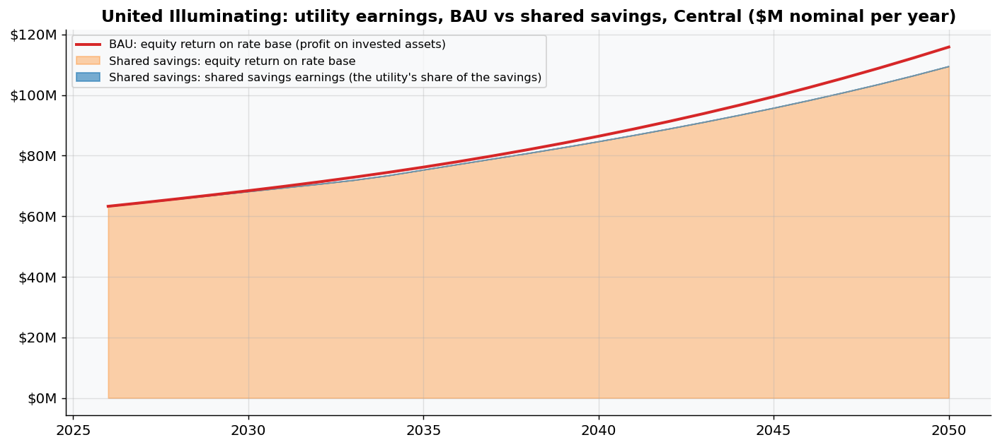

Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):


,BAU equity return,SS equity return,SS shared savings earnings,SS total earnings
$M,2119.0,2069.0,0.0,2069.0


In [24]:
# ============================================================
# SECTION 13: LAYERED BILL PROJECTION (engine/layers.py)
# Year zero = each utility's starting_bill (utilities/*.json). BAU vs SHARED
# SAVINGS 2026-2050 built from switchable layers; low / central / high values
# and the Cautious / Central / Ambitious scenarios are in the JSON
# 'forward_assumptions'. Independent of Sections 1-12 (v1.0 / CORRECTED
# unchanged). All $ nominal. Headline bill = AVERAGE residential bill
# (usage lowered by energy efficiency); the benchmark-usage bill is shown too.
# ============================================================
from engine import layers as LY

# Network what-if: set any input of the JSON 'network' block here (value, or
# 'low' / 'central' / 'high' where the JSON gives a range). Highest precedence:
# overrides the scenario 'network' values and the JSON for every run below.
# Example: {'subband_enabled': True, 'flex_targeting_enabled': True, 'mean_utilisation': 0.9}
NETWORK_OVERRIDES = {}
LY.NETWORK_OVERRIDES.clear()
LY.NETWORK_OVERRIDES.update(NETWORK_OVERRIDES)

os.makedirs('charts', exist_ok=True)
LAYER_LABEL = {'system_needs': 'System needs (load growth and the grid it needs)',
               'programs': 'Programs as core business (flexibility and efficiency run by the utility)',
               'deferral': 'Deferral (grid upgrades deferred)',
               'load_enabled': 'Load enabled (new load connected sooner; bill effect only)',
               'capacity': 'Capacity (less capacity to buy)',
               'wholesale_energy': 'Wholesale energy (energy bought off-peak instead of on-peak)',
               'transmission': 'Avoided transmission (lower transmission costs)',
               'losses': 'Avoided distribution losses (less energy lost on the wires)',
               'mechanism': "Mechanism (the utility's share of the savings)",
               'roe': "ROE lever (the utility's allowed return)"}
from engine.report import TIGHT_NETWORK, headroom_sweep_figure
CAT_LABEL = {'distribution_base': 'Distribution base (delivery charges set in the rate case)',
             'distribution_rider': 'Distribution riders (delivery charges outside the base rate)',
             'program_surcharge': 'Programs (program surcharges)', 'supply_energy': 'Supply energy (the electricity itself)',
             'capacity': 'Capacity (power available at peak)', 'transmission': 'Transmission (high-voltage lines)',
             'taxes_and_fees': 'Taxes and fees'}
LAYER_PLAIN = {'system_needs': 'load growth', 'programs': 'programs as core business', 'deferral': 'grid upgrades deferred',
               'load_enabled': 'new load connected sooner', 'capacity': 'capacity to buy', 'wholesale_energy': 'load shifting',
               'transmission': 'avoided transmission', 'losses': 'energy lost on the wires', 'objective': 'additional savings objective',
               'mechanism': "the utility's share of the savings", 'roe': "the utility's allowed return", 'network': 'grid',
               'bau_plan': "the utility's published plan", 'projection': 'price growth'}
PARAM_PLAIN = {'addressable_gridmod': 'share of grid-modernisation spend avoidable', 'addressable_growth': 'share of growth spend deferrable',
               'addressable_replacement': 'share of replacement spend right-sized', 'taper_year': 'year spending growth slows to load growth',
               'accr_der': 'how much other DER counts at peak', 'accr_dr': 'how much demand response counts at peak',
               'auction_lag_years': 'years before the capacity auction reflects it', 'local_coincidence': 'local peak alignment',
               'obligation_factor': 'capacity bought per MW of peak', 'price_growth': 'capacity price growth',
               'secondary_obligation_factor': 'second capacity requirement per MW of peak', 'locational_match': 'flexibility sited where needed',
               'connection_cost_kw': 'cost to connect new load', 'direct_uplift_pct': 'what-if capacity uplift',
               'enable_share': 'share of headroom used to connect load', 'incremental_om_mwh': 'running cost of new load served',
               'marginal_mult_energy': 'extra losses at the margin', 'marginal_mult_peak': 'extra losses at peak',
               'utility_share': "utility's share of the savings", 'backlog_clearance_pct': 'share of the overload backlog fixed a year',
               'max_build_pct': 'fastest grid build rate', 'planning_headroom': 'planning margin above demand',
               'reinforcement_lead_years': 'years to build an upgrade', 'upgrade_delay_large_years': 'wait for large loads to connect',
               'upgrade_delay_ordinary_years': 'wait for ordinary loads to connect', 'objective_pct': 'additional savings target',
               'ee_capitalised': 'efficiency spend capitalised', 'ee_incremental_savings_pct': 'efficiency savings a year',
               'ee_kw_per_mwh': 'peak saved per MWh of efficiency', 'ee_levelised_cost_kwh': 'efficiency cost per kWh',
               'flex_conn_energy_curtailed': 'energy curtailed on flexible connections', 'flex_conn_share': 'share of large loads on flexible connections',
               'program_surcharge_growth': 'program surcharge growth', 'supply_energy_growth': 'energy price growth',
               'transmission_growth': 'transmission cost growth', 'roe_delta': 'change in allowed return',
               'baseline_energy_growth': 'underlying load growth', 'dc_growth': 'data-centre growth', 'dc_load_factor': 'data-centre load factor',
               'dist_upgrade_cost_per_mw': 'cost of a grid upgrade per MW', 'electrification_growth': 'electrification growth',
               'peak_elasticity': 'peak growth per unit of energy growth', 'avoidable_share': 'share of transmission cost avoided',
               'spread_mwh': 'on-peak minus off-peak price', 'planning_lag_years': 'transmission planning lag',
               'load_driven_share': 'load-driven share of transmission', 'avoided_build_share': 'transmission build deferral realised'}
_TYPE = {'dr': 'demand response', 'ev': 'managed EV charging', 'storage': 'storage', 'der': 'other DER'}
_STEM = {'capitalised': 'spend capitalised', 'cost_kw_yr': 'cost per kW-year', 'derate': 'share counted at peak',
         'mw_2035': 'MW in 2035', 'mw_2050': 'MW in 2050', 'ramp_pct_peak': 'fastest growth a year', 'mwh_per_mw': 'MWh shifted per MW'}


def plain_param(name):
    """Plain name for a tornado input (label only)."""
    if name in PARAM_PLAIN:
        return PARAM_PLAIN[name]
    stem, _, typ = name.rpartition('_')
    return f"{_TYPE[typ]}: {_STEM[stem]}" if stem in _STEM and typ in _TYPE else name.replace('_', ' ')

layer_results = {}

for k in utilities_to_run:
    uj, p = UTILITIES[k], utility_data[k]
    name = uj['short_name']
    kwh = uj['starting_bill']['benchmark_kwh_month']
    run = LY.project_layers(uj, p, scenario='Central')
    layer_results[k] = run
    print(f"\n{'=' * 78}\n{name}: layered projection, Central scenario ($/month nominal per residential customer)\n{'=' * 78}")
    for d in run['starting_lines']:
        if d['origin'] != 'starting_bill':
            print(f"  Year-zero {d['origin']}: {d['name']} ${d['month']:.2f}/month")
    print(f"  Today's core-business program spend: ${run['program_spend0_m']:,.1f}M/yr "
          f"({'; '.join(f'{i}: {v:,.1f} ({h})' for i, v, h in run['program_spend0_parts']) or 'none'}); "
          f"residential allocation factor {run['residential_program_allocation']:.2f}")

    # 1. Bills by category: average residential bill (headline) and benchmark usage
    for measure, lbl in (('average', 'AVERAGE residential bill (usage lowered by EE)'),
                         ('benchmark', f'benchmark-usage bill ({kwh:,} kWh/month)')):
        print(f'\n{lbl}, by category ($/month nominal):')
        display(LY.bill_table(run, measure=measure).rename(columns=CAT_LABEL).round(2))

    # 2. Scenarios
    sc = LY.scenario_table(uj, p)
    print('Scenarios (average residential bill; cumulative saving per residential customer 2026-2050):')
    display(sc.round(1))

    # 3. Waterfall, average residential bill, Central
    wf = LY.waterfall(uj, p, measure='average')
    print('Waterfall, BAU to shared-savings AVERAGE residential bill ($/month nominal, Central; '
          'system needs applies to both cases so its bar is zero):')
    display(wf.rename(columns=LAYER_LABEL).round(2))
    fig, axes = plt.subplots(1, len(wf), figsize=(4.2 * len(wf), 5))
    steps = list(LAYER_LABEL)
    for ax, (y, row) in zip(axes, wf.iterrows()):
        level = row['BAU']
        ax.bar(0, row['BAU'], color=C['bau'])
        for i, l in enumerate(steps, start=1):
            v = row[l]
            ax.bar(i, v, bottom=level if v >= 0 else level + v, color=C['bau'] if v > 0 else C['shared'], alpha=0.8)
            level += v
        ax.bar(len(steps) + 1, row['Shared savings'], color=C['shared'])
        ax.set_xticks(range(len(steps) + 2))
        ax.set_xticklabels(['BAU'] + [str(i) for i in range(1, len(steps) + 1)] + ['SS'], fontsize=8)
        ax.set_ylim(bottom=min(row['BAU'], row['Shared savings']) * 0.9)
        ax.set_title(f'{y}', fontsize=11)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}'))
    fig.suptitle(f'{name}: BAU to shared-savings average residential bill by layer, Central ($/month nominal)', fontsize=11)
    plt.tight_layout()
    key = ['BAU = business as usual (no reform)'] + [f'{i} = {LAYER_LABEL[s]}' for i, s in enumerate(steps, start=1)] + ['SS = shared savings']
    fig.text(0.5, -0.02, '\n'.join('     '.join(key[j:j + 3]) for j in range(0, len(key), 3)), ha='center', va='top', fontsize=9)
    plt.savefig(f'charts/layers_waterfall_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()

    # 3b. System-wide results and each layer's contribution (customer savings $B, monthly bill, shared savings earnings)
    print('System-wide results, Central (BAU minus shared savings, all customers; $B undiscounted nominal unless marked):')
    display(pd.Series(LY.system_summary(run)).round(2).to_frame('Central'))
    print("Contribution by layer, Central (added in waterfall order; earnings attributable computed with the mechanism on):")
    display(LY.layer_contributions(uj, p).rename(index=LAYER_LABEL).round(3))
    print('ROE lever (Central = no change; outside the shared-savings pool):')
    for lev in ('low', 'high'):
        r_roe = LY.project_layers(uj, p, overrides={('roe', 'roe_delta'): lev})
        print(f"  roe_delta {r_roe['assumptions']['roe']['roe_delta'] * 1e4:+.0f} bp: customer savings "
              f"${LY.system_summary(r_roe)['Customer savings ($B, undiscounted nominal)']:,.2f}B; 2050 monthly saving "
              f"${r_roe['bau']['avg_bill_total'].iloc[-1] - r_roe['ss']['avg_bill_total'].iloc[-1]:,.2f}; SS equity return "
              f"${r_roe['ss']['equity_return_m'].sum() / 1e3:,.2f}B vs BAU ${r_roe['bau']['equity_return_m'].sum() / 1e3:,.2f}B")

    # 3c. Capacity formulation: avoided obligation (default) vs embedded (earlier formulation; METHODOLOGY 3.6a)
    print('Capacity formulation by scenario: avoided obligation (default) vs embedded (earlier formulation); capacity '
          'layer and customer savings $B undiscounted nominal (NPV 3%, 2026 $), monthly saving $/month nominal:')
    display(LY.capacity_formulation_table(uj, p).round(2))

    # 3d. Customer allocation of the pool: residential vs non-residential (METHODOLOGY 3.10b)
    print('Customer allocation by scenario: by_sales (default), per_customer (EIA-861 counts), custom (0.5). Only the '
          'network revenue-requirement reduction net of earnings (positive years) is reallocated; costs and load-following '
          'savings stay by sales. $B undiscounted nominal (NPV 3%, 2026 $); $/month nominal:')
    display(LY.customer_allocation_table(uj, p).round(2))

    # 4a. Network capacity: headroom, load connected sooner, Upgrade Delay for Interconnection
    print('Network capacity, Central network and Tight network (low headroom, long lead time, low build rate):')
    for lbl, ov in (('Central network', {}), ('Tight network', TIGHT_NETWORK)):
        for scn in LY.SCENARIOS:
            ct = LY.connection_table(LY.project_layers(uj, p, scenario=scn, overrides=ov), (2035, 2050))
            print(f"  {lbl}, {scn}:")
            display(ct.round(2))
    print('Effective capacity uplift, derived vs direct mode (Central):')
    for mode in ('derived', 'direct'):
        ct = LY.connection_table(LY.project_layers(uj, p, uplift_mode=mode), (2035, 2050))
        print(f"  {mode}: " + ', '.join(f"{y} {ct.loc[y, 'Effective capacity uplift %']:.1%}" for y in ct.index))

    # 4b. MW by resource type
    print('\nFlexible MW by resource type (today = BAU; SS = shared savings) and EE peak MW, Central:')
    mt = LY.mw_table(run)
    display(mt.drop(columns='Flexible share of peak (SS)').T.round(0))
    print(f"  Flexible share of peak (SS): " + ', '.join(f"{y} {mt.loc[y, 'Flexible share of peak (SS)']:.1%}" for y in mt.index))

    # 4c. Loading bands: MW of load in constrained bands, and per-band detail
    print('\nLoading bands (starting loading = network peak / firm capacity): '
          + '; '.join(f"{b['name']} {b['loading0']:.0%} of capacity, {b['load_share']:.0%} of load" for b in run['bands']))
    for lbl, ov in (('Central network', {}), ('Tight network', TIGHT_NETWORK)):
        print(f'MW of network load in constrained bands, {lbl}, Central scenario:')
        display(LY.constrained_table(LY.project_layers(uj, p, overrides=ov)).round(0))
    print('Per-band detail, Tight network, Central scenario (MW):')
    display(LY.band_table(LY.project_layers(uj, p, overrides=TIGHT_NETWORK), (2035, 2050)).drop(columns='year', errors='ignore').round(2))

    # 4d. Access: faster connections, reported separately from the bill (benefit to the customers being connected)
    for lbl, ov, nw in (('Central network', {}, None),
                        ('Central network, sub-band on in every scenario', {}, {'subband_enabled': True}),
                        ('Tight network', TIGHT_NETWORK, None)):
        print(f'Access block, {lbl} (Upgrade Delay for Interconnection = years a new customer in a constrained area '
              'waits for the grid upgrade; connection cost avoided = upper bound at the distribution upgrade cost per MW; '
              '$M nominal undiscounted and NPV 3% 2026 $):')
        display(LY.access_table(uj, p, overrides=ov, network=nw).T.round(2))

    # 4e. Flexible MW: target path vs maximum annual growth per resource type
    print('Flexible MW, Central: target path vs ramp limit (observed program ramps):')
    display(LY.mw_path_table(uj, p).round(0))

    # 4f. Constrained sub-band: load above the planning limit (on in every scenario), and the Upgrade Delay
    #     for Interconnection
    nwp = LY.resolve(uj['forward_assumptions'])['network']
    print(f"\nConstrained sub-band, Central scenario: {nwp['subband_load_share']:.1%} of network load at "
          f"{nwp['subband_utilisation']:.1%} planning utilisation; operating limit {LY.operating_limit(nwp):.2f} x "
          "planning capacity. Existing load stays connected up to the operating limit; the backlog above the planning "
          f"limit is cleared at {nwp.get('backlog_clearance_pct', float('nan')):.0%} a year; new load waits the Upgrade "
          f"Delay for Interconnection ({nwp.get('upgrade_delay_ordinary_years')} yr ordinary, "
          f"{nwp.get('upgrade_delay_large_years')} yr large loads; build-rate priority "
          f"{'on' if nwp.get('constrained_build_priority') else 'off'}). MW above the planning limit and MW waiting for "
          "upgrade are separate measures.")
    print('Upgrade Delay for Interconnection by request year, Central:')
    display(LY.upgrade_delay_table(run).round(2))
    for lbl, nw in (('Central (sub-band on)', {'subband_enabled': True}),
                    ('Central, flexibility targeted', {'subband_enabled': True, 'flex_targeting_enabled': True})):
        r_sub = LY.project_layers(uj, p, network=nw)
        print(f'  {lbl}:')
        display(LY.constrained_table(r_sub)[['BAU MW above planning limit', 'SS MW above planning limit',
                                             'BAU MW waiting for upgrade', 'SS MW waiting for upgrade']].round(0))
        print('  ' + '; '.join(f'{k}: {v:,.2f}' for k, v in LY.system_summary(r_sub).items()))

    # 4g. Headroom sweep: mean starting utilisation x share of load in the sub-band x Upgrade Delay case
    #     (short / central / long), Central otherwise
    sw = LY.headroom_sweep(uj, p)
    fig = headroom_sweep_figure(sw, name)
    fig.savefig(f'charts/layers_headroom_sweep_{k.lower()}.png', bbox_inches='tight', dpi=130)
    display(fig)
    print('Headroom sweep, Central scenario ($ nominal; NPV at 3% in 2026 $):')
    display(sw.set_index(['delay case', 'mean utilisation', 'sub-band share']).round(2))

    # 5. Value stack and the cost at which flexibility pays for itself
    print('\nValue stack, flexible resources ($ per kW-year nominal; incremental nameplate kW):')
    vs_rows = []
    for scn in LY.SCENARIOS:
        v = LY.value_stack(LY.project_layers(uj, p, scenario=scn), p).assign(scenario=scn)
        vs_rows.append(v)
    display(pd.concat(vs_rows).reset_index().set_index(['scenario', 'year']).round(1))
    print('Cost at which flexibility pays for itself (MW-weighted flexible cost per kW-year, 2026 $; '
          f"Central assumption ${LY.weighted_flex_cost(uj):,.0f}/kW-yr):")
    for target in (2035, 2050, 'npv3'):
        cost, note = LY.flex_pays_cost(uj, p, target=target)
        lbl = f'average bill equal to BAU in {target}' if target != 'npv3' else 'cumulative 2026-2050 saving = 0 at 3% NPV'
        print(f"  {lbl}: " + (f'${cost:,.0f}/kW-yr' if cost is not None else 'n/a') + f'  ({note})')

    # 6. Tornado on the saving
    tor, cen = LY.tornado(uj, p, measure='average')
    top = tor.head(10).iloc[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, y in zip(axes, (2035, 2050)):
        labels = [f"{plain_param(r['assumption'])}"
                  + (f" ({LAYER_PLAIN.get(r['layer'], r['layer'])})"
                     if not (LAYER_PLAIN.get(r['layer'], '') in plain_param(r['assumption'])
                             or plain_param(r['assumption']) in LAYER_PLAIN.get(r['layer'], '')) else '')
                  + f"\n{r['layer']}: {r['assumption']}"
                  for _, r in top.iterrows()]
        ax.barh(labels, top[f'low {y}'], color='#9ecae1', label='low')
        ax.barh(labels, top[f'high {y}'], color='#08519c', label='high')
        ax.axvline(0, color='k', lw=0.8)
        ax.set_title(f'{y}: change in monthly saving vs Central (${cen[y]:,.2f})', fontsize=10)
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:+,.0f}'))
        ax.legend(fontsize=8)
    fig.suptitle(f'{name}: one-at-a-time sensitivity of the monthly saving (average residential bill, $ nominal)', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'charts/layers_tornado_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()
    print('Top three assumptions by 2050 swing in the saving: '
          + '; '.join(f"{r['layer']}/{r['assumption']} (${r['swing 2050']:,.2f})" for _, r in tor.head(3).iterrows()))

    # 7. Cumulative savings and utility earnings
    print('\nCumulative saving per residential customer, 2026-2050, Central (average residential bill):')
    for lbl, v in LY.cumulative_savings(run).items():
        print(f'  {lbl}: ${v:,.0f}')
    et = LY.earnings_table(run)
    fig, ax = plt.subplots(figsize=(11, 5))
    ax.plot(et['year'], et['BAU equity return'], color=C['bau'], lw=2.2, label='BAU: equity return on rate base (profit on invested assets)')
    ax.fill_between(et['year'], 0, et['SS equity return'], color=C['util_bau'], alpha=0.35,
                    label='Shared savings: equity return on rate base')
    ax.fill_between(et['year'], et['SS equity return'], et['SS total earnings'], color=C['util_shared'], alpha=0.6,
                    label="Shared savings: shared savings earnings (the utility's share of the savings)")
    ax.set_title(f'{name}: utility earnings, BAU vs shared savings, Central ($M nominal per year)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:,.0f}M'))
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.savefig(f'charts/layers_earnings_{k.lower()}.png', bbox_inches='tight', dpi=130)
    plt.show()
    print('Cumulative utility earnings 2026-2050 ($M, undiscounted nominal):')
    display(et[['BAU equity return', 'SS equity return', 'SS shared savings earnings', 'SS total earnings']]
            .sum().round(0).to_frame('$M').T)
